In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 64
GENERATOR_HIDDEN_DIM = 2048
DISCRIMINATOR_HIDDEN_DIM = 1024

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator hidden dimension: {GENERATOR_HIDDEN_DIM}")
print(f"Discriminator hidden dimension: {DISCRIMINATOR_HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator hidden dimension: 2048
Discriminator hidden dimension: 1024
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, GENERATOR_HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, DISCRIMINATOR_HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 10,132,240
Discriminator parameters: 2,904,065
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=2048, bias=True)
    (1): ReLU()
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): ReLU()
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): ReLU()
    (6): Linear(in_features=2048, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=1024, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=1024, out_features=1024, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=1024, out_features=1024, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=1024, out_features=1, bias=True)
    (7):

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.393058	G_loss: 0.693676
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.406495	G_loss: 0.724382
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.382169	G_loss: 0.706030
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.375270	G_loss: 0.711347
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.376864	G_loss: 0.717823
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.390503	G_loss: 0.723951
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.393649	G_loss: 0.707358
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.382824	G_loss: 0.720750
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.378660	G_loss: 0.748260
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.188123	G_loss: 0.839459
====> Epoch: 1 Train D_loss: 1.3904, Train G_loss: 0.7583
====> Epoch: 1 Val D_loss: 0.8934, Val G_loss: 0.9462
📈 Epoch 1 Summary:
   Train D Loss: 1.3904, Val D Loss: 0.8934
   Train G Loss: 0.7583, Val G Loss: 0.9462

📊 Epoch 2/100
------------------------

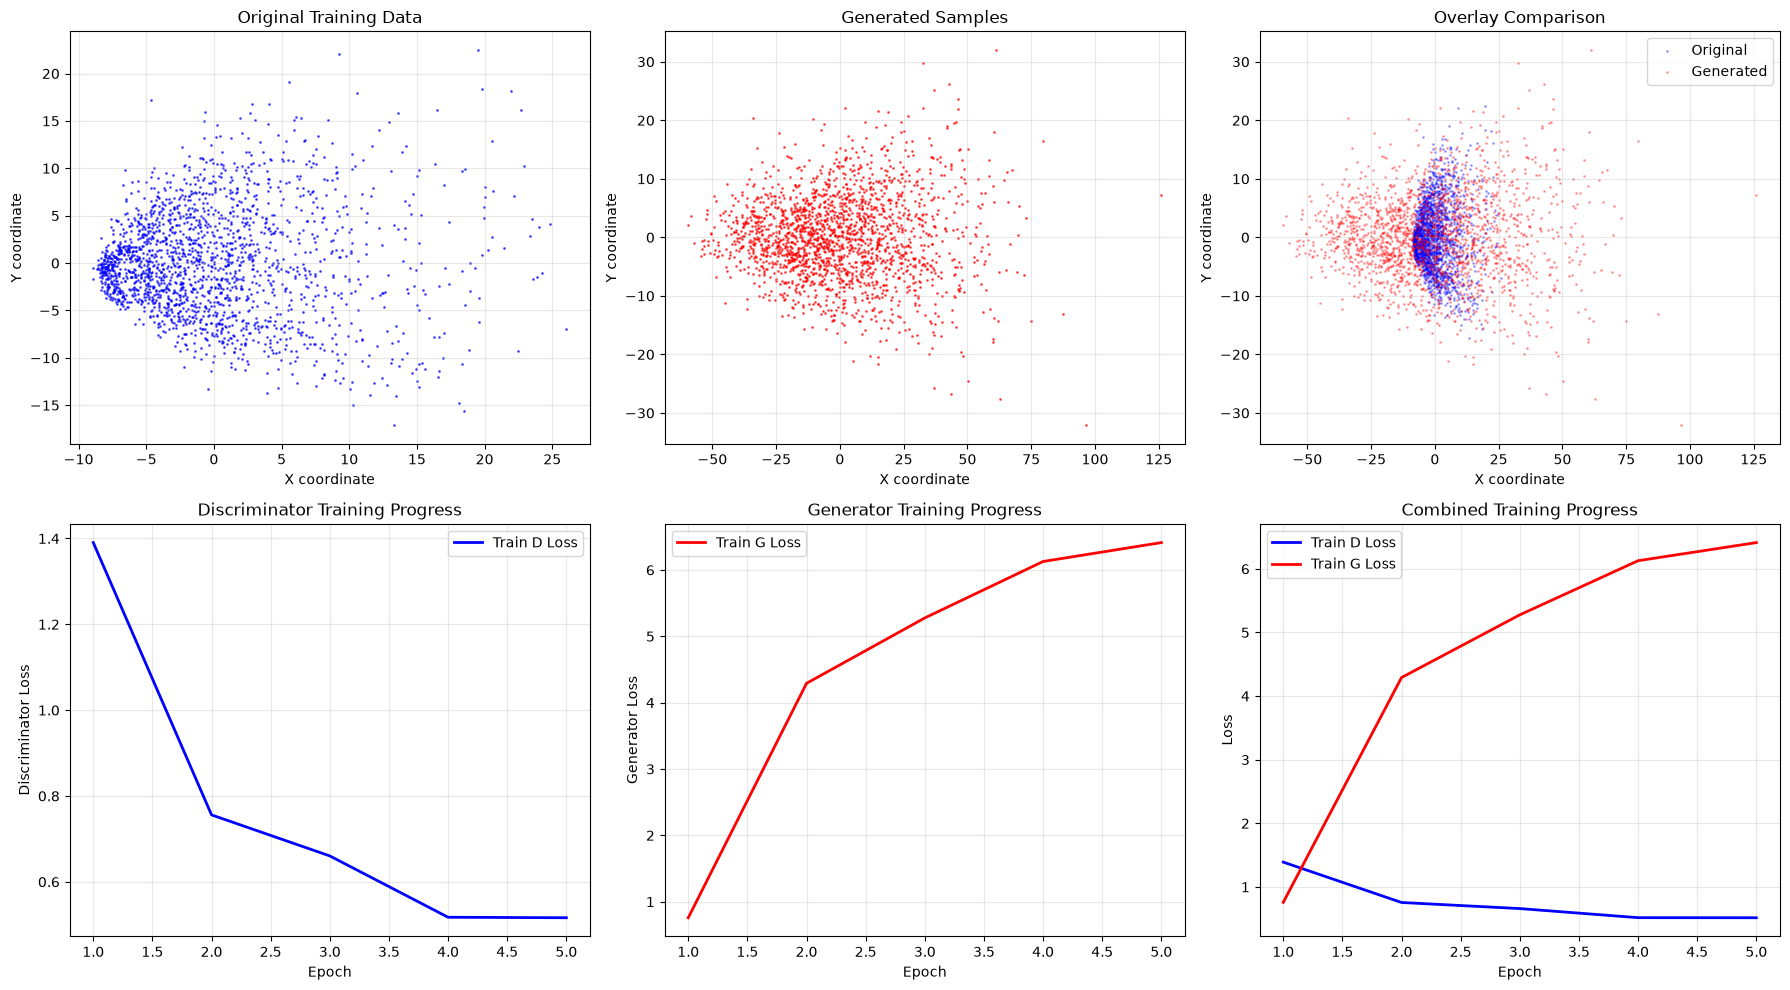

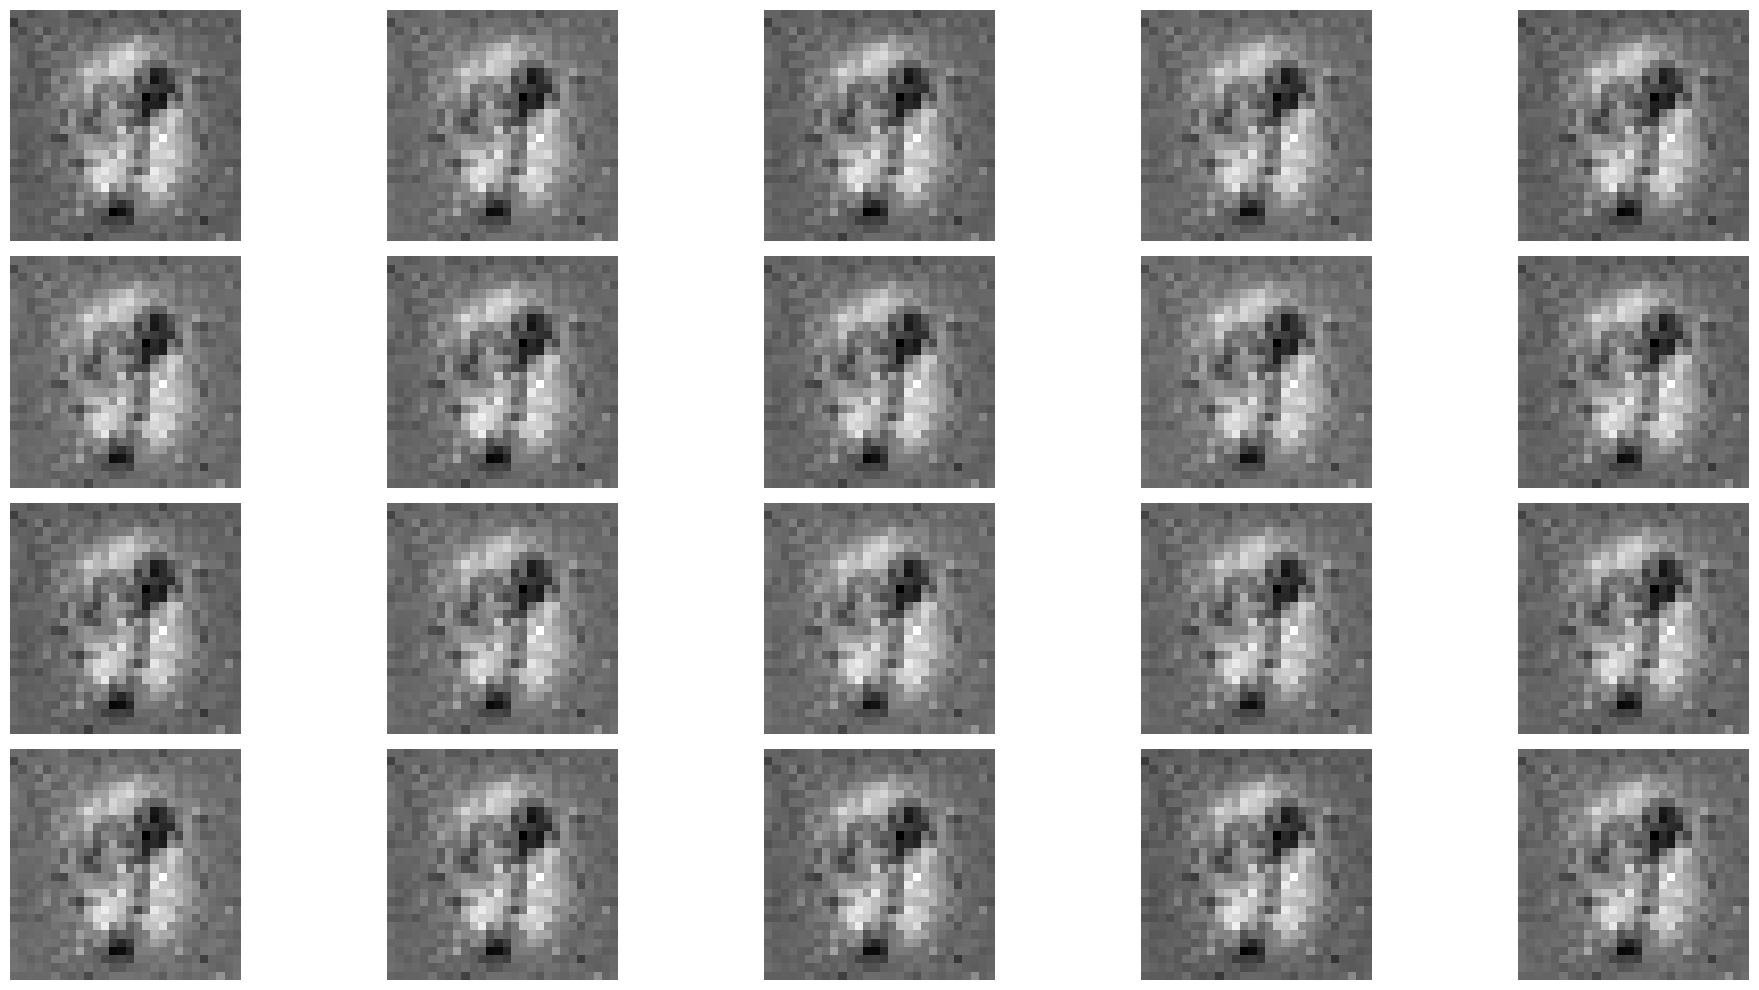

📈 Epoch 5 Summary:
   Train D Loss: 0.5162, Val D Loss: 5.1182
   Train G Loss: 6.4126, Val G Loss: 0.0274

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 5.033588	G_loss: 17.297703
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.165051	G_loss: 7.597087
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.531565	G_loss: 8.309870
Epoch: 6 [19200/60000 (32%)]	D_loss: 0.244731	G_loss: 11.205718
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.180240	G_loss: 4.095196
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.169482	G_loss: 3.736254
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.243596	G_loss: 8.878584
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.312121	G_loss: 5.060128
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.297812	G_loss: 7.694528
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.229173	G_loss: 11.983425
====> Epoch: 6 Train D_loss: 0.4340, Train G_loss: 6.5835
====> Epoch: 6 Val D_loss: 0.4119, Val G_loss: 3.2469
📈 Epoch 6 Summary:
   Train D Loss: 0.4340, Val D Loss: 0.4119
   Train G Loss: 6.5835, Val G Loss

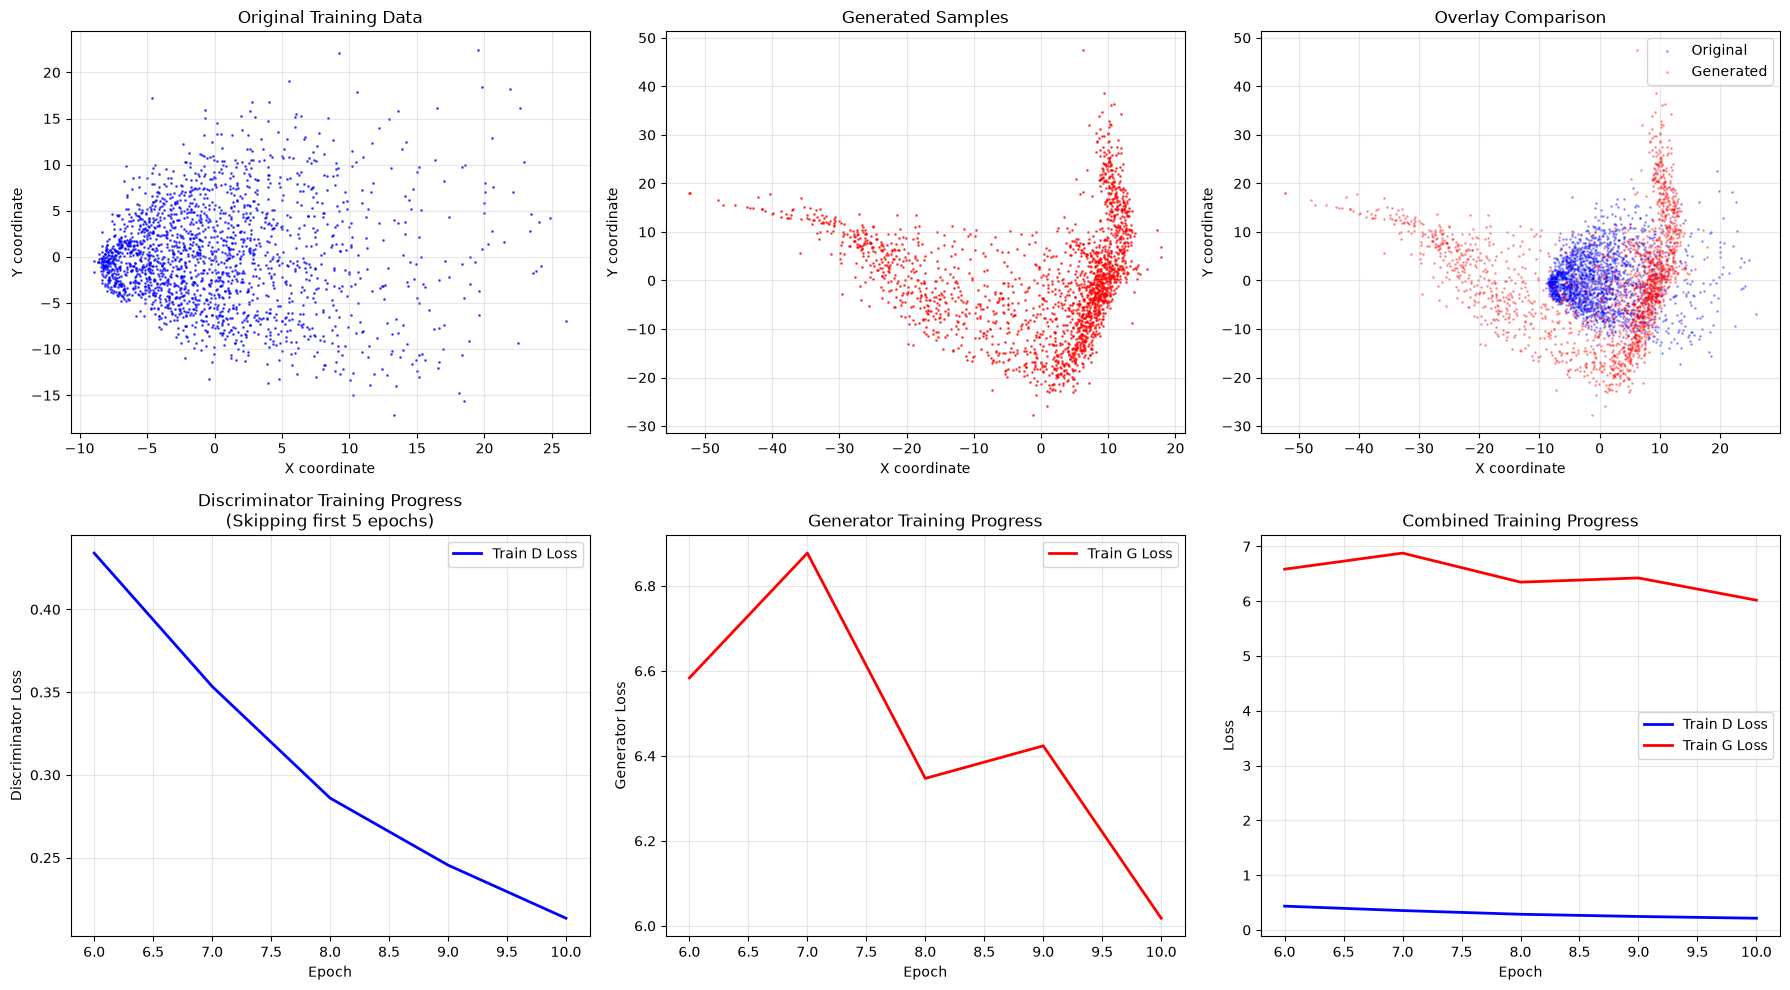

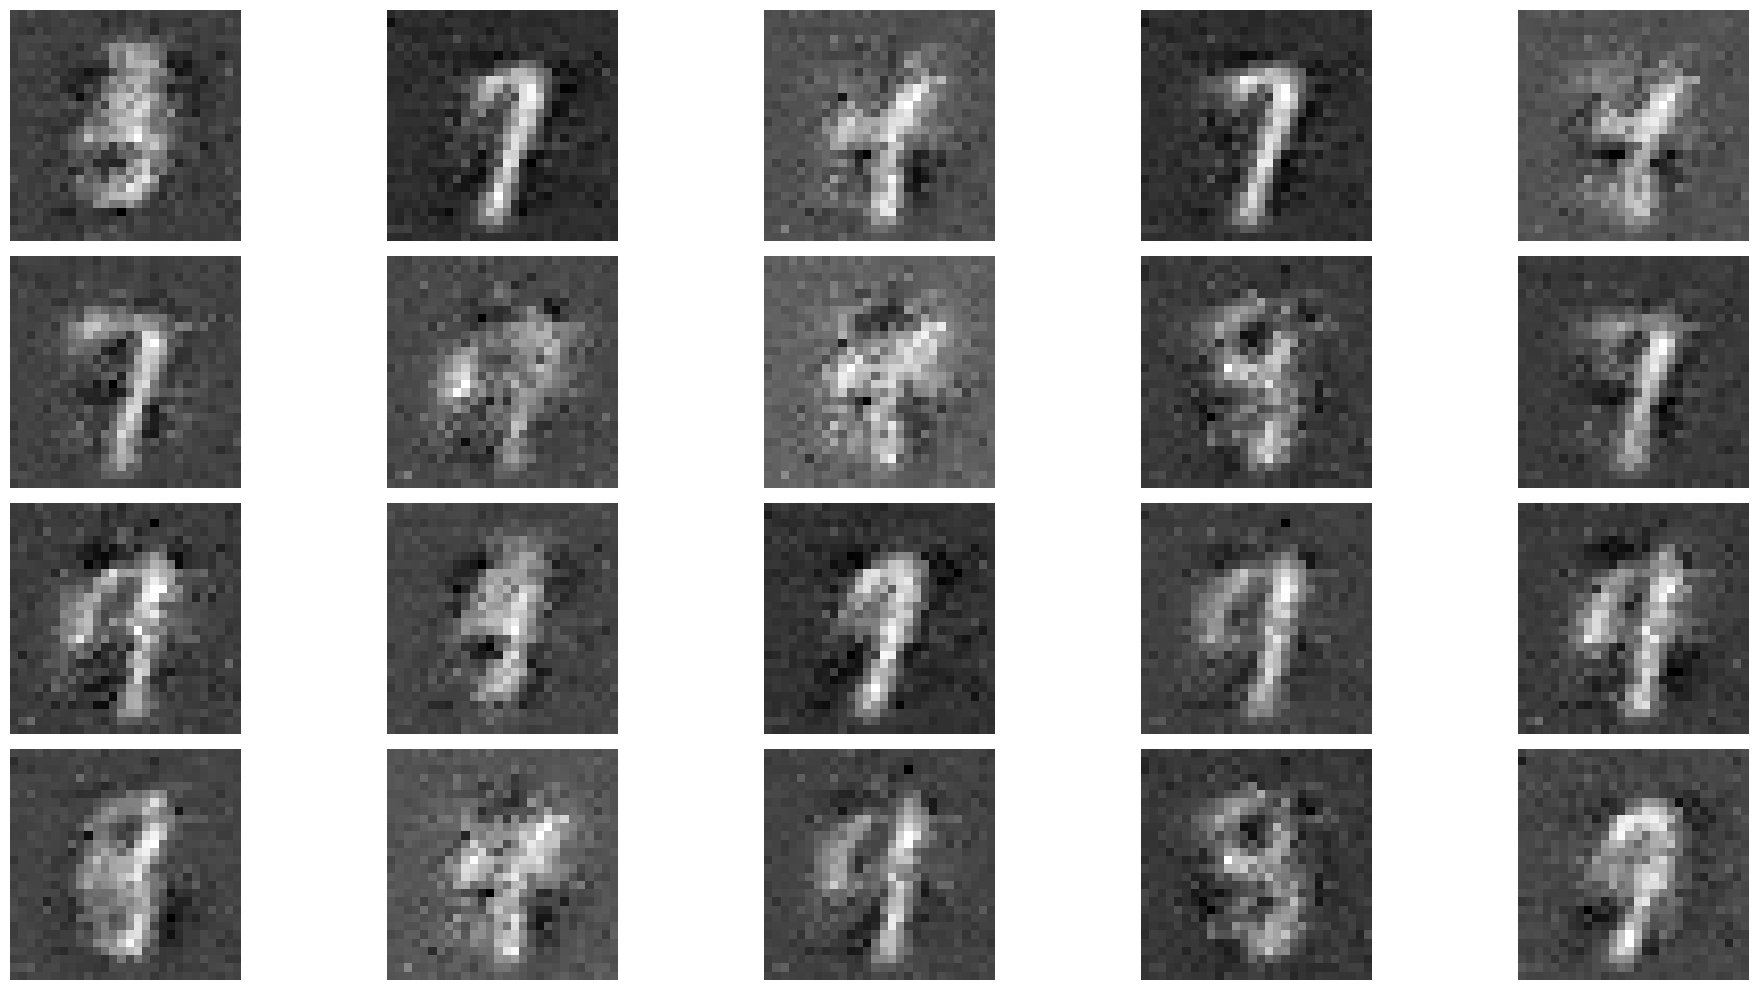

📈 Epoch 10 Summary:
   Train D Loss: 0.2134, Val D Loss: 0.1370
   Train G Loss: 6.0179, Val G Loss: 5.9191

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.122166	G_loss: 5.326714
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.192870	G_loss: 4.418014
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.176199	G_loss: 4.886597
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.113796	G_loss: 4.349958
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.123029	G_loss: 4.744637
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.052612	G_loss: 4.866959
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.055641	G_loss: 5.179275
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.159669	G_loss: 4.290697
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.247090	G_loss: 3.135662
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.171570	G_loss: 5.260805
====> Epoch: 11 Train D_loss: 0.2465, Train G_loss: 5.7710
====> Epoch: 11 Val D_loss: 0.2796, Val G_loss: 2.3692
📈 Epoch 11 Summary:
   Train D Loss: 0.2465, Val D Loss: 0.2796
   Train G Loss: 5.7710

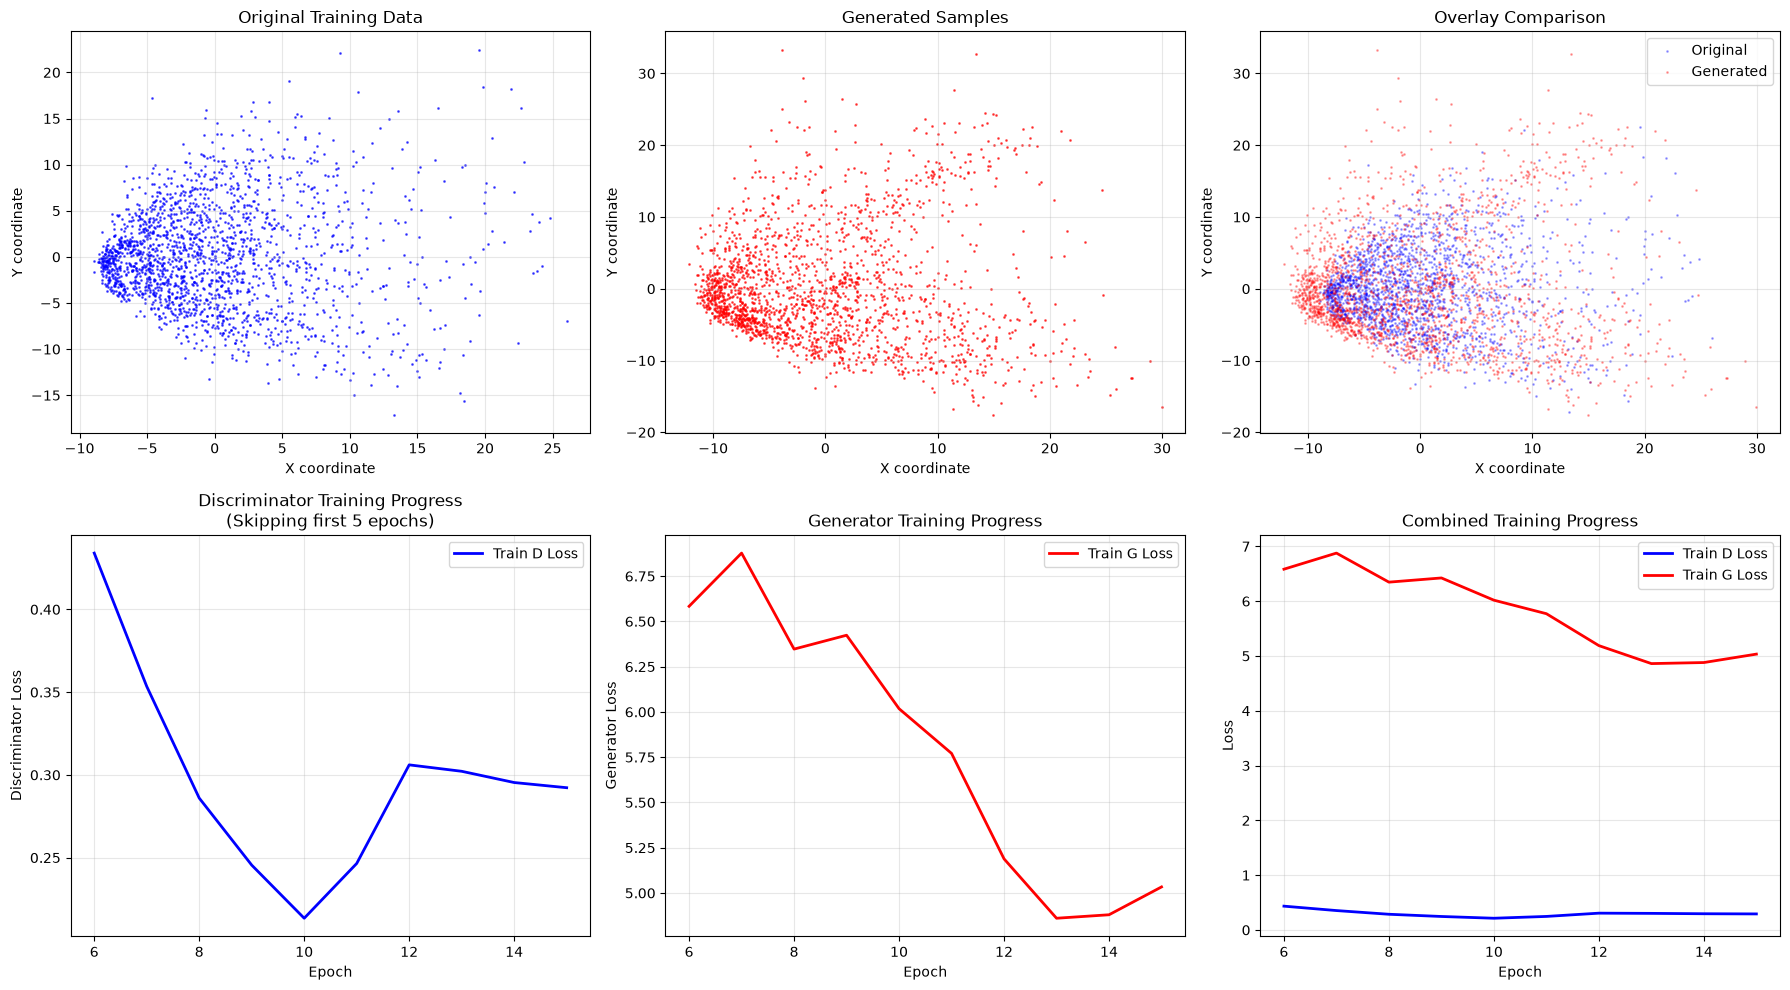

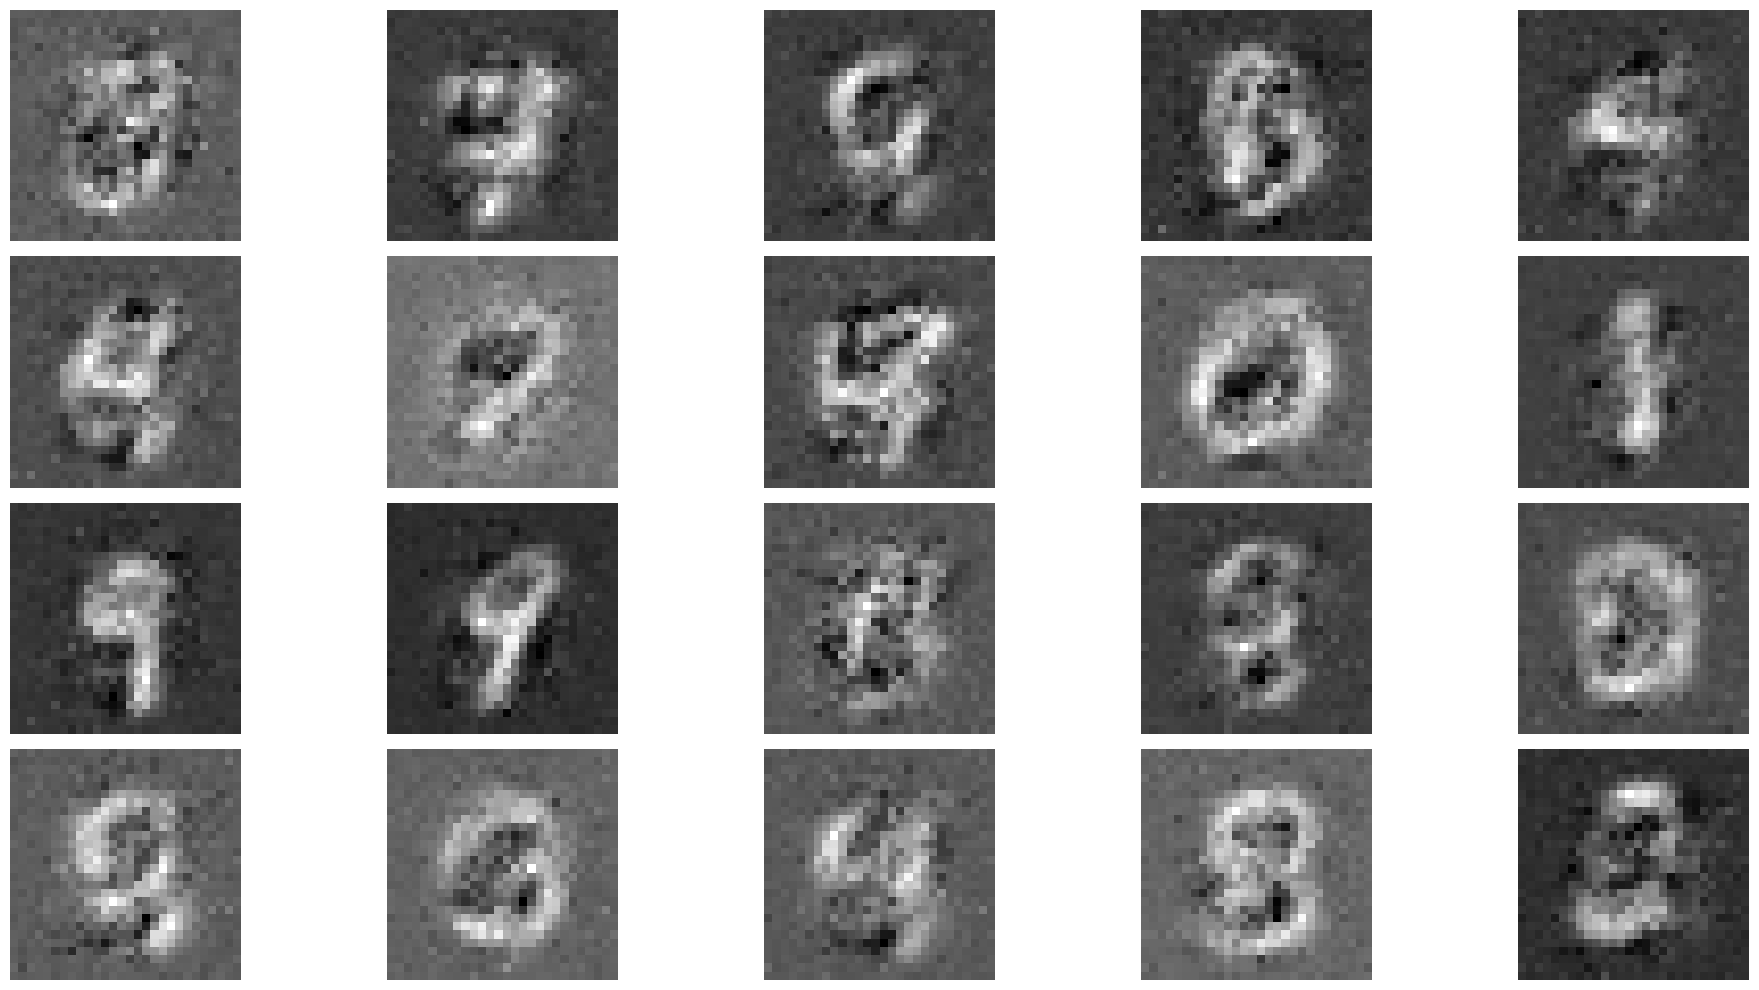

📈 Epoch 15 Summary:
   Train D Loss: 0.2923, Val D Loss: 0.2676
   Train G Loss: 5.0336, Val G Loss: 3.1349

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.165461	G_loss: 3.694999
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.777579	G_loss: 5.038922
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.359001	G_loss: 5.460387
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.281372	G_loss: 5.098794
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.357920	G_loss: 4.448078
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.137499	G_loss: 6.045219
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.296930	G_loss: 5.460624
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.112402	G_loss: 5.377931
Epoch: 16 [51200/60000 (85%)]	D_loss: 1.216448	G_loss: 3.881356
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.412409	G_loss: 4.072062
====> Epoch: 16 Train D_loss: 0.2848, Train G_loss: 5.0291
====> Epoch: 16 Val D_loss: 0.1360, Val G_loss: 4.0862
📈 Epoch 16 Summary:
   Train D Loss: 0.2848, Val D Loss: 0.1360
   Train G Loss: 5.0291

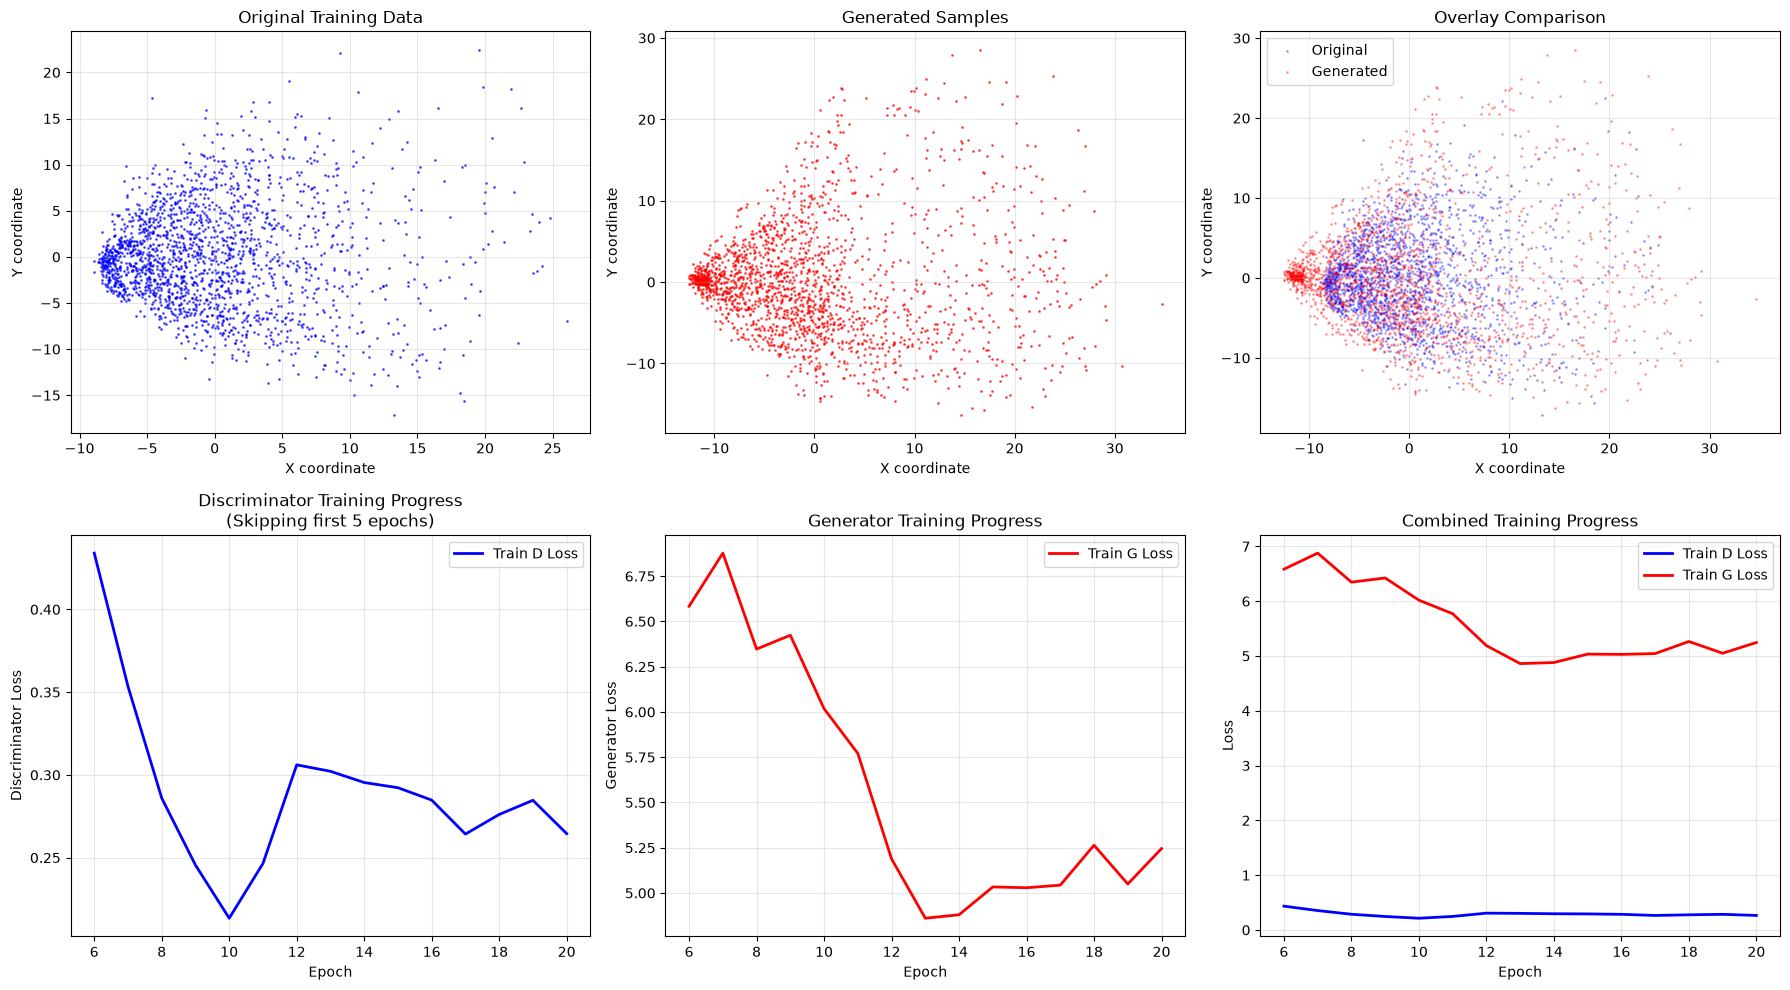

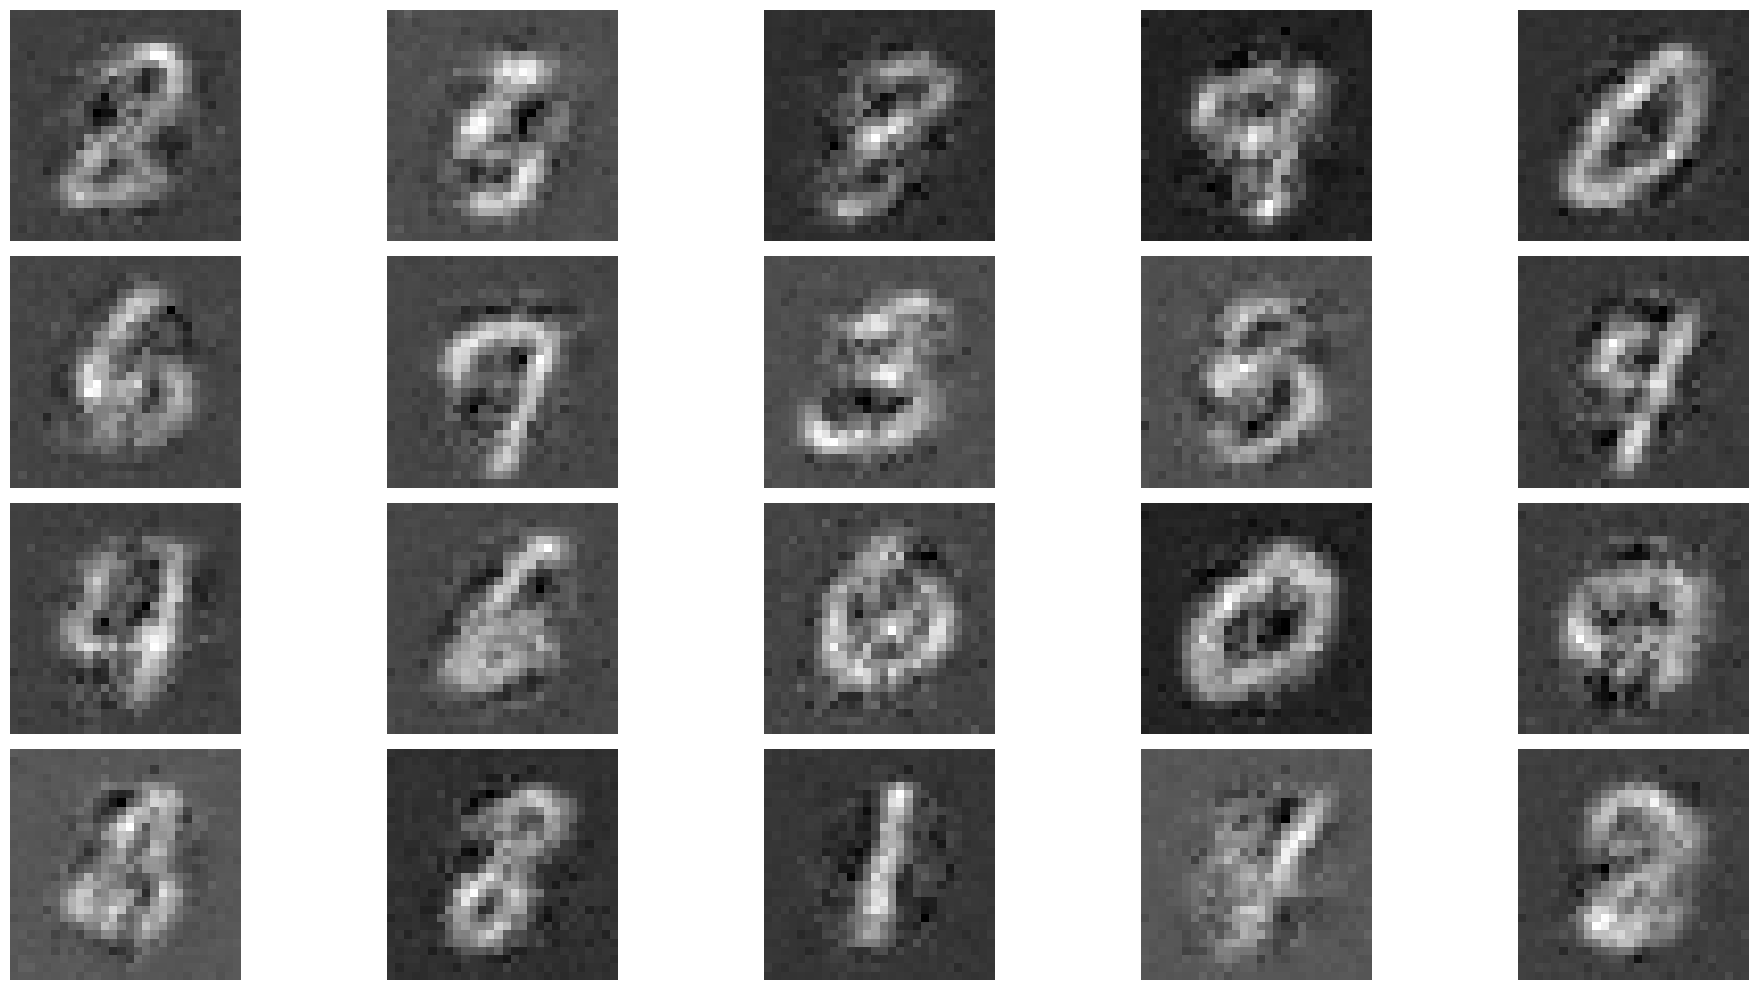

📈 Epoch 20 Summary:
   Train D Loss: 0.2645, Val D Loss: 0.1857
   Train G Loss: 5.2453, Val G Loss: 3.6720

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.126393	G_loss: 5.386282
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.356625	G_loss: 5.256677
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.237937	G_loss: 4.650182
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.459878	G_loss: 5.342917
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.206908	G_loss: 6.478525
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.148161	G_loss: 4.519258
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.167282	G_loss: 4.857098
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.222671	G_loss: 5.806697
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.514355	G_loss: 8.280533
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.399439	G_loss: 4.745434
====> Epoch: 21 Train D_loss: 0.2567, Train G_loss: 5.3633
====> Epoch: 21 Val D_loss: 0.3884, Val G_loss: 3.4153
📈 Epoch 21 Summary:
   Train D Loss: 0.2567, Val D Loss: 0.3884
   Train G Loss: 5.3633

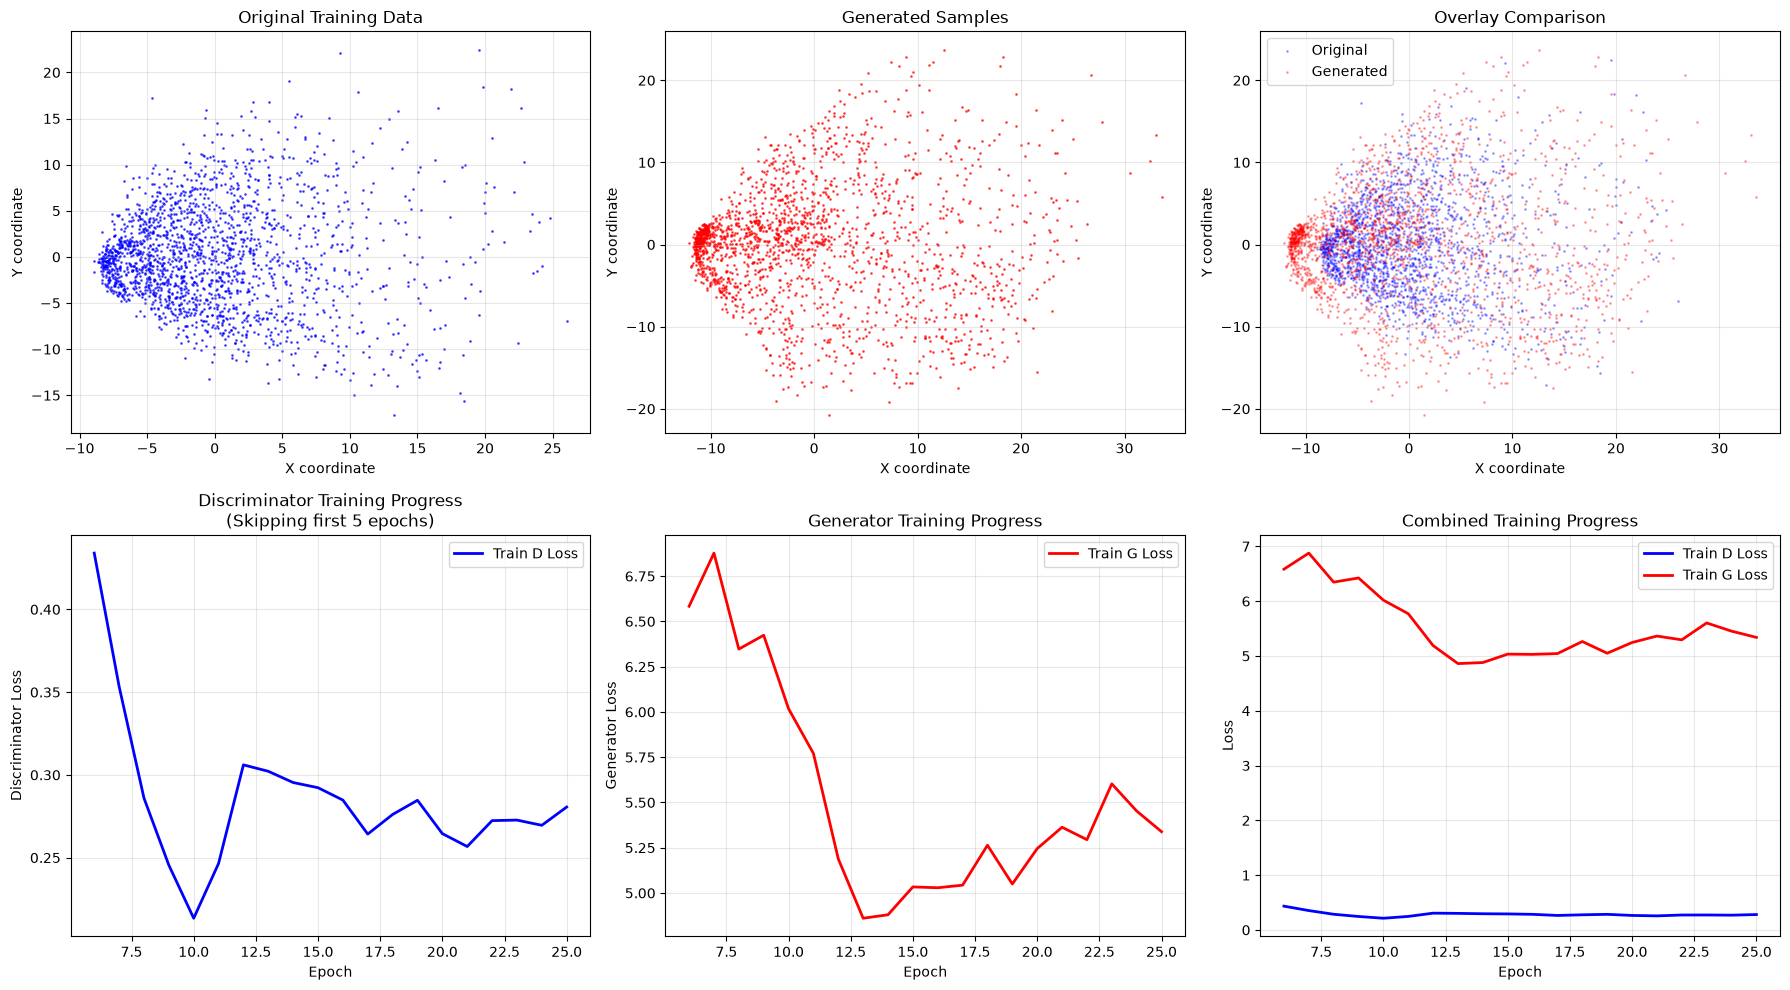

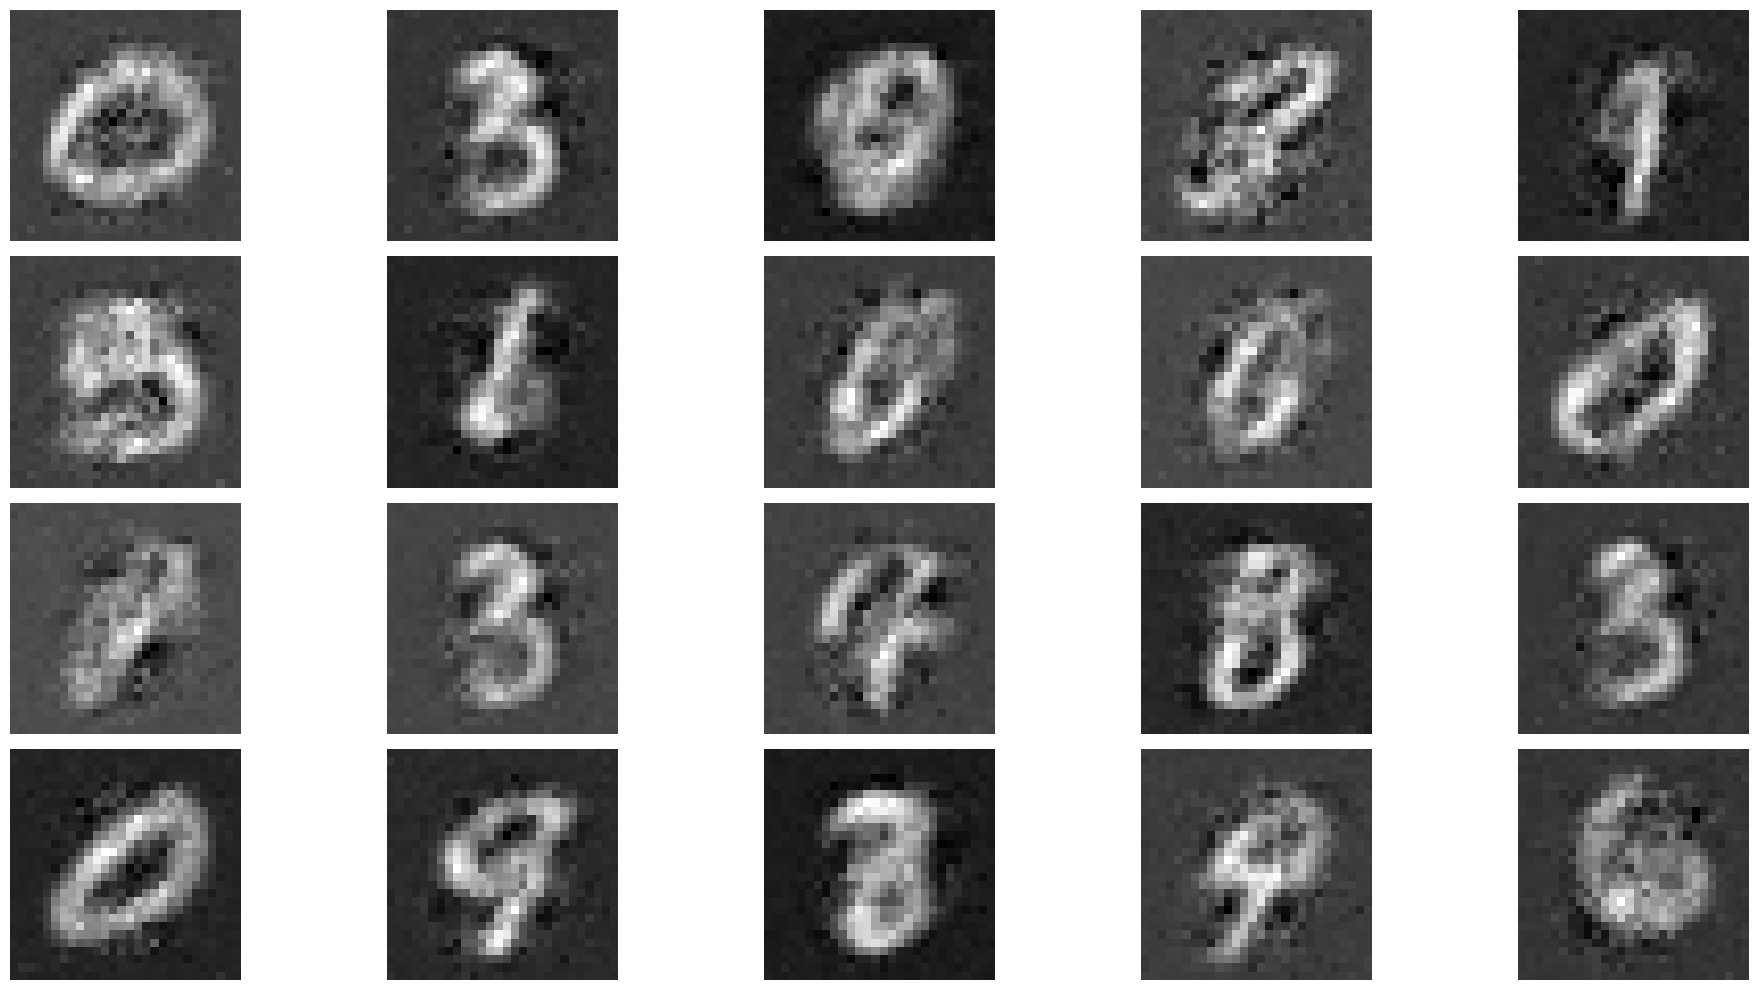

📈 Epoch 25 Summary:
   Train D Loss: 0.2806, Val D Loss: 0.1340
   Train G Loss: 5.3387, Val G Loss: 4.6194

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.141853	G_loss: 4.349240
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.202310	G_loss: 3.845225
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.324557	G_loss: 4.085669
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.229218	G_loss: 5.118911
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.372156	G_loss: 8.662403
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.224208	G_loss: 4.642900
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.715287	G_loss: 7.334491
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.098789	G_loss: 4.071348
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.308295	G_loss: 4.648727
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.145156	G_loss: 5.603654
====> Epoch: 26 Train D_loss: 0.2559, Train G_loss: 5.5518
====> Epoch: 26 Val D_loss: 0.2254, Val G_loss: 3.7252
📈 Epoch 26 Summary:
   Train D Loss: 0.2559, Val D Loss: 0.2254
   Train G Loss: 5.5518

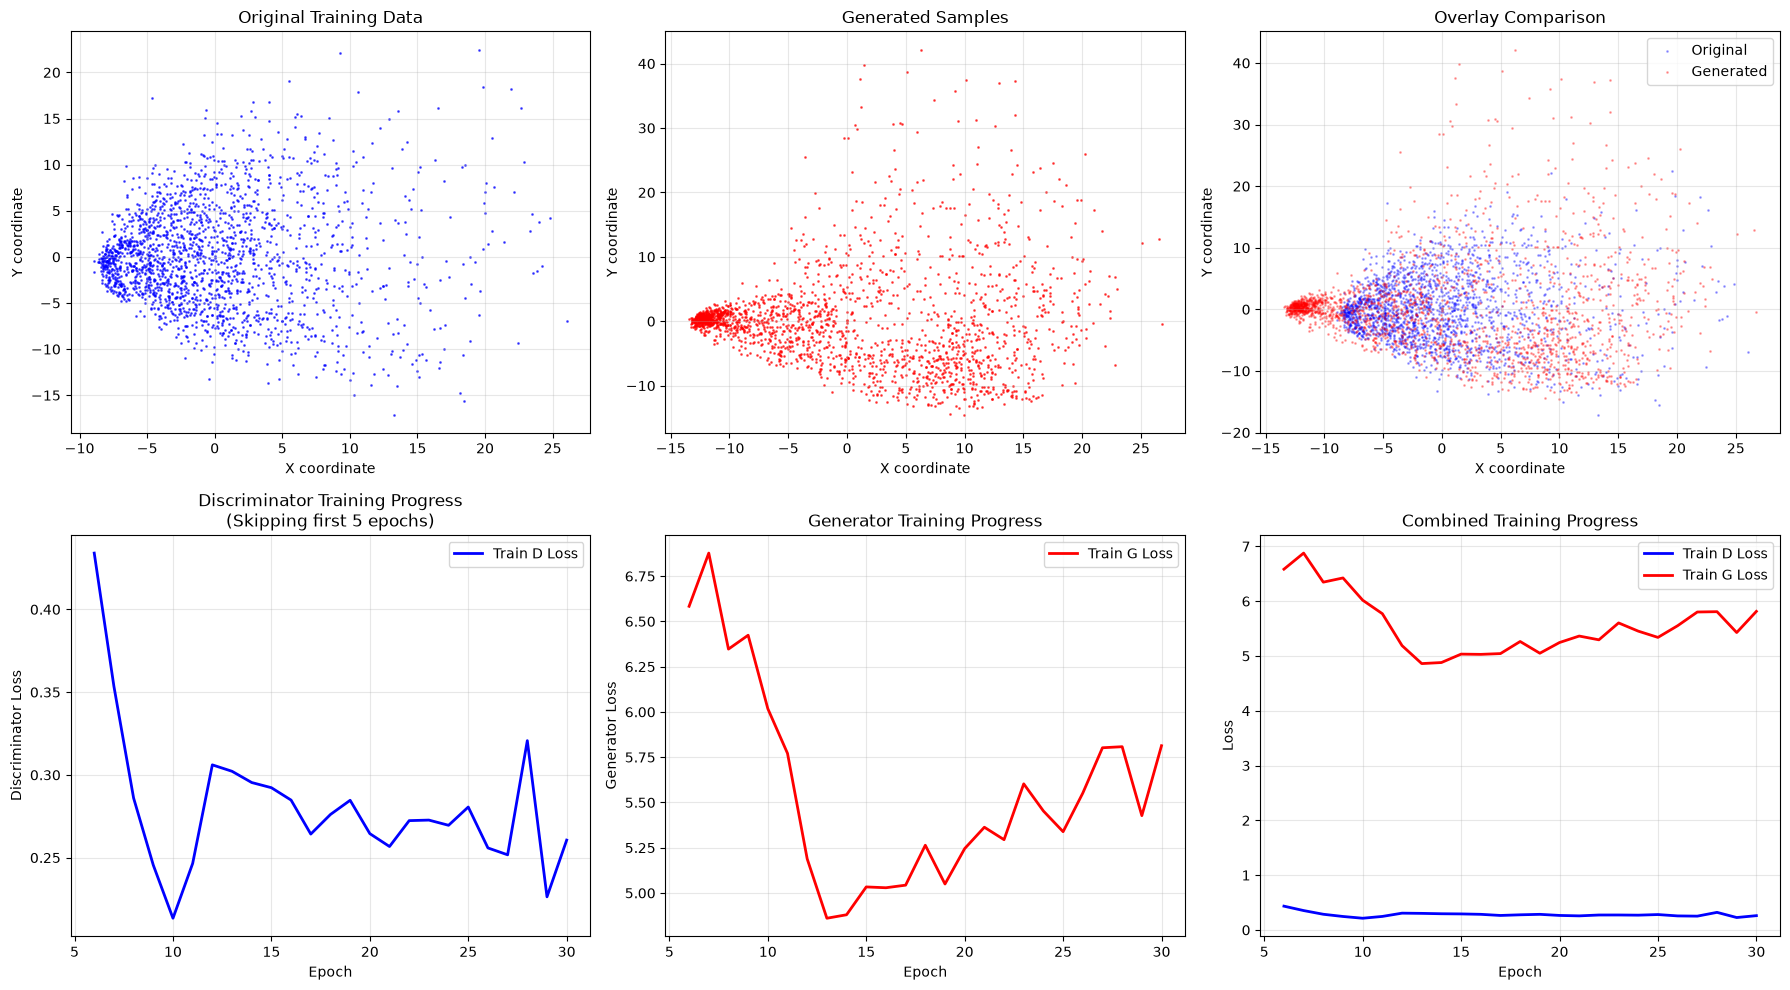

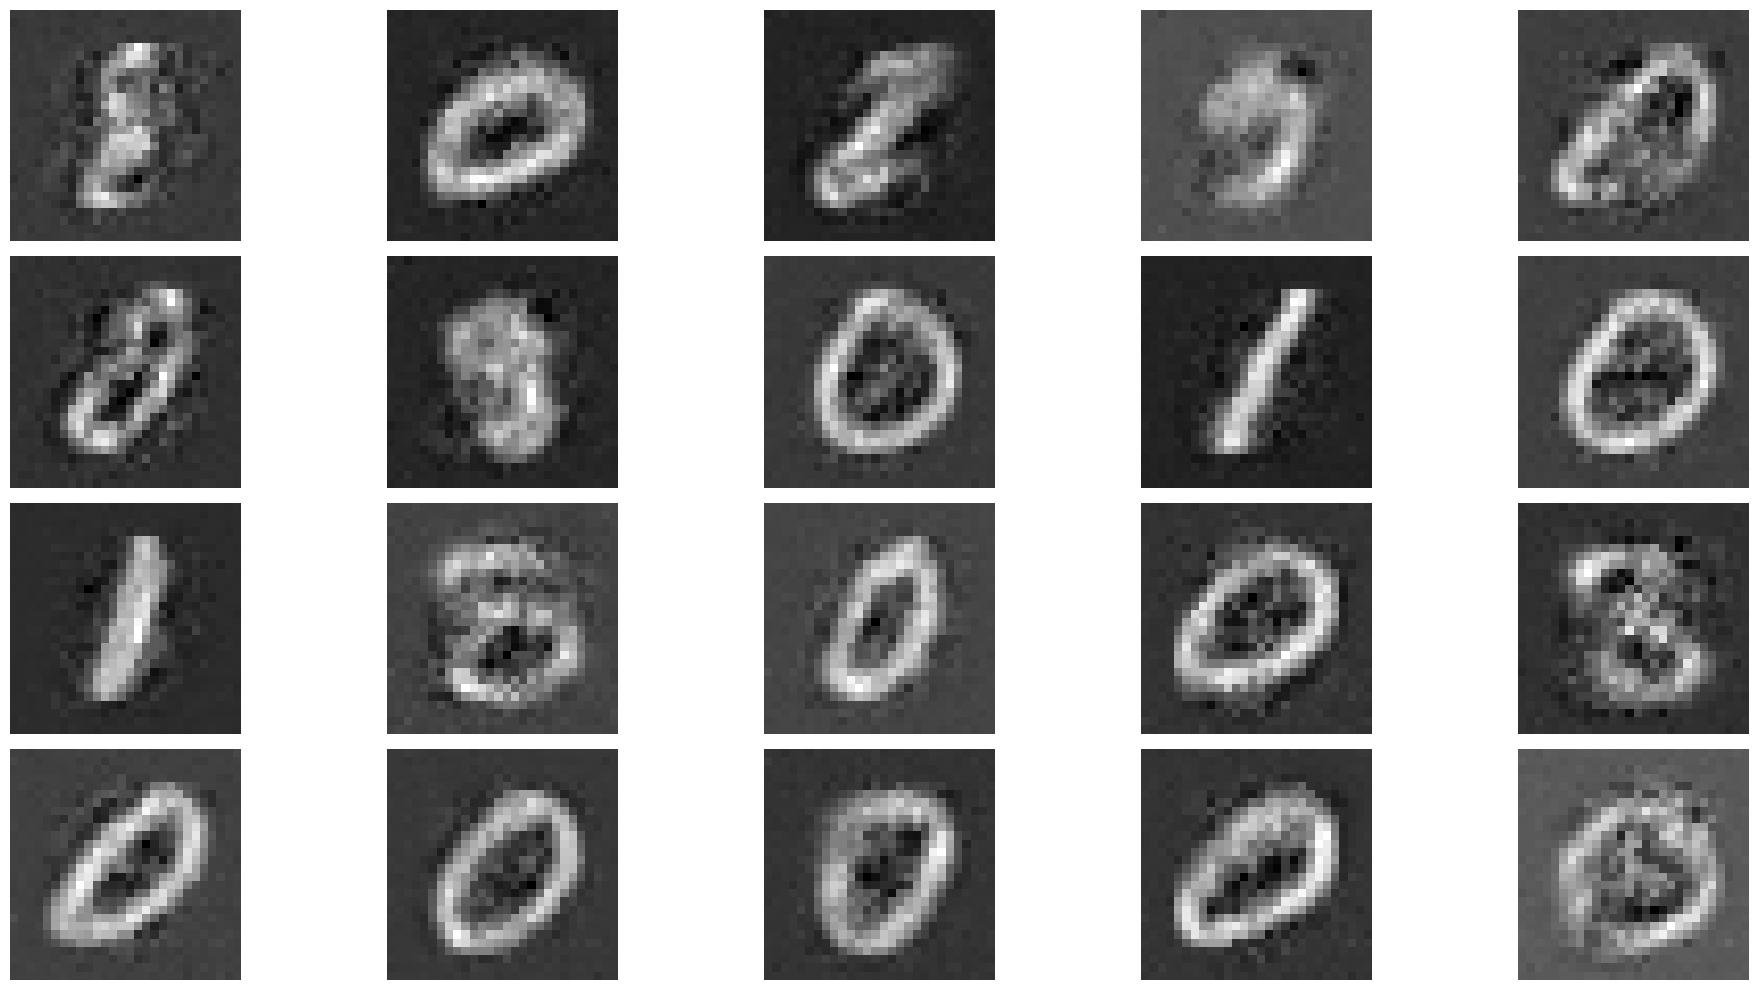

📈 Epoch 30 Summary:
   Train D Loss: 0.2606, Val D Loss: 0.2215
   Train G Loss: 5.8135, Val G Loss: 6.5029

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.179633	G_loss: 6.596613
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.290489	G_loss: 3.800930
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.170874	G_loss: 5.518963
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.049849	G_loss: 7.051086
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.226886	G_loss: 5.138663
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.310245	G_loss: 5.034548
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.212761	G_loss: 4.482097
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.086079	G_loss: 5.763553
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.227979	G_loss: 8.984819
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.200715	G_loss: 5.762402
====> Epoch: 31 Train D_loss: 0.2192, Train G_loss: 5.9196
====> Epoch: 31 Val D_loss: 0.2297, Val G_loss: 4.4578
📈 Epoch 31 Summary:
   Train D Loss: 0.2192, Val D Loss: 0.2297
   Train G Loss: 5.9196

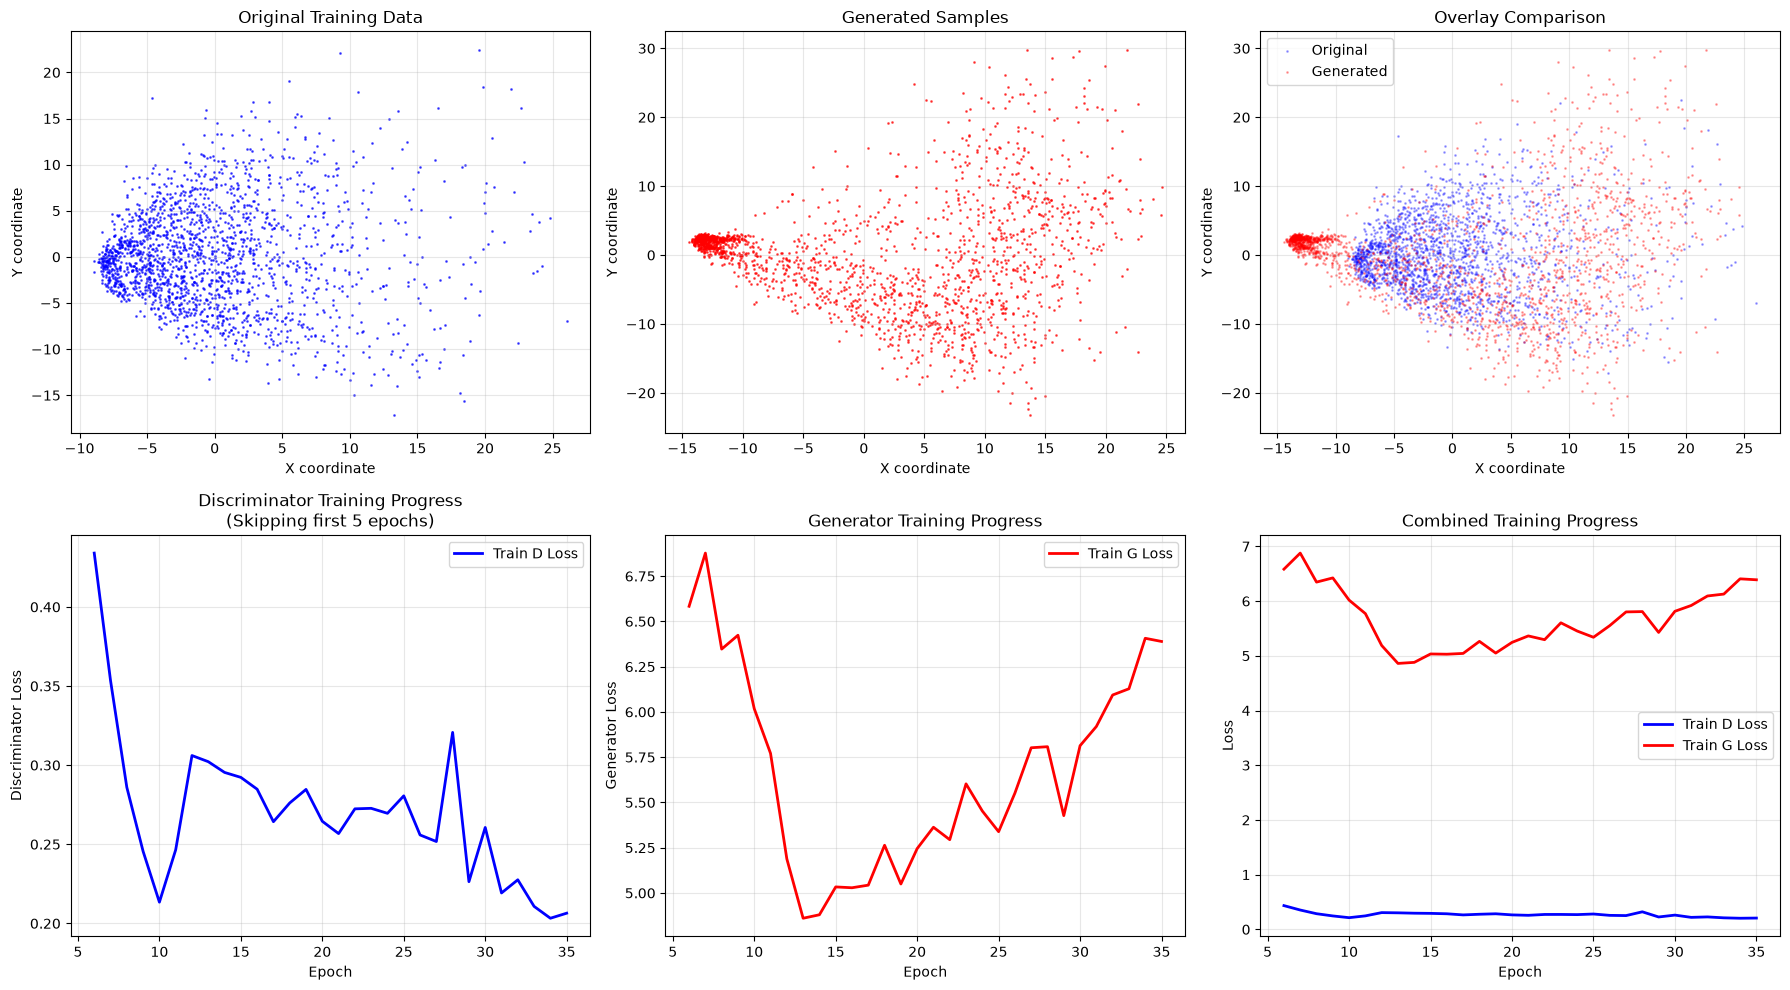

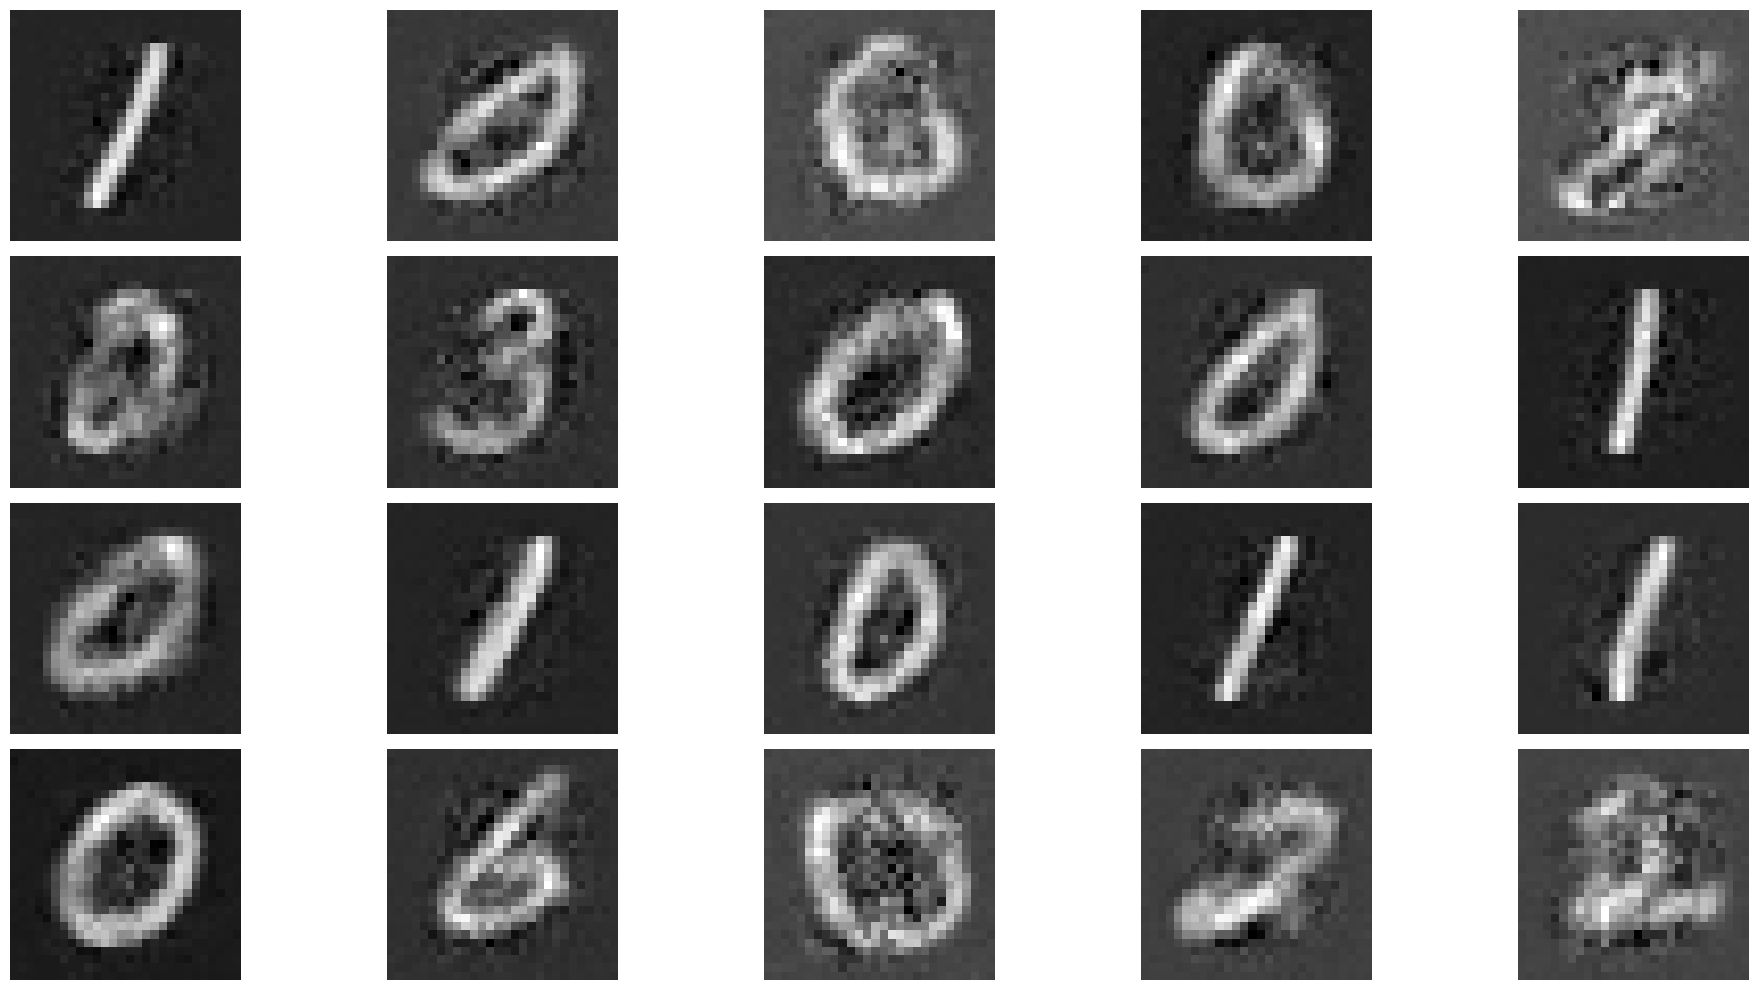

📈 Epoch 35 Summary:
   Train D Loss: 0.2064, Val D Loss: 0.1894
   Train G Loss: 6.3893, Val G Loss: 5.5822

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.119276	G_loss: 5.421822
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.255509	G_loss: 4.675045
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.060455	G_loss: 8.842430
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.166300	G_loss: 5.403135
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.209452	G_loss: 4.084089
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.109891	G_loss: 6.517150
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.154693	G_loss: 5.379721
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.279127	G_loss: 5.562425
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.296870	G_loss: 4.648450
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.138163	G_loss: 6.855256
====> Epoch: 36 Train D_loss: 0.1968, Train G_loss: 6.4147
====> Epoch: 36 Val D_loss: 0.1651, Val G_loss: 7.3661
📈 Epoch 36 Summary:
   Train D Loss: 0.1968, Val D Loss: 0.1651
   Train G Loss: 6.4147

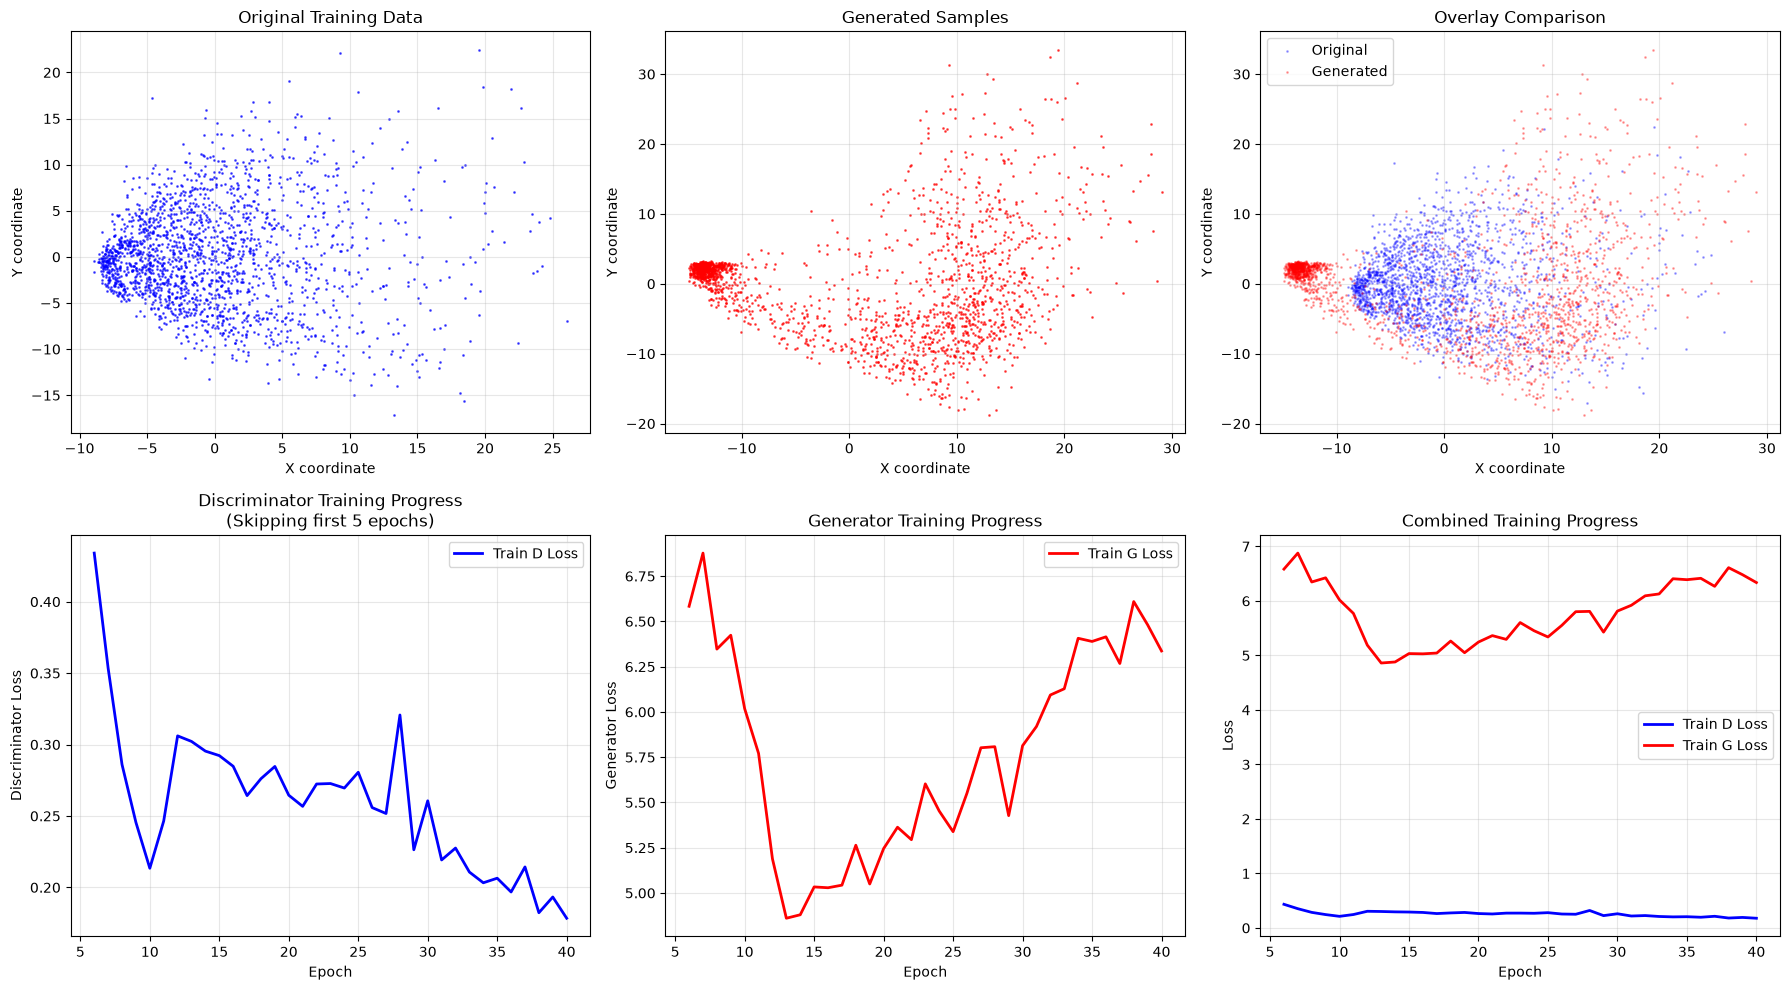

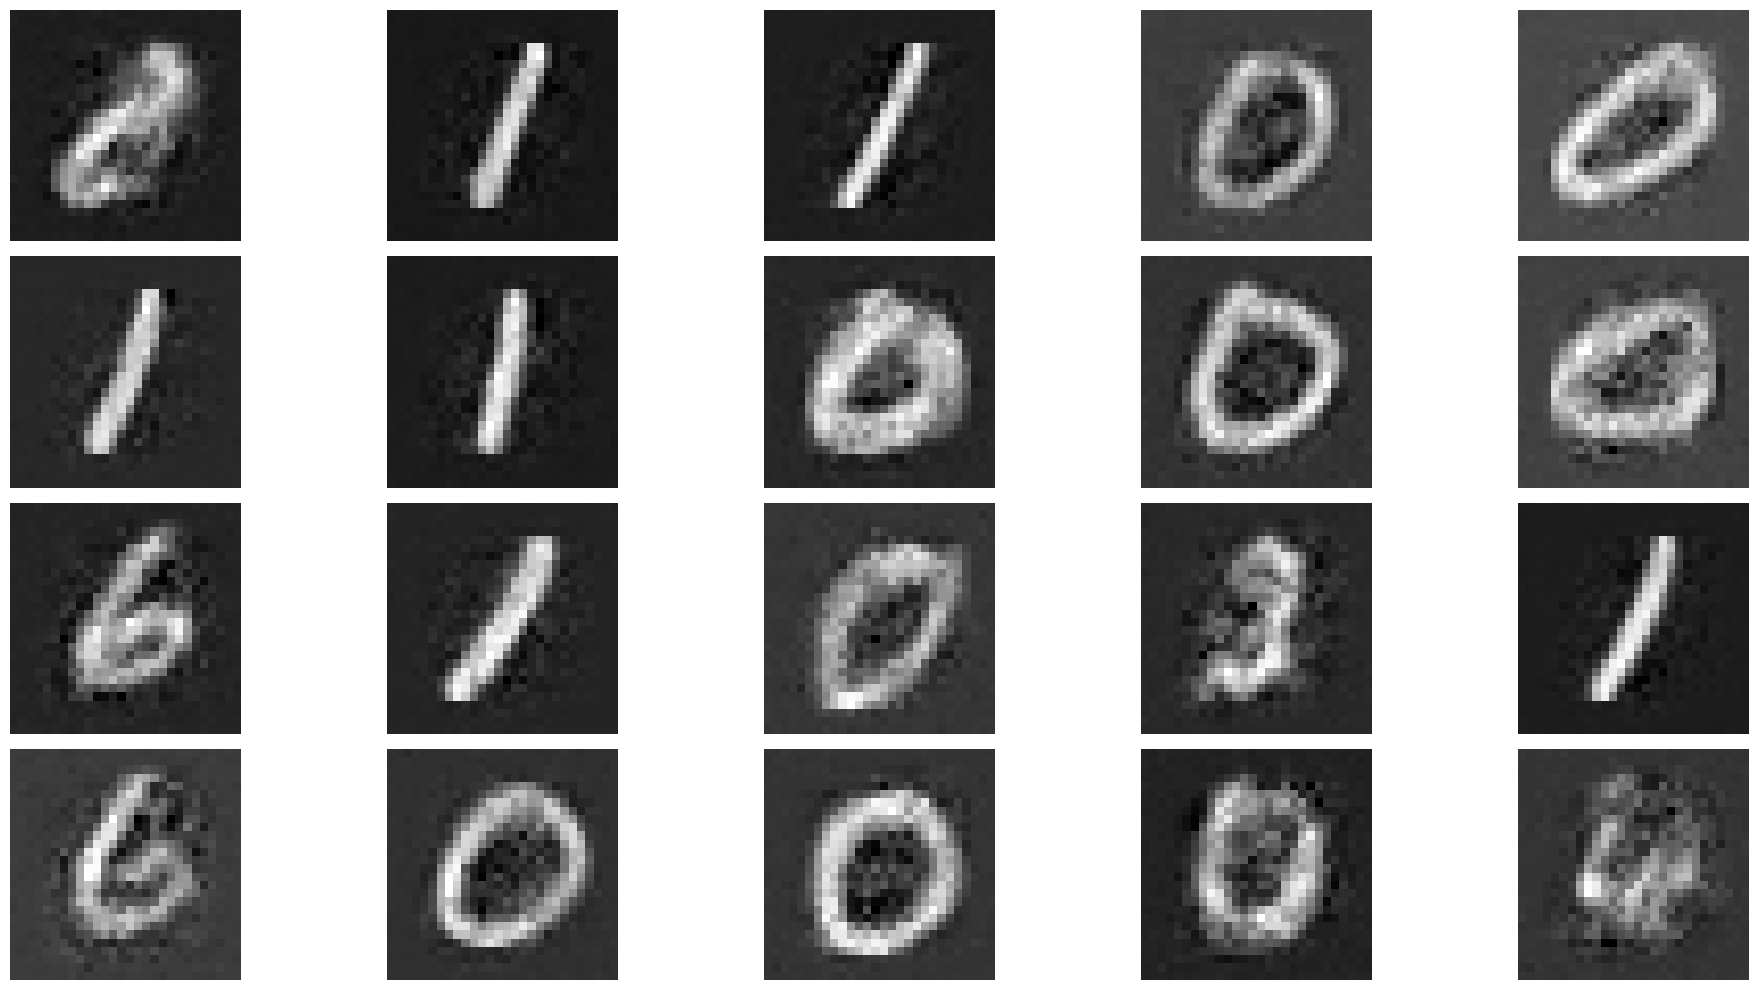

📈 Epoch 40 Summary:
   Train D Loss: 0.1784, Val D Loss: 0.2050
   Train G Loss: 6.3367, Val G Loss: 4.3114

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.228964	G_loss: 5.607450
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.234218	G_loss: 4.928281
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.145918	G_loss: 7.481514
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.144930	G_loss: 7.156291
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.142935	G_loss: 6.568974
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.194425	G_loss: 6.934921
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.093243	G_loss: 5.940205
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.106282	G_loss: 9.174818
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.124868	G_loss: 6.268292
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.137764	G_loss: 5.019791
====> Epoch: 41 Train D_loss: 0.1790, Train G_loss: 6.5733
====> Epoch: 41 Val D_loss: 0.4050, Val G_loss: 5.8045
📈 Epoch 41 Summary:
   Train D Loss: 0.1790, Val D Loss: 0.4050
   Train G Loss: 6.5733

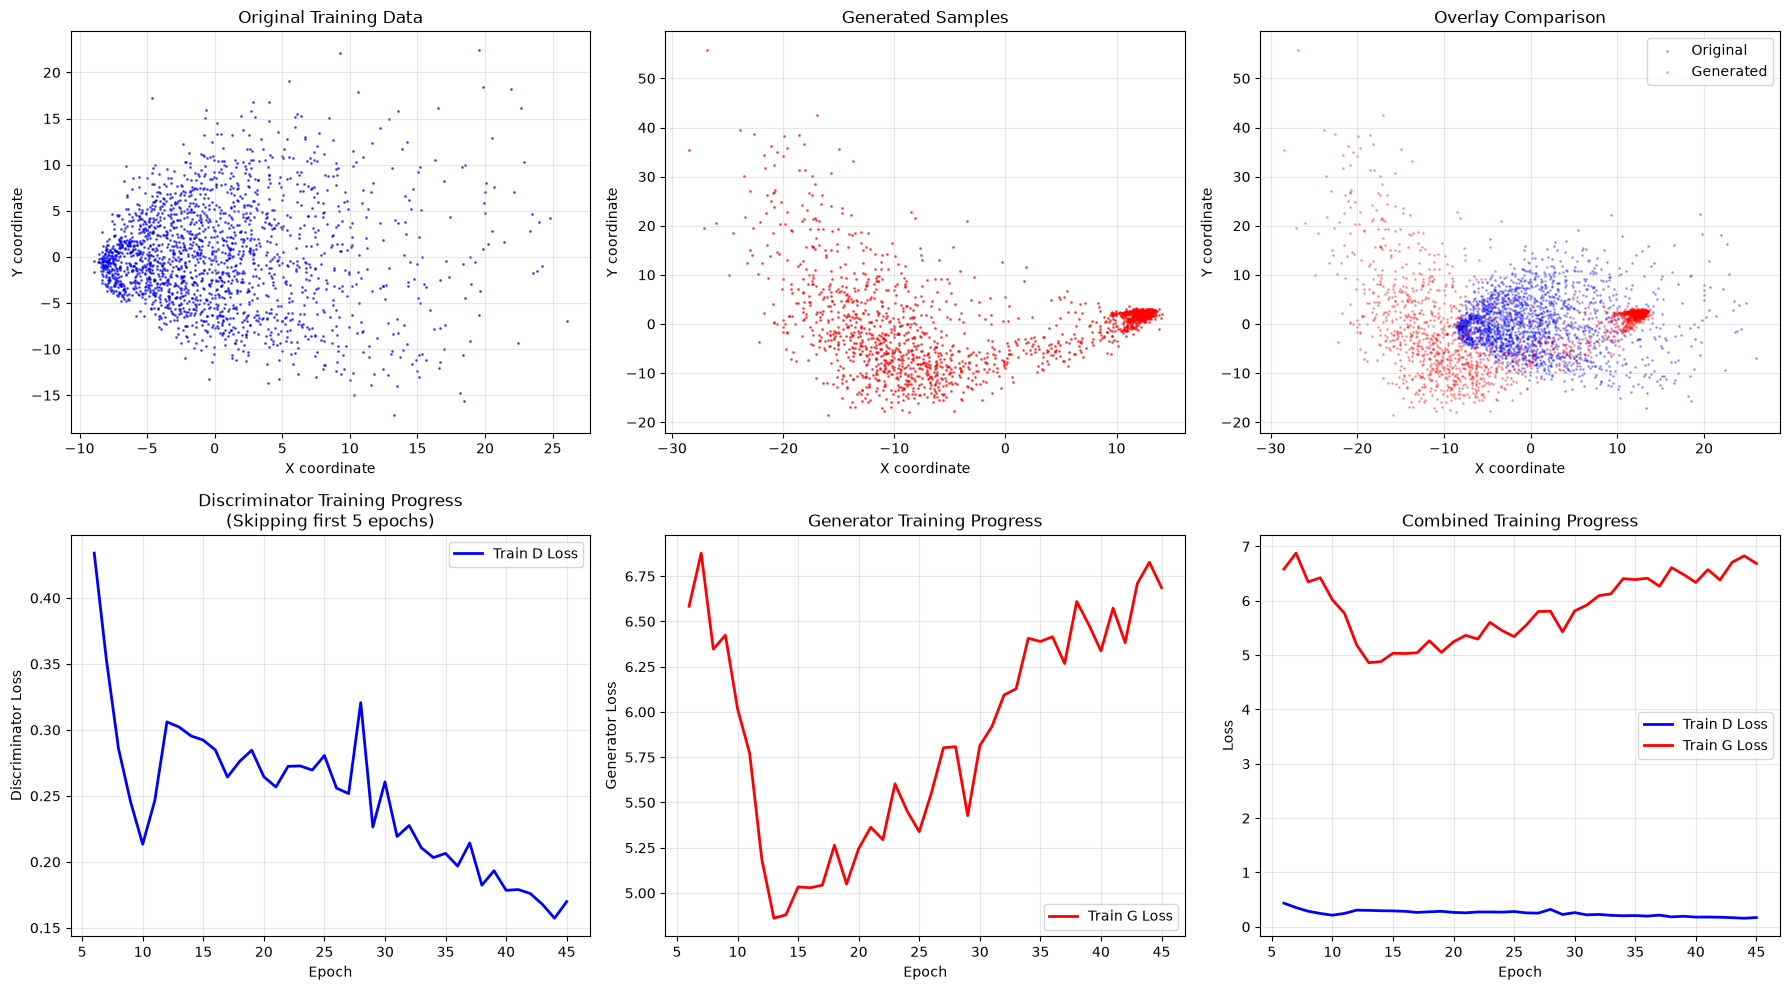

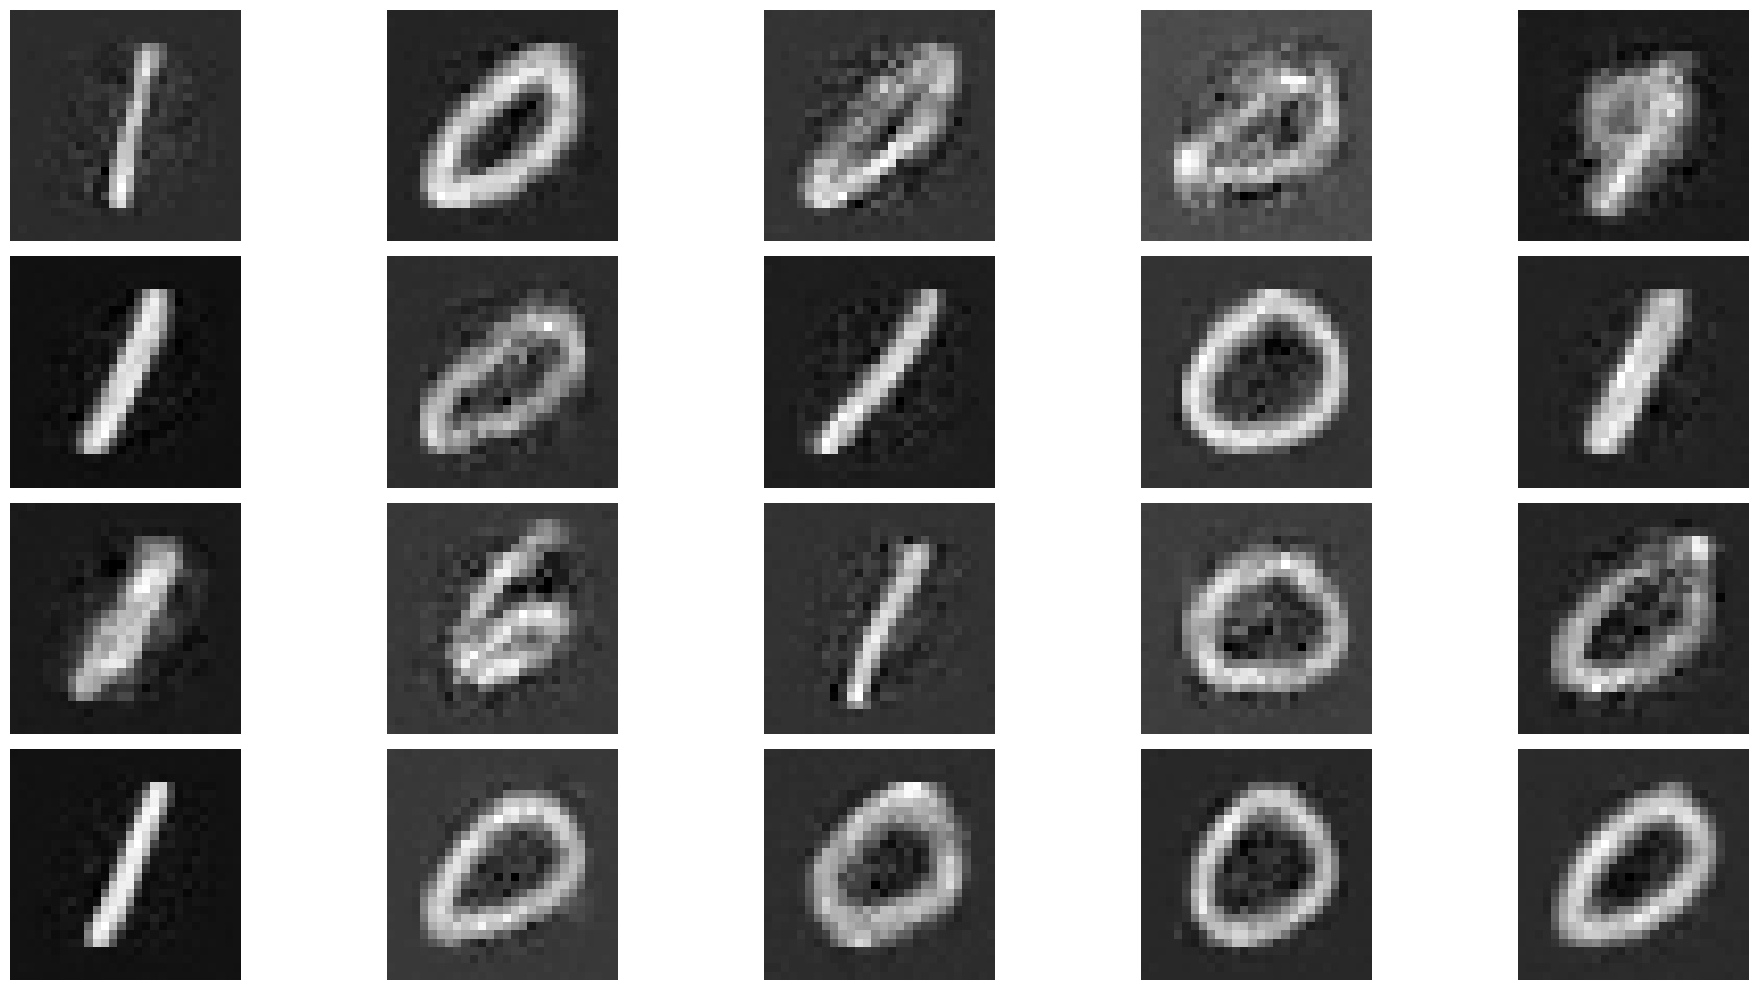

📈 Epoch 45 Summary:
   Train D Loss: 0.1699, Val D Loss: 0.2027
   Train G Loss: 6.6865, Val G Loss: 4.0038

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.141066	G_loss: 4.963212
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.100030	G_loss: 7.054014
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.291204	G_loss: 8.160233
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.151765	G_loss: 5.042485
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.106906	G_loss: 6.794350
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.108904	G_loss: 6.724783
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.124562	G_loss: 7.499859
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.176070	G_loss: 4.542192
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.101697	G_loss: 6.810088
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.089898	G_loss: 7.358953
====> Epoch: 46 Train D_loss: 0.1561, Train G_loss: 6.7875
====> Epoch: 46 Val D_loss: 0.1341, Val G_loss: 7.1986
📈 Epoch 46 Summary:
   Train D Loss: 0.1561, Val D Loss: 0.1341
   Train G Loss: 6.7875

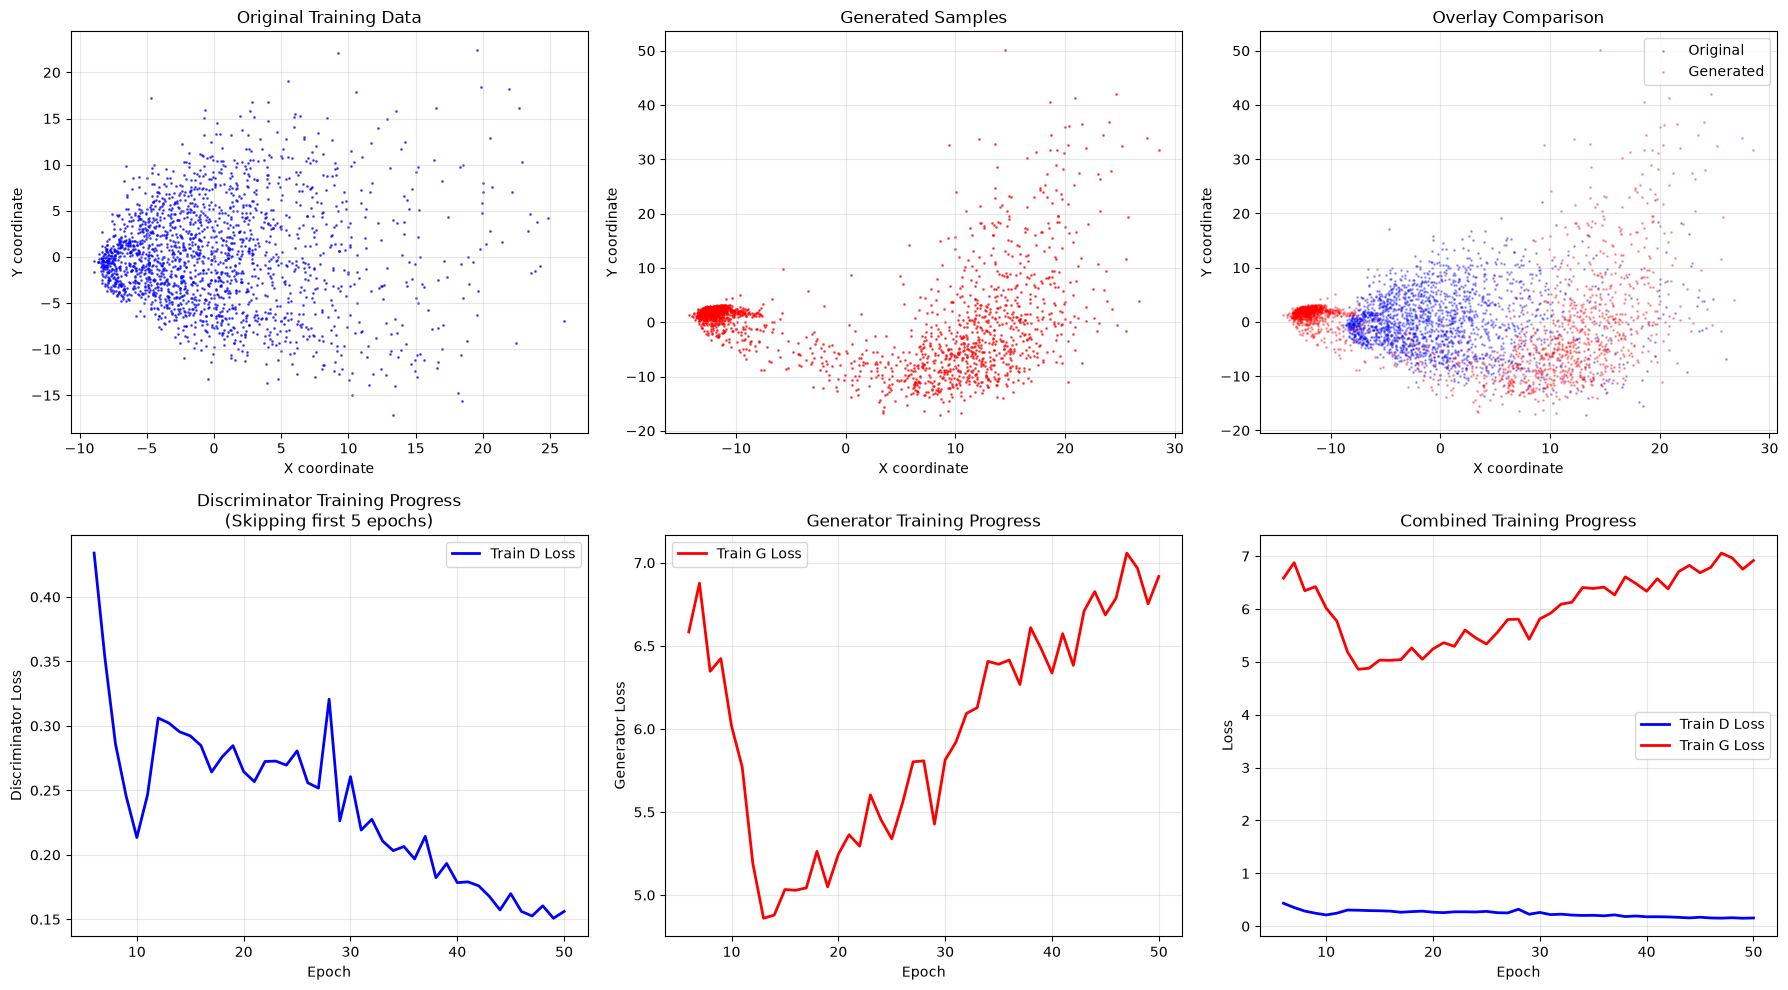

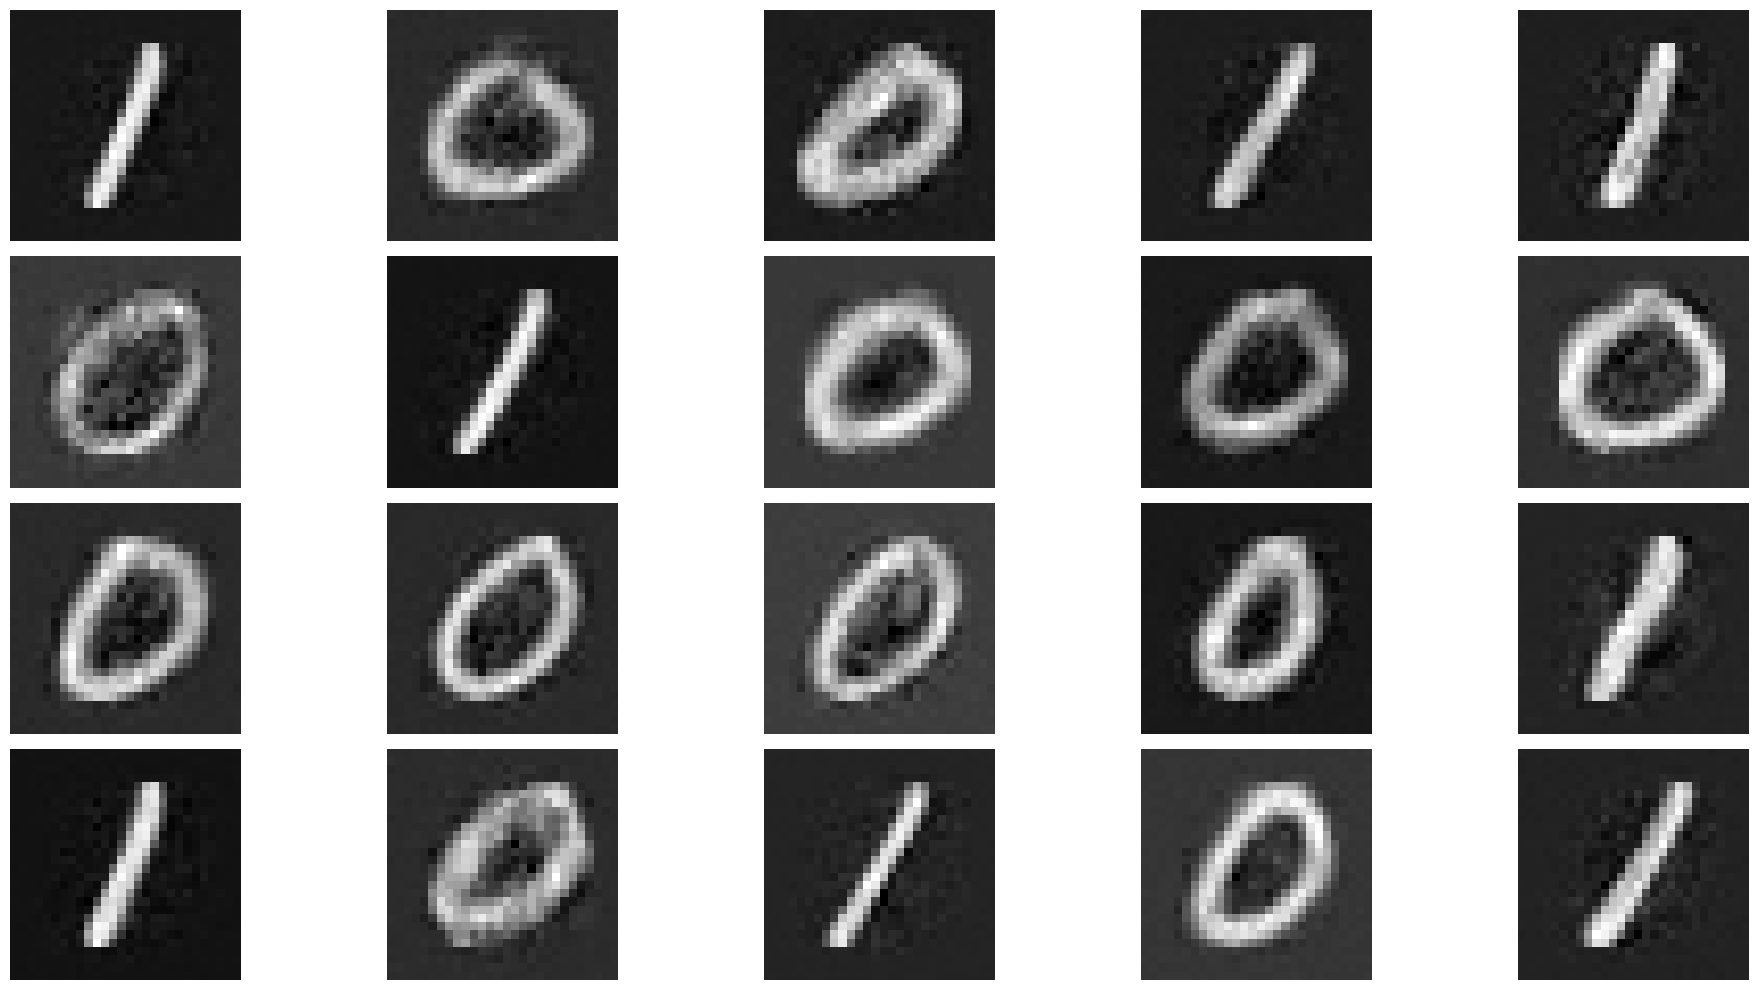

📈 Epoch 50 Summary:
   Train D Loss: 0.1561, Val D Loss: 0.0978
   Train G Loss: 6.9182, Val G Loss: 7.0143

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.058843	G_loss: 6.271837
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.061868	G_loss: 7.538674
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.122307	G_loss: 9.403898
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.151572	G_loss: 7.302835
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.151772	G_loss: 6.065491
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.091113	G_loss: 6.118444
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.105512	G_loss: 4.905844
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.061485	G_loss: 6.582369
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.161302	G_loss: 9.403590
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.250990	G_loss: 6.932655
====> Epoch: 51 Train D_loss: 0.1448, Train G_loss: 7.1455
====> Epoch: 51 Val D_loss: 0.2659, Val G_loss: 4.8377
📈 Epoch 51 Summary:
   Train D Loss: 0.1448, Val D Loss: 0.2659
   Train G Loss: 7.1455

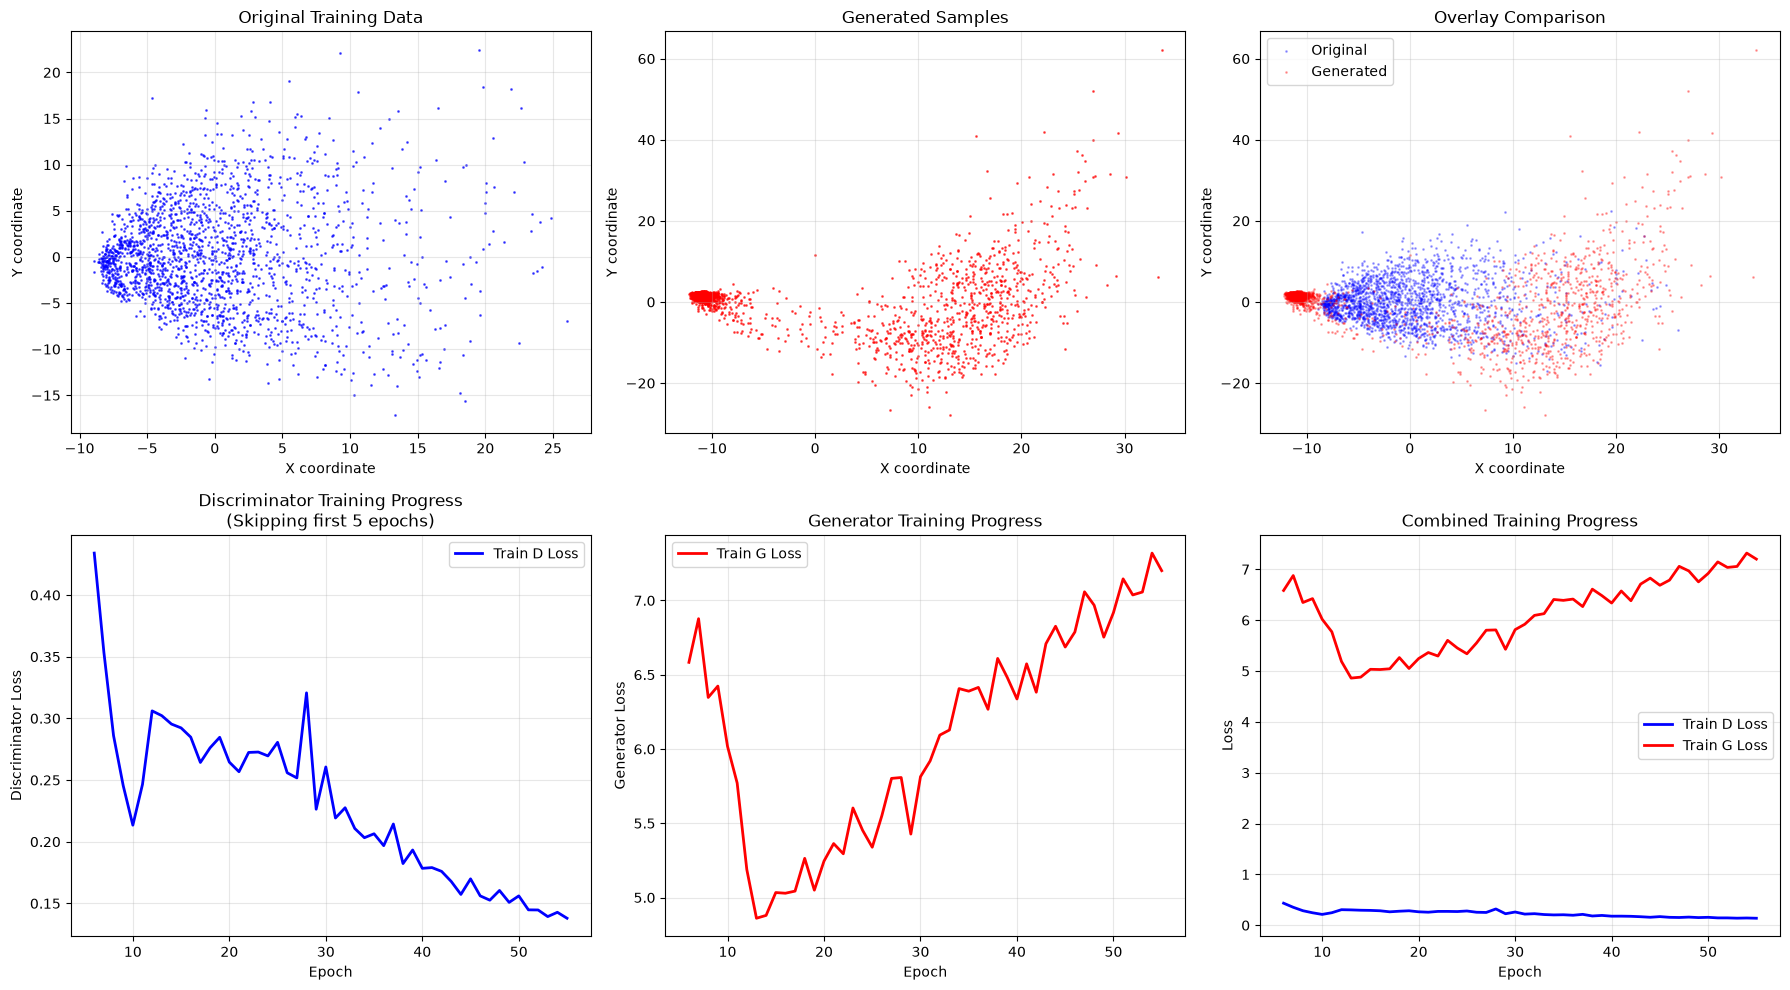

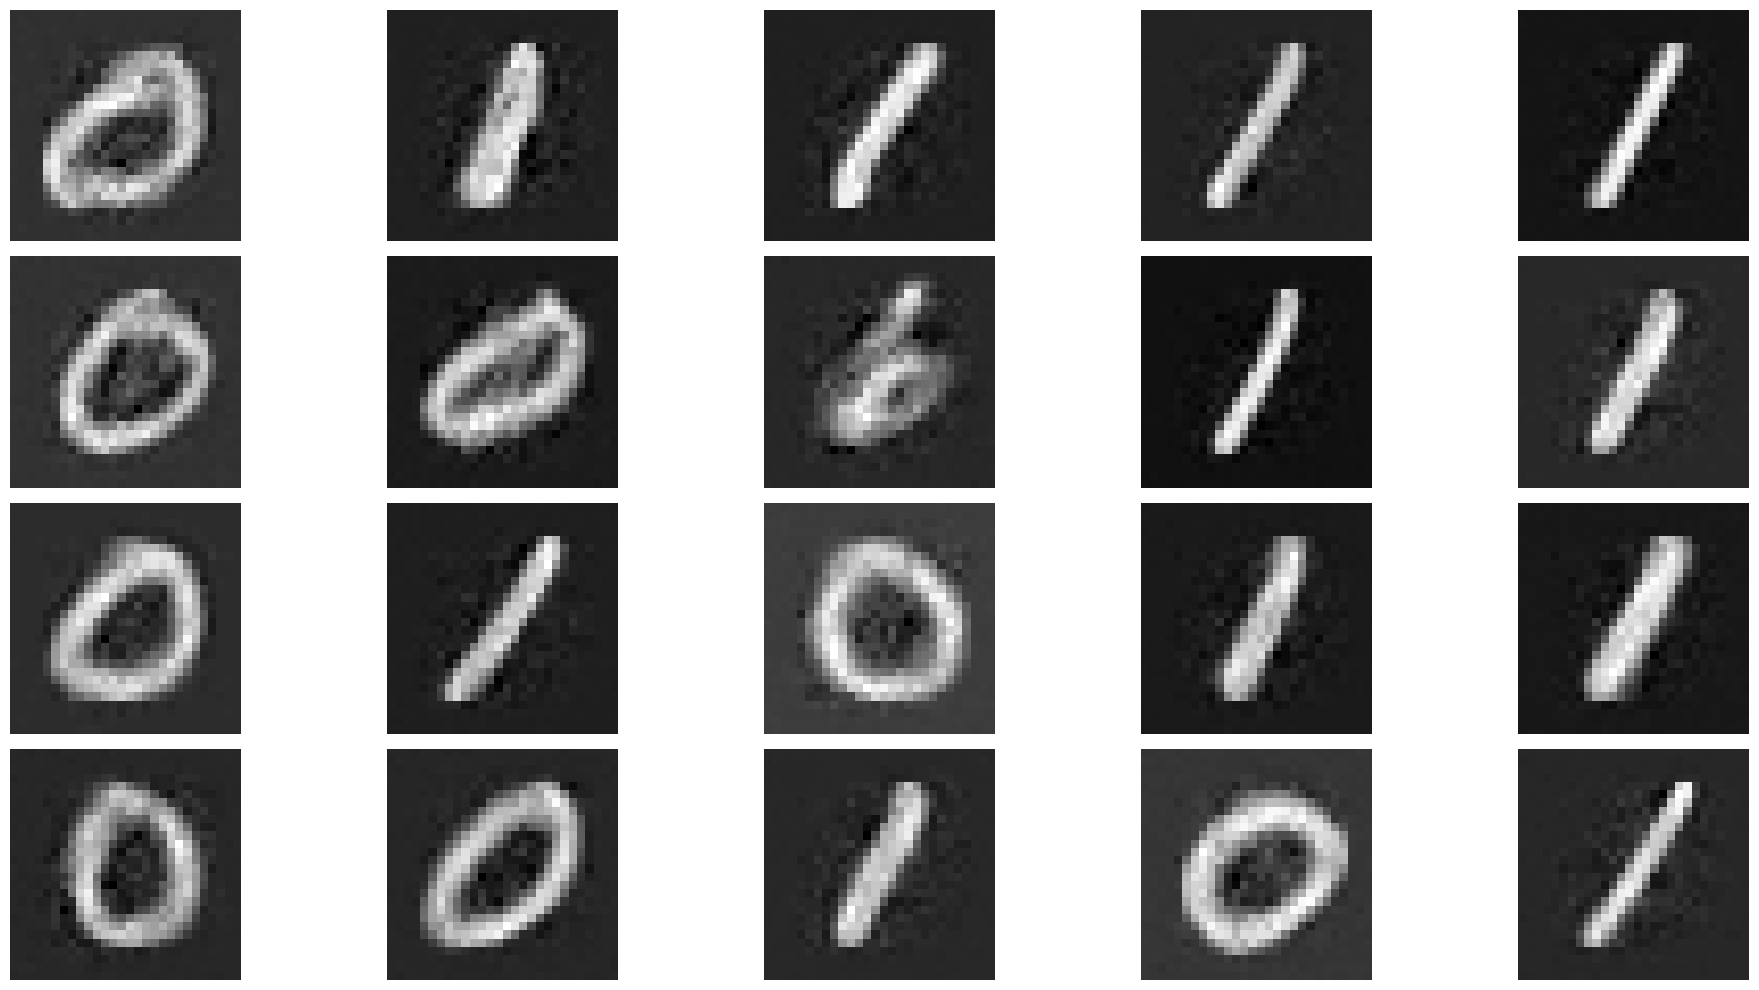

📈 Epoch 55 Summary:
   Train D Loss: 0.1380, Val D Loss: 0.5377
   Train G Loss: 7.2005, Val G Loss: 8.5459

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.327308	G_loss: 9.576668
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.060229	G_loss: 8.189659
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.110460	G_loss: 6.184039
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.100637	G_loss: 10.449819
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.217930	G_loss: 5.448400
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.119318	G_loss: 6.108384
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.102102	G_loss: 6.391210
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.099351	G_loss: 8.969215
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.435972	G_loss: 7.778680
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.199660	G_loss: 5.301526
====> Epoch: 56 Train D_loss: 0.1452, Train G_loss: 7.1978
====> Epoch: 56 Val D_loss: 0.1604, Val G_loss: 4.9687
📈 Epoch 56 Summary:
   Train D Loss: 0.1452, Val D Loss: 0.1604
   Train G Loss: 7.197

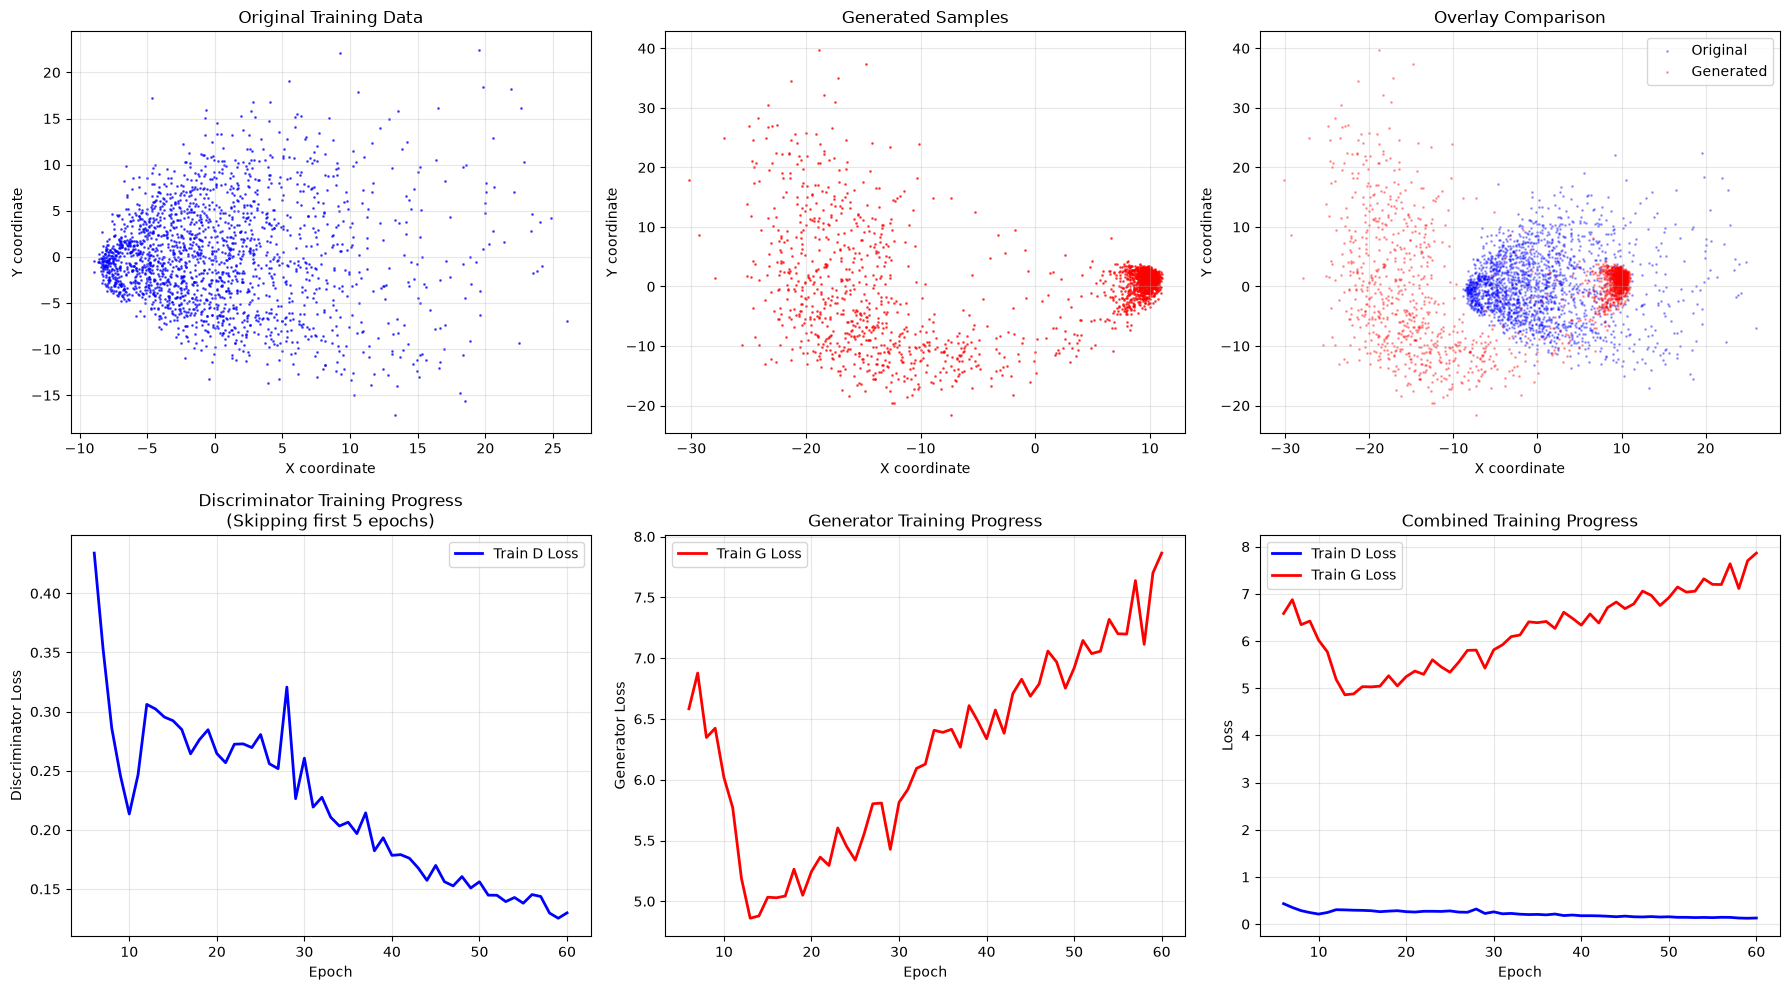

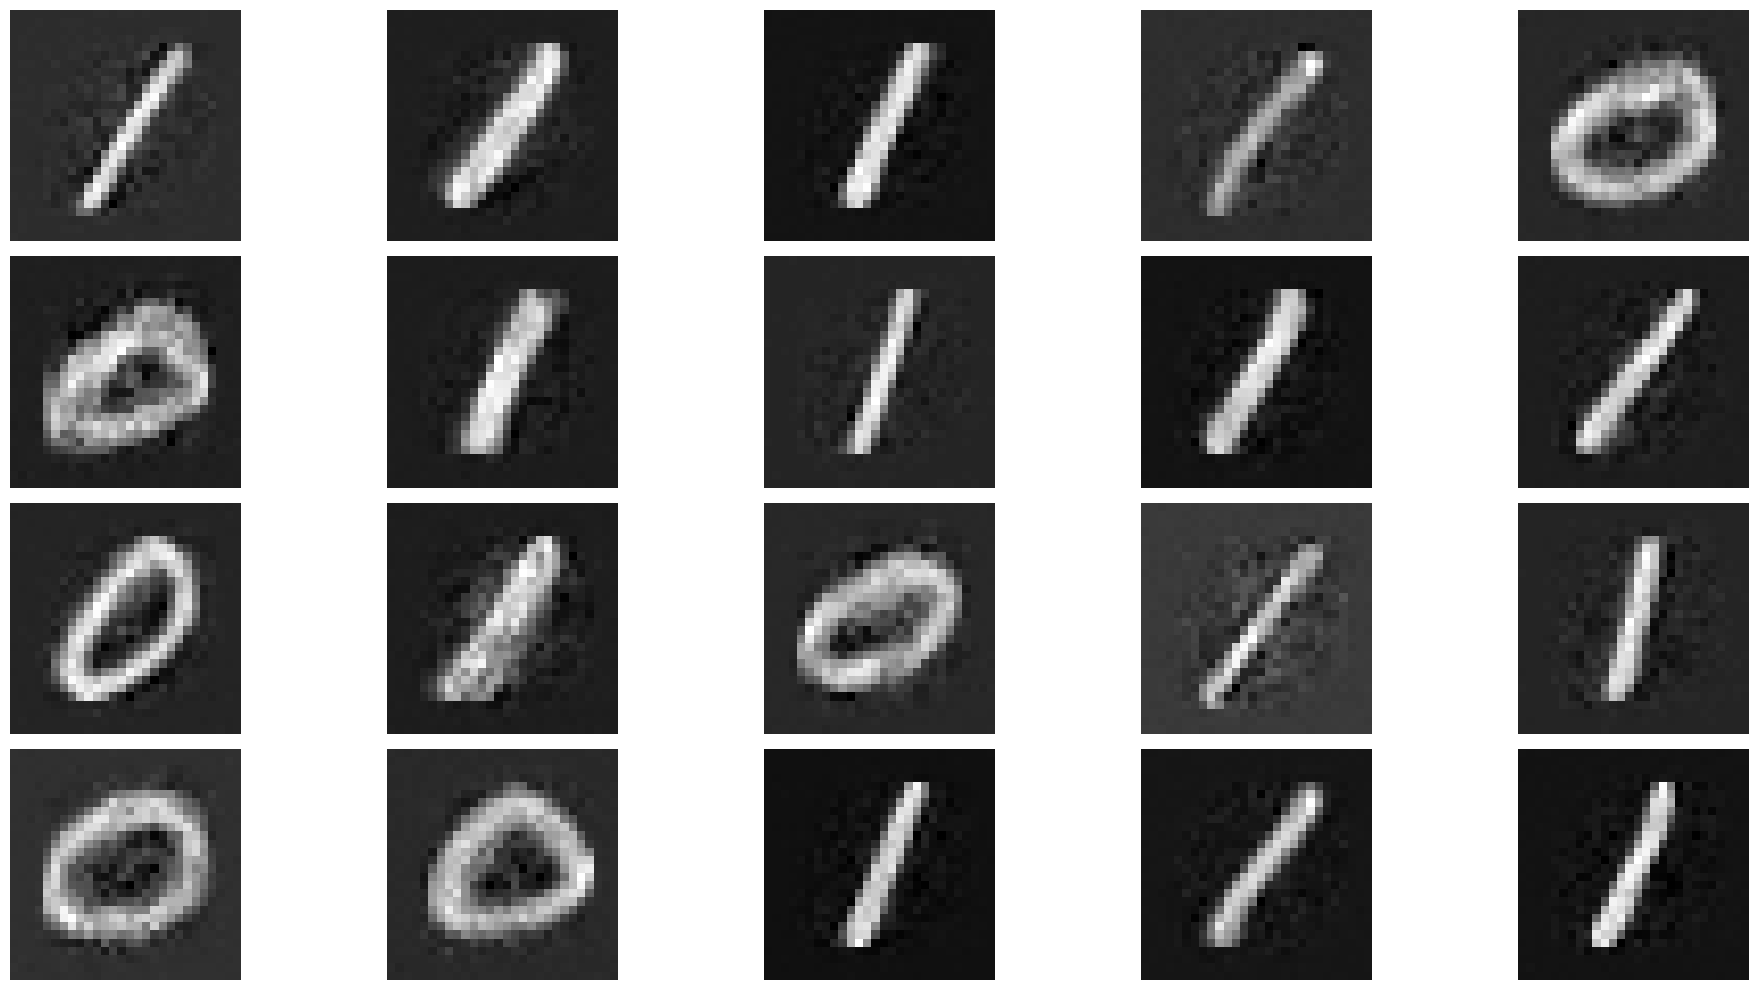

📈 Epoch 60 Summary:
   Train D Loss: 0.1298, Val D Loss: 0.1419
   Train G Loss: 7.8639, Val G Loss: 4.6974

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.105888	G_loss: 5.829174
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.074050	G_loss: 5.439147
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.166056	G_loss: 5.697227
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.071480	G_loss: 5.854336
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.101054	G_loss: 10.508512
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.101605	G_loss: 5.657927
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.062460	G_loss: 10.528700
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.166534	G_loss: 8.985668
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.081112	G_loss: 4.977536
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.069485	G_loss: 9.321649
====> Epoch: 61 Train D_loss: 0.1153, Train G_loss: 7.7851
====> Epoch: 61 Val D_loss: 0.1204, Val G_loss: 7.3561
📈 Epoch 61 Summary:
   Train D Loss: 0.1153, Val D Loss: 0.1204
   Train G Loss: 7.78

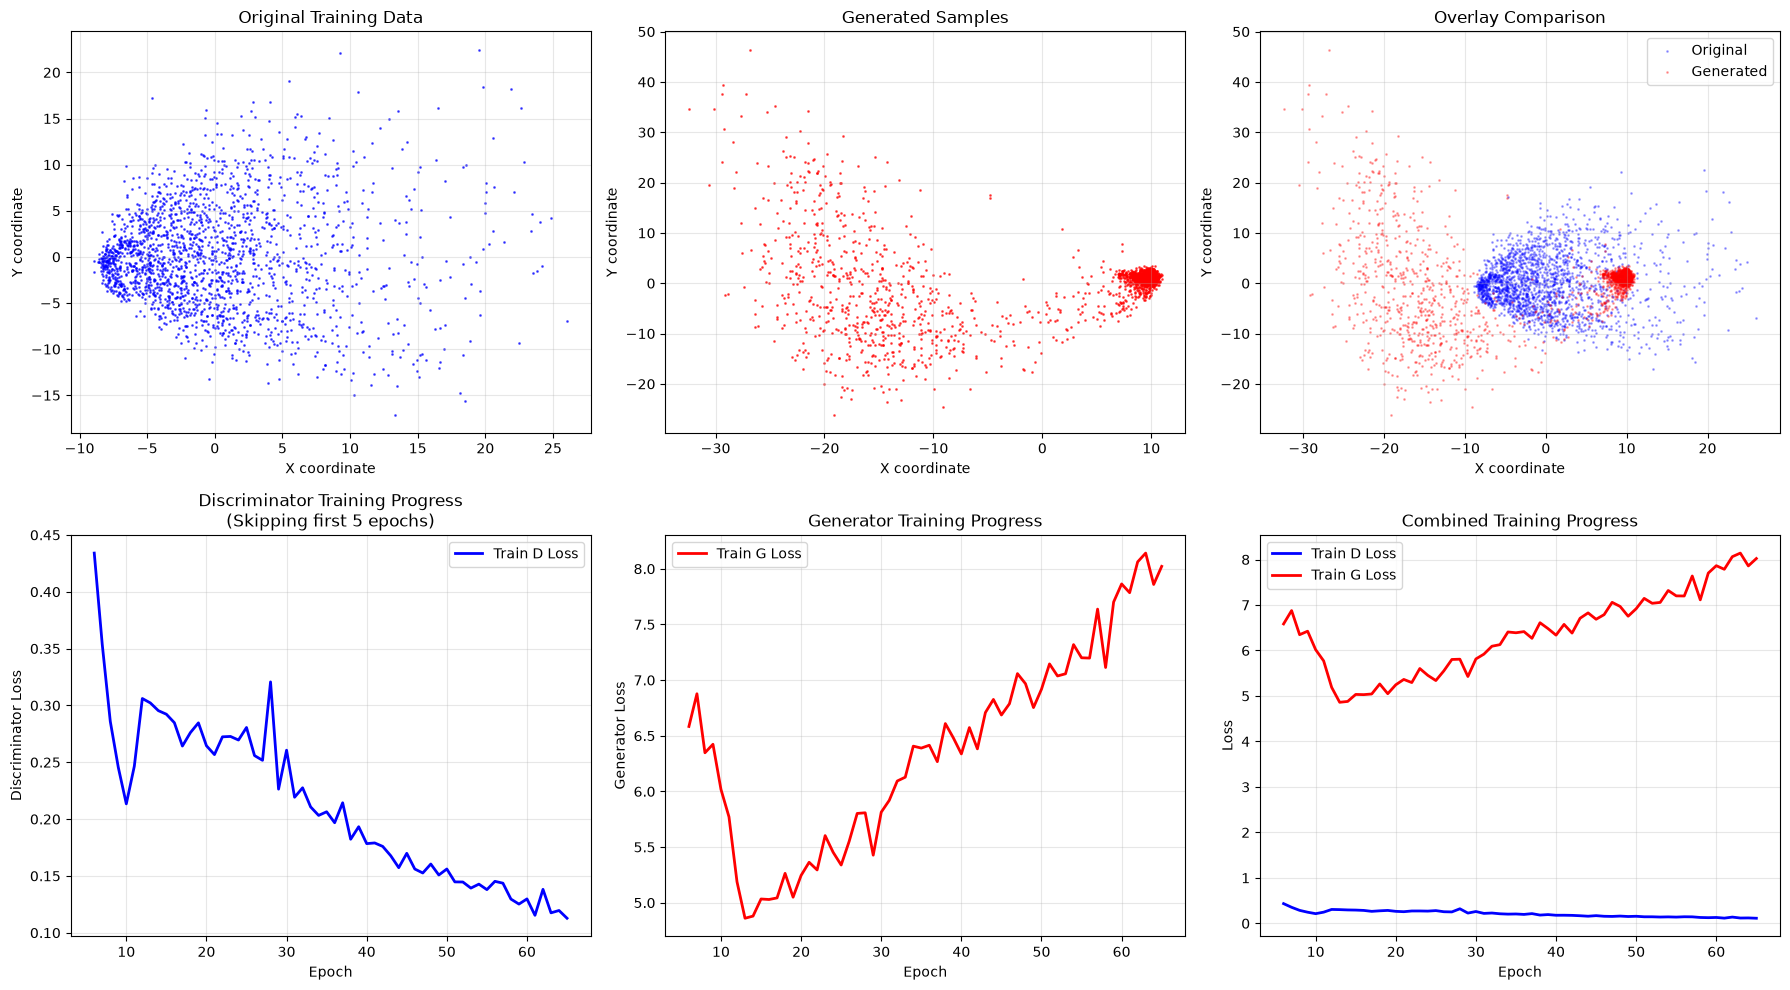

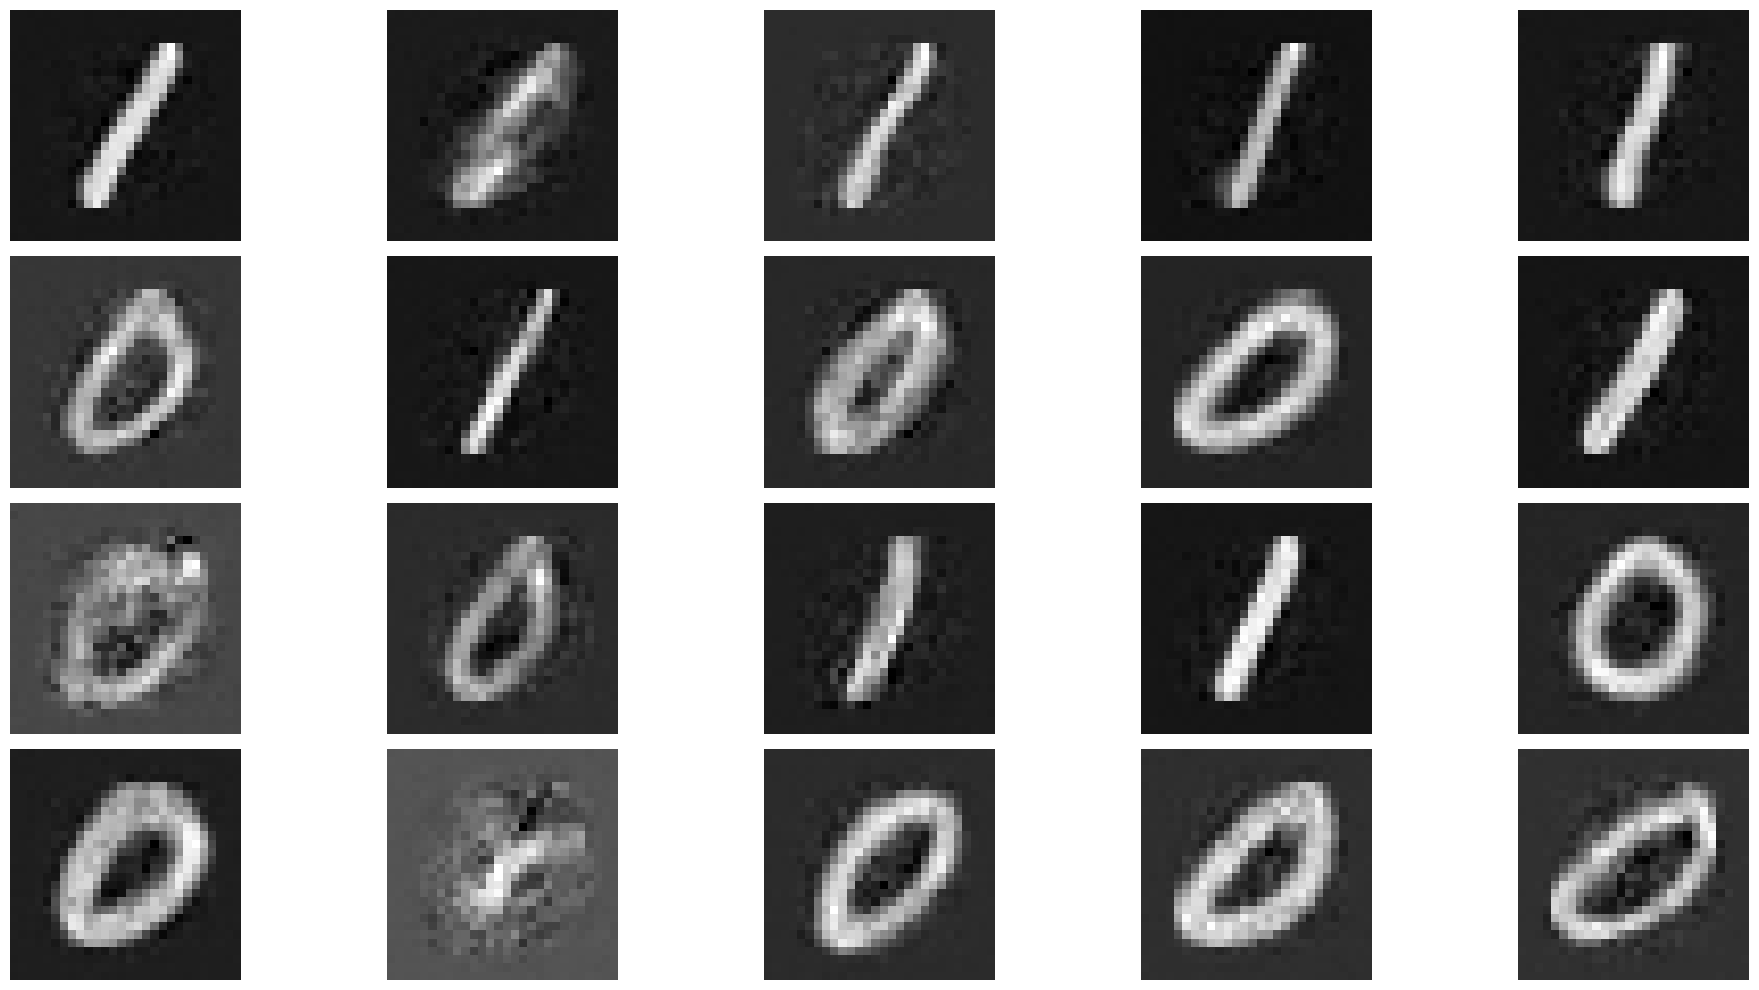

📈 Epoch 65 Summary:
   Train D Loss: 0.1128, Val D Loss: 0.1935
   Train G Loss: 8.0218, Val G Loss: 8.3532

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.202071	G_loss: 8.914177
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.071531	G_loss: 8.550783
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.104626	G_loss: 6.052501
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.124948	G_loss: 7.762764
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.071760	G_loss: 6.300496
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.099305	G_loss: 7.248703
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.064390	G_loss: 5.589495
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.218396	G_loss: 8.192802
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.088929	G_loss: 5.282499
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.117356	G_loss: 6.250186
====> Epoch: 66 Train D_loss: 0.1245, Train G_loss: 8.1425
====> Epoch: 66 Val D_loss: 0.1826, Val G_loss: 7.0315
📈 Epoch 66 Summary:
   Train D Loss: 0.1245, Val D Loss: 0.1826
   Train G Loss: 8.1425

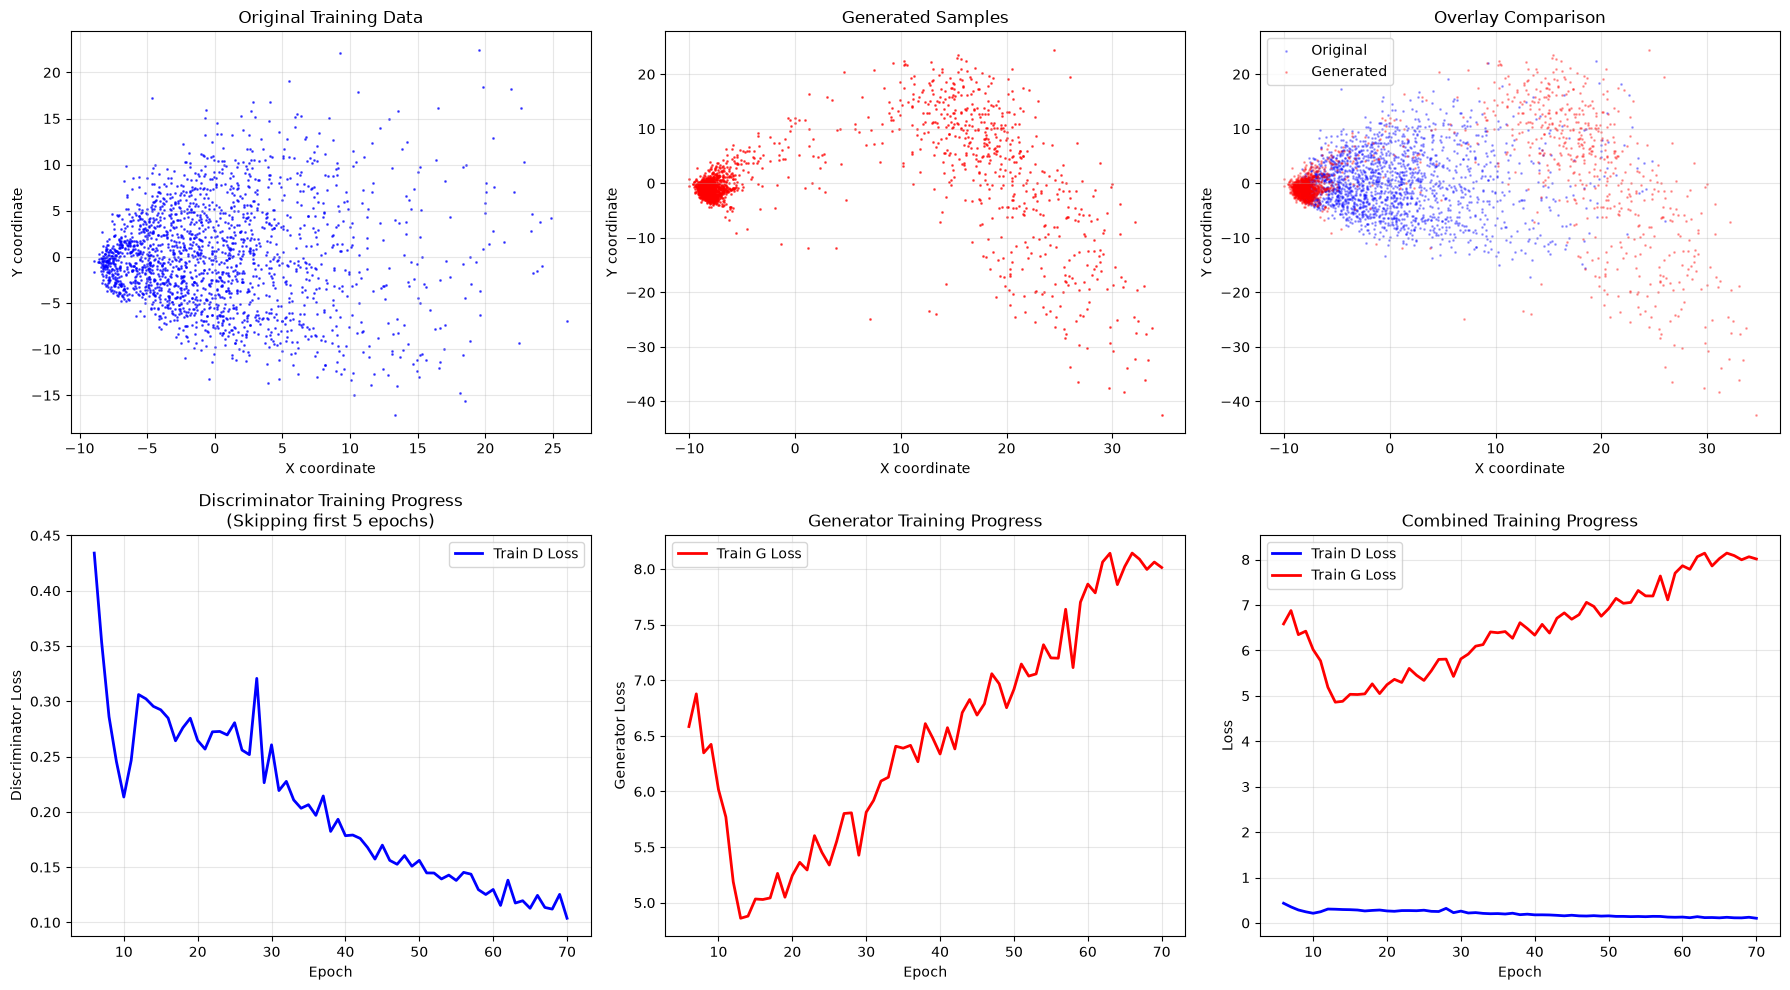

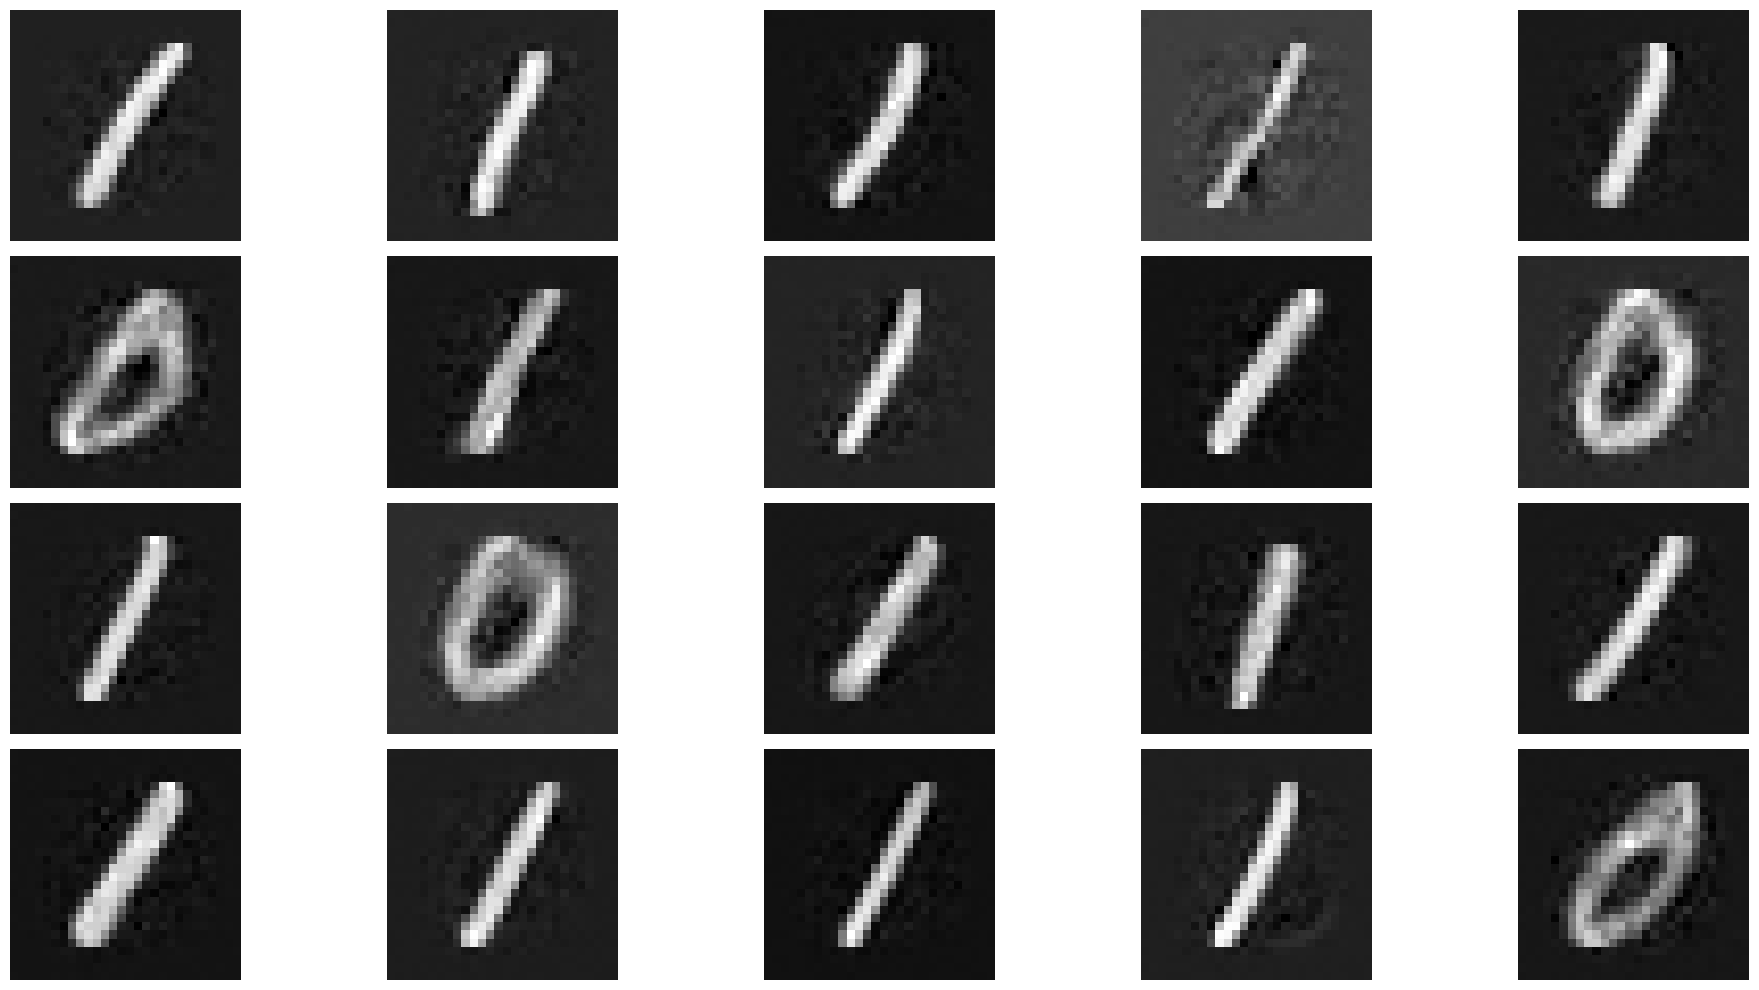

📈 Epoch 70 Summary:
   Train D Loss: 0.1038, Val D Loss: 0.0592
   Train G Loss: 8.0129, Val G Loss: 8.6718

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.018377	G_loss: 8.603172
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.068024	G_loss: 5.688285
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.027570	G_loss: 10.675897
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.121828	G_loss: 7.788549
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.105426	G_loss: 11.009763
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.047486	G_loss: 6.676207
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.046211	G_loss: 11.843728
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.029741	G_loss: 11.979591
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.044163	G_loss: 10.472702
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.088761	G_loss: 5.812360
====> Epoch: 71 Train D_loss: 0.1056, Train G_loss: 8.5112
====> Epoch: 71 Val D_loss: 0.1486, Val G_loss: 4.7096
📈 Epoch 71 Summary:
   Train D Loss: 0.1056, Val D Loss: 0.1486
   Train G Loss: 8

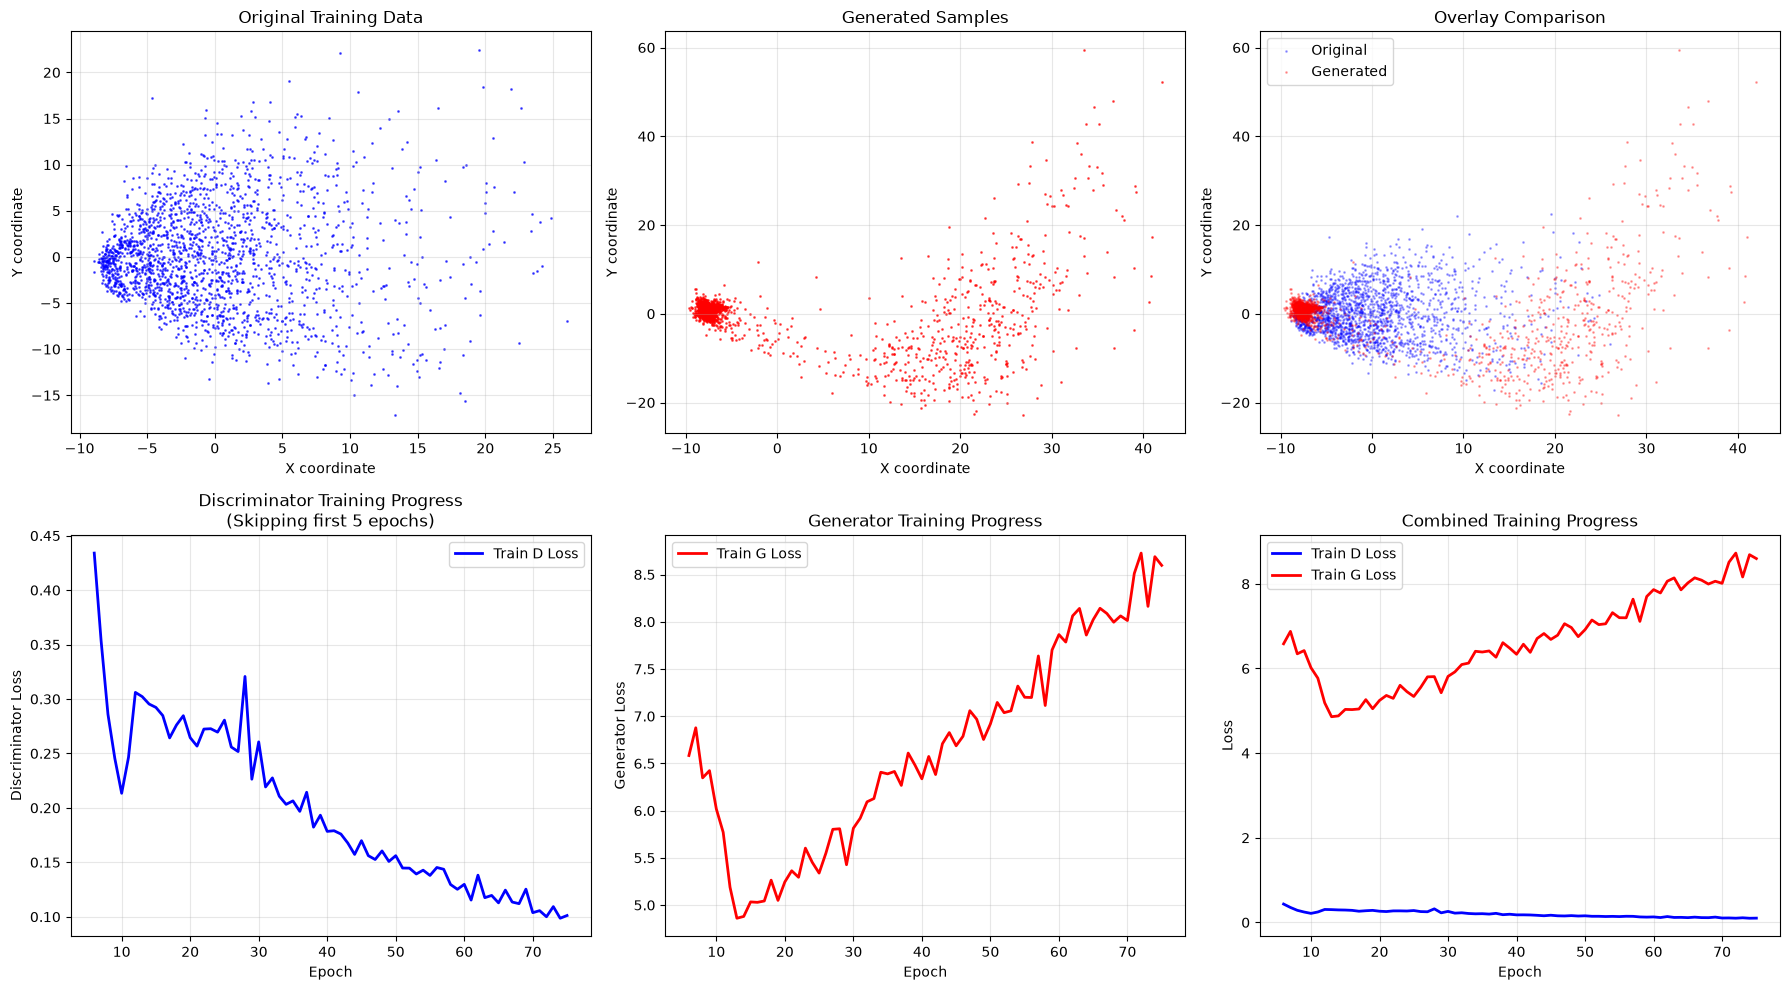

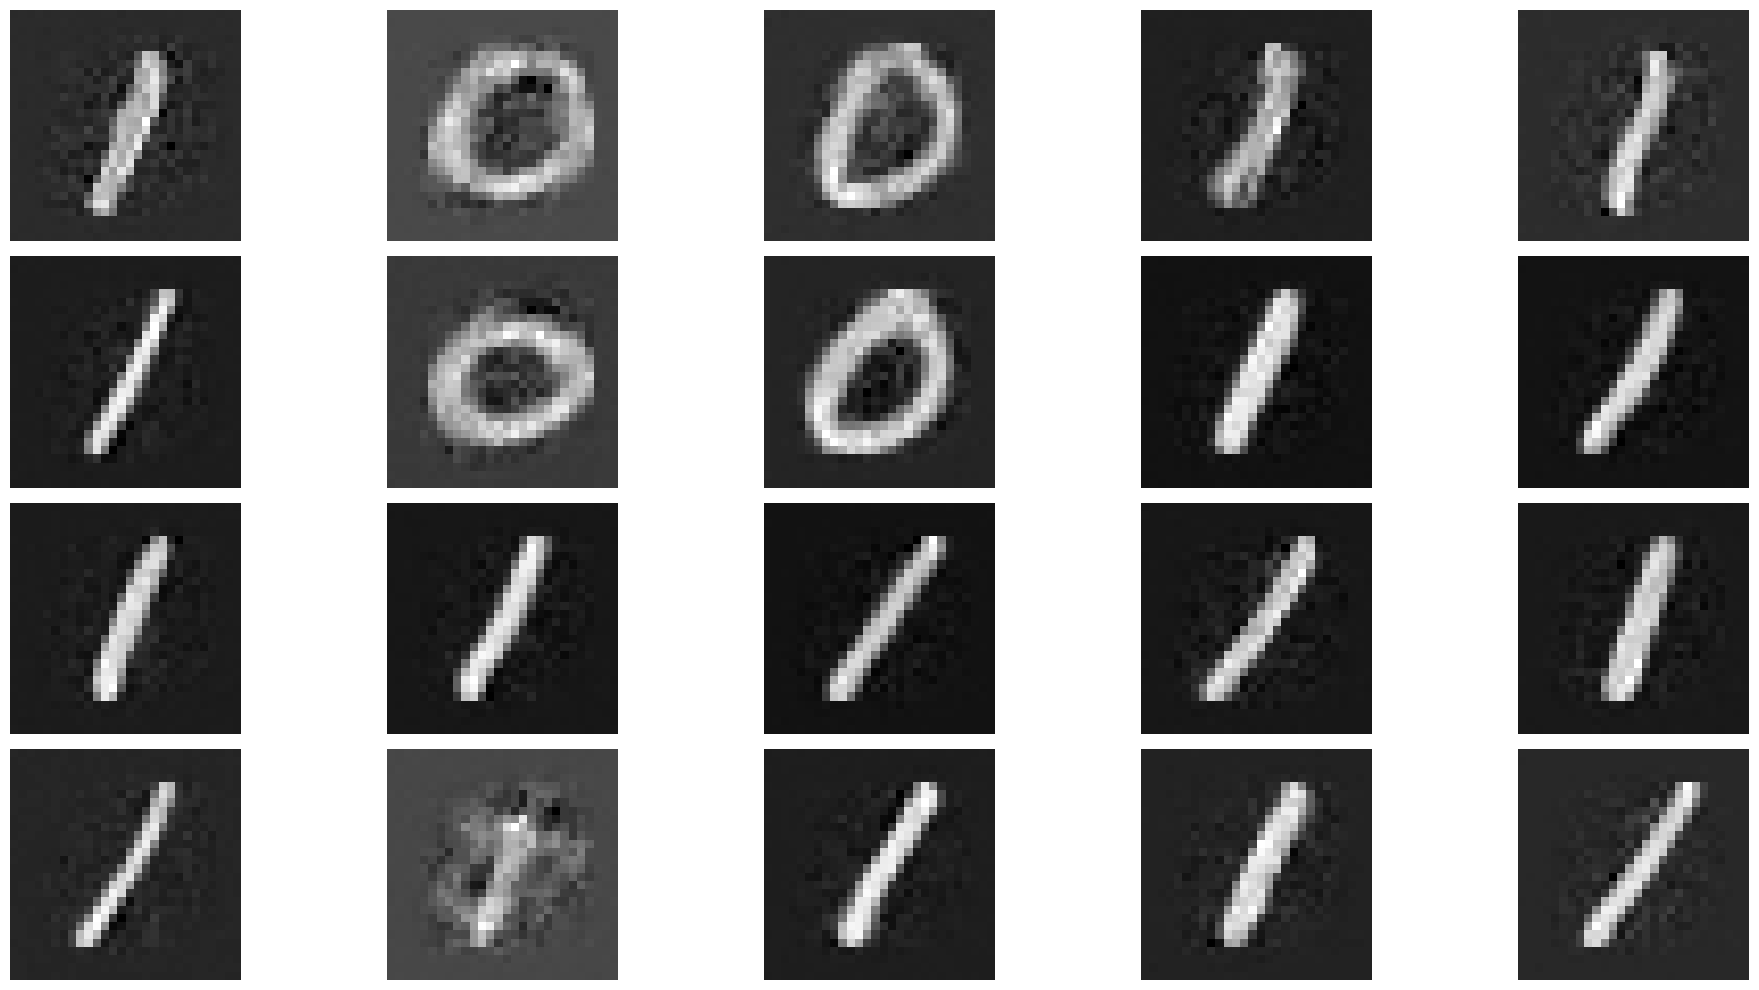

📈 Epoch 75 Summary:
   Train D Loss: 0.1011, Val D Loss: 0.1113
   Train G Loss: 8.5971, Val G Loss: 10.9736

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.072995	G_loss: 10.517145
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.097312	G_loss: 12.729596
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.017166	G_loss: 9.833582
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.102978	G_loss: 5.085505
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.050633	G_loss: 10.788166
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.048682	G_loss: 9.958961
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.063127	G_loss: 13.279016
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.103367	G_loss: 6.257028
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.082384	G_loss: 6.433586
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.161160	G_loss: 8.472982
====> Epoch: 76 Train D_loss: 0.0972, Train G_loss: 8.4165
====> Epoch: 76 Val D_loss: 0.0576, Val G_loss: 8.7416
📈 Epoch 76 Summary:
   Train D Loss: 0.0972, Val D Loss: 0.0576
   Train G Loss: 8

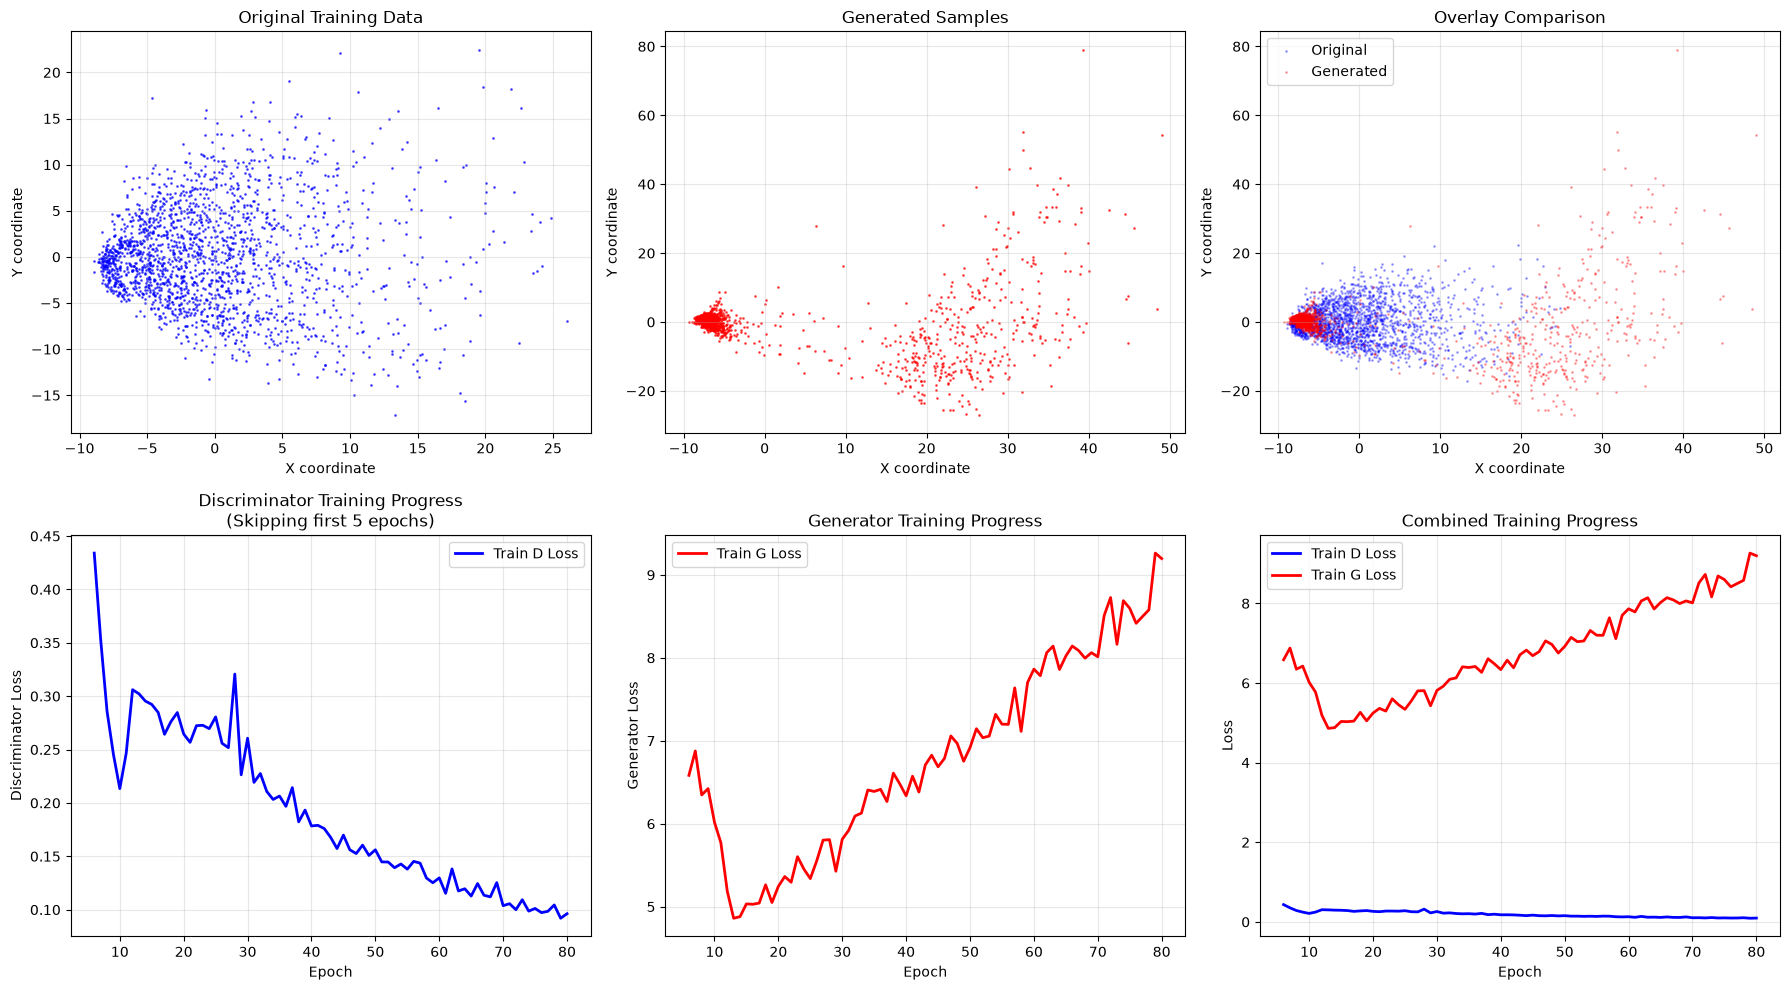

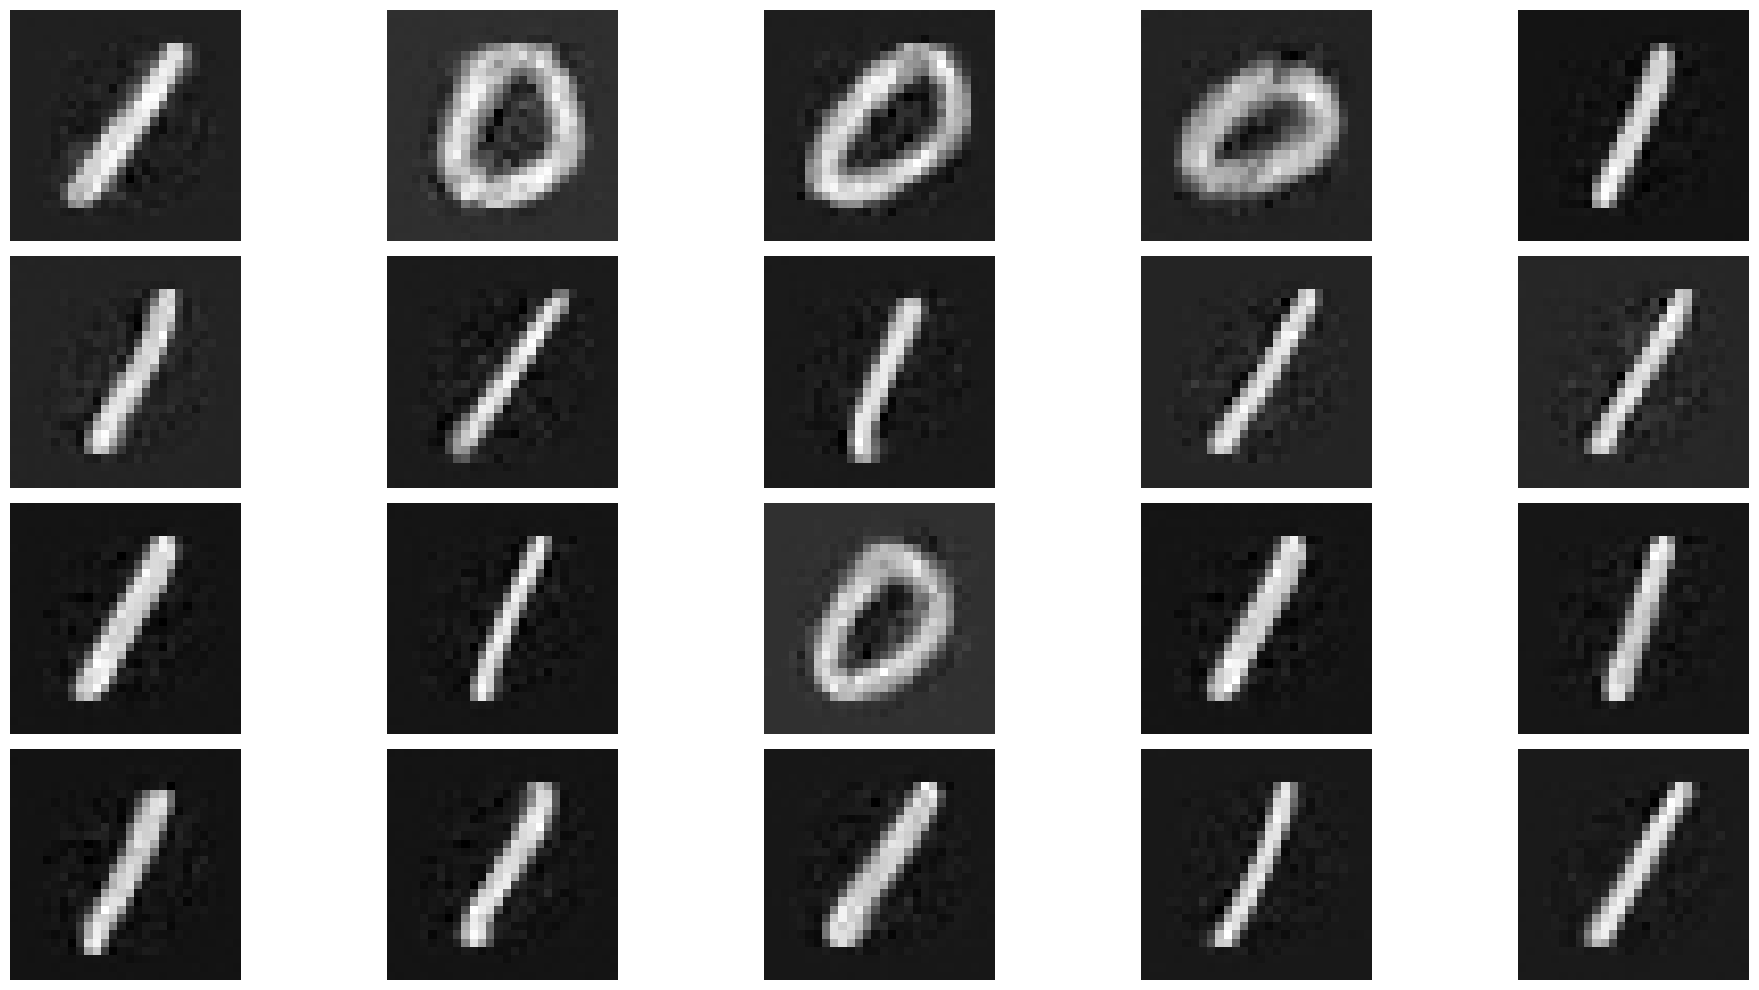

📈 Epoch 80 Summary:
   Train D Loss: 0.0962, Val D Loss: 0.0822
   Train G Loss: 9.1967, Val G Loss: 10.2457

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.058214	G_loss: 10.324951
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.069420	G_loss: 10.246027
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.052041	G_loss: 13.066389
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.163314	G_loss: 10.898033
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.024956	G_loss: 12.848947
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.115962	G_loss: 6.005093
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.037641	G_loss: 12.739704
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.074561	G_loss: 7.178404
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.066046	G_loss: 8.645161
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.149172	G_loss: 10.753511
====> Epoch: 81 Train D_loss: 0.0864, Train G_loss: 9.4204
====> Epoch: 81 Val D_loss: 0.1312, Val G_loss: 7.4264
📈 Epoch 81 Summary:
   Train D Loss: 0.0864, Val D Loss: 0.1312
   Train G Loss

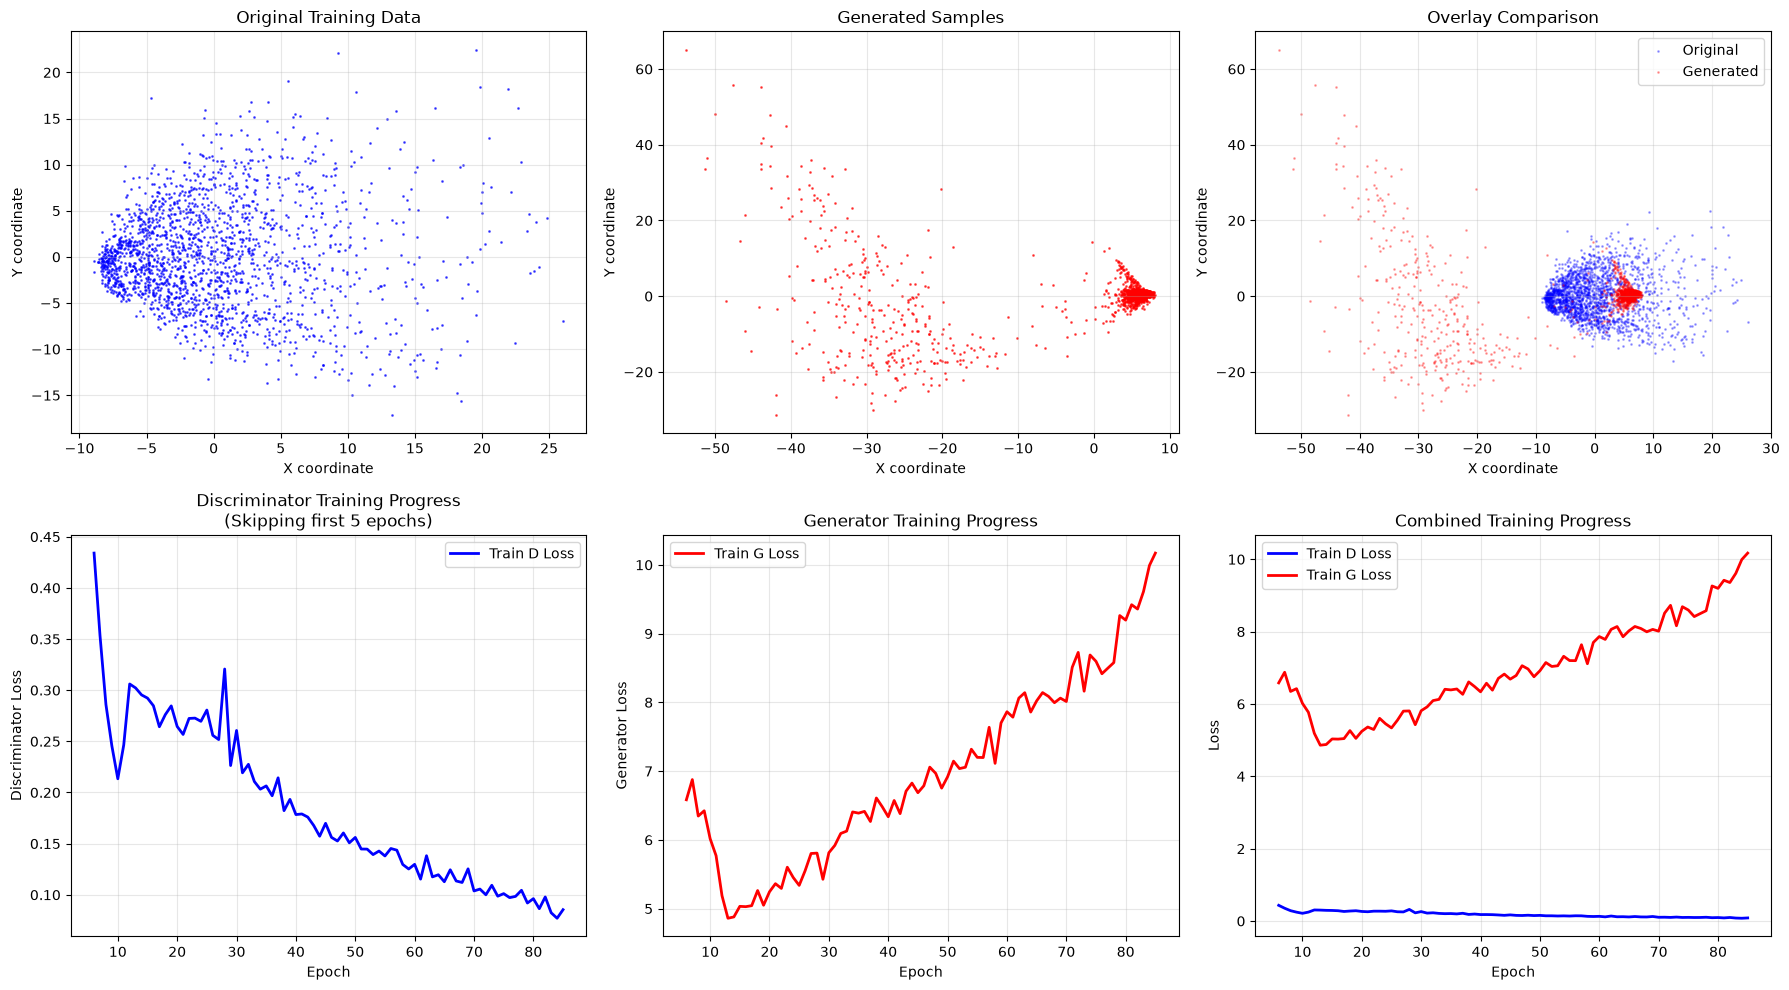

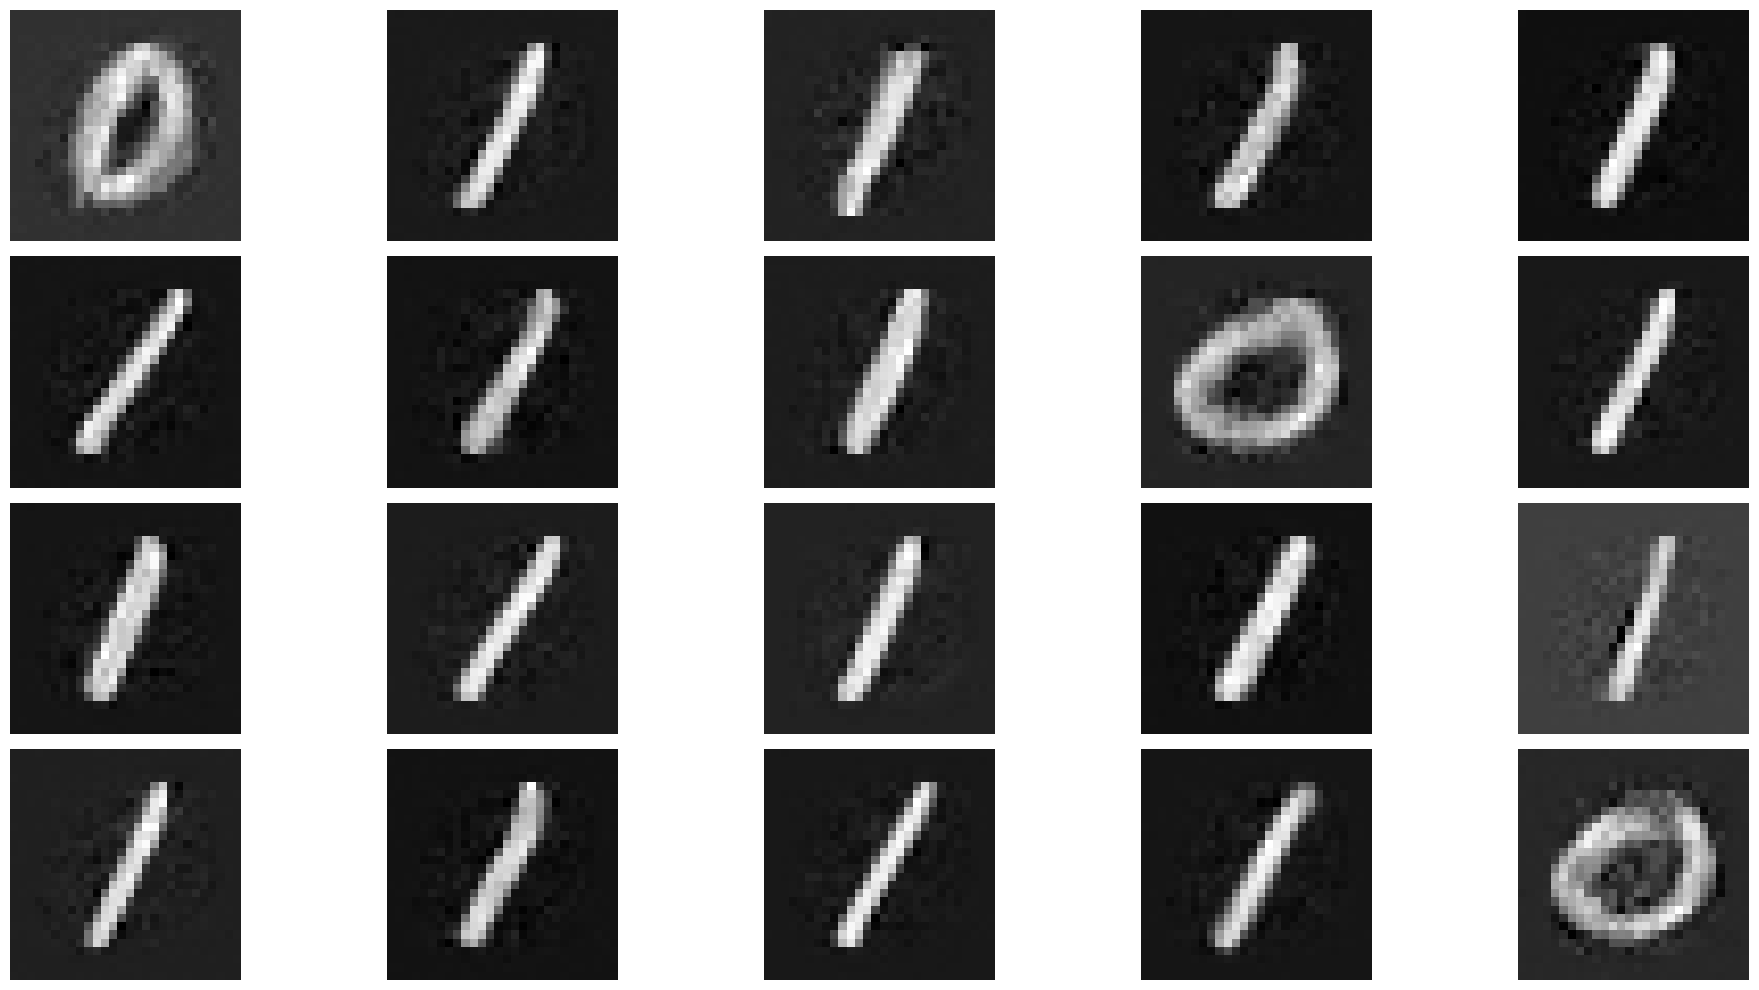

📈 Epoch 85 Summary:
   Train D Loss: 0.0855, Val D Loss: 0.0963
   Train G Loss: 10.1713, Val G Loss: 5.5347

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.111038	G_loss: 6.094382
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.058756	G_loss: 9.058907
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.063936	G_loss: 11.460928
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.062742	G_loss: 9.576845
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.016928	G_loss: 9.589803
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.100313	G_loss: 4.948194
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.124851	G_loss: 8.634778
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.061149	G_loss: 9.987244
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.007679	G_loss: 11.480061
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.048923	G_loss: 9.342588
====> Epoch: 86 Train D_loss: 0.0756, Train G_loss: 9.9752
====> Epoch: 86 Val D_loss: 0.0814, Val G_loss: 8.1864
📈 Epoch 86 Summary:
   Train D Loss: 0.0756, Val D Loss: 0.0814
   Train G Loss: 9.9

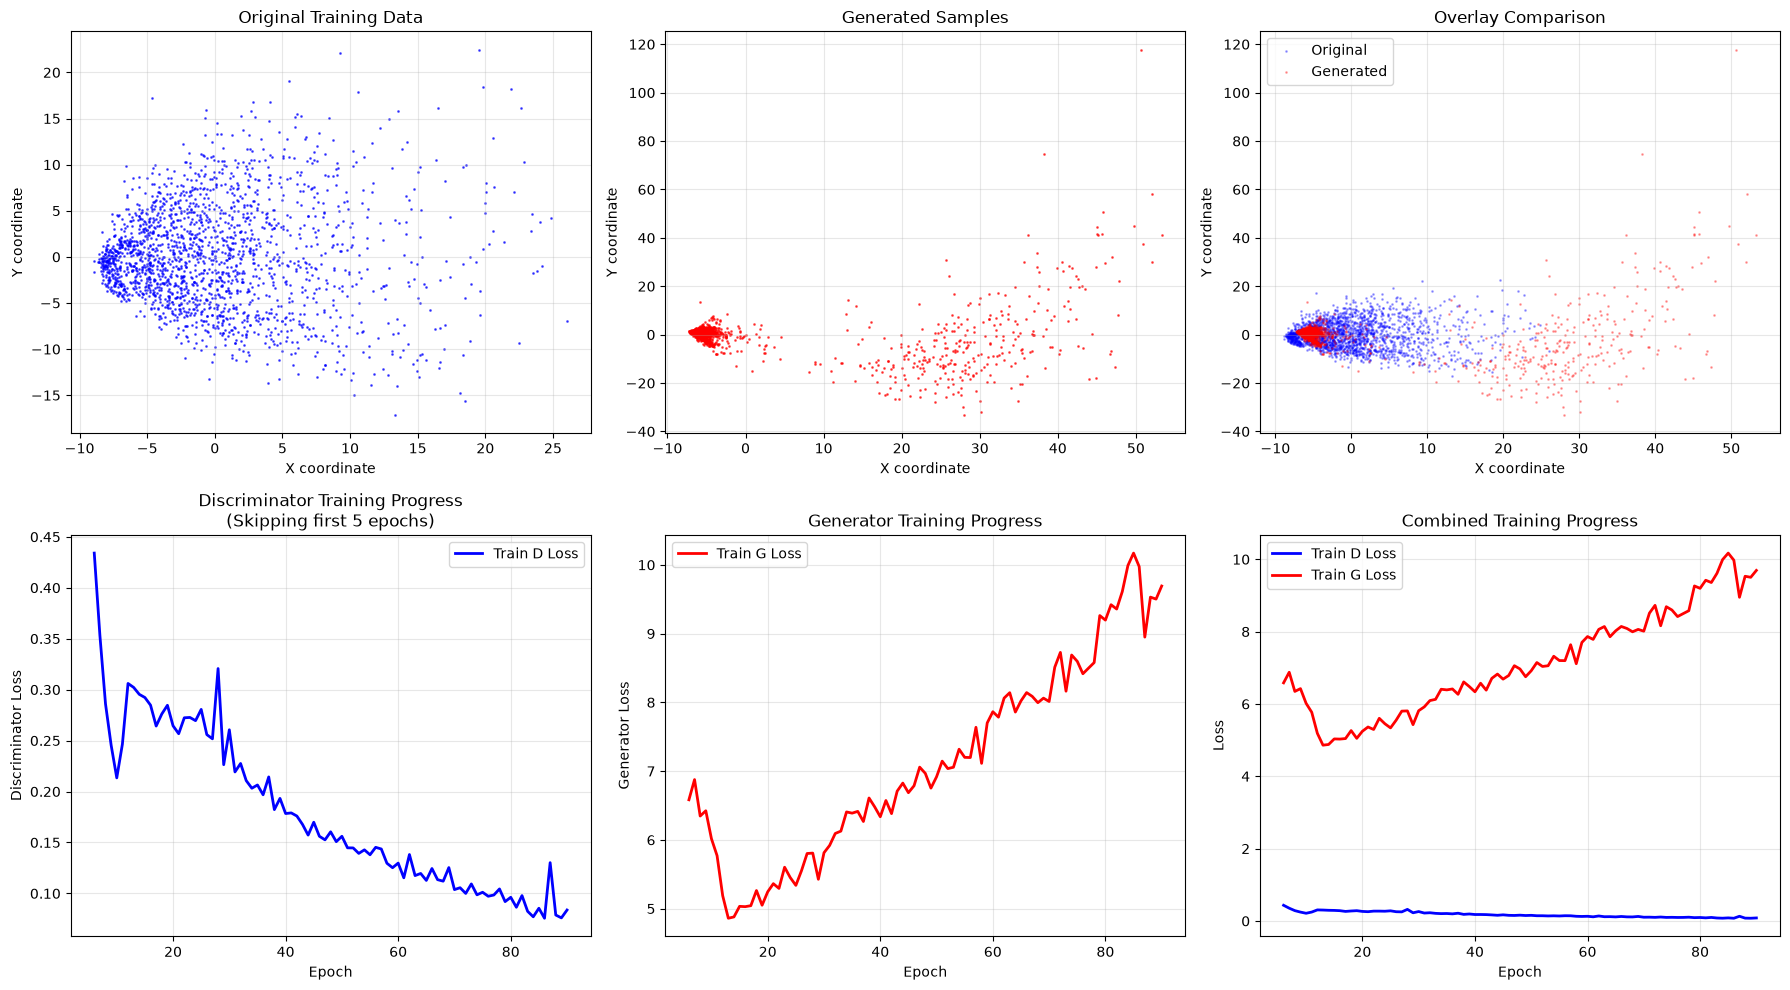

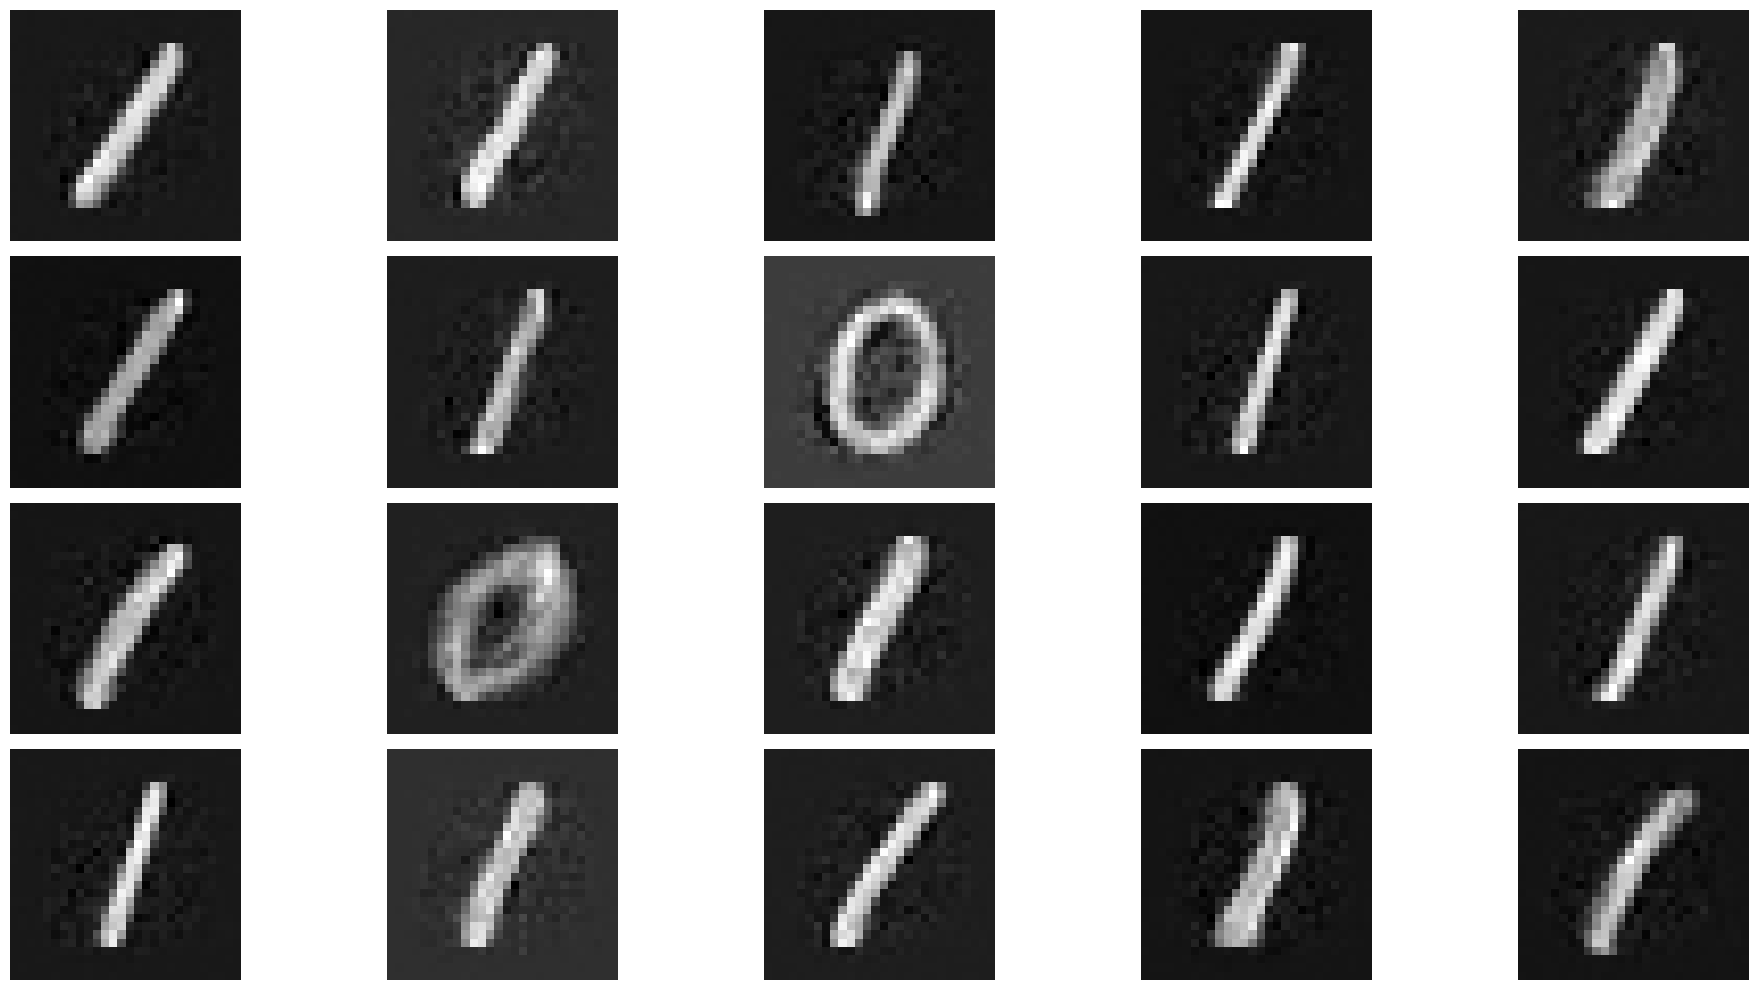

📈 Epoch 90 Summary:
   Train D Loss: 0.0837, Val D Loss: 0.1231
   Train G Loss: 9.6925, Val G Loss: 7.8386

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.060347	G_loss: 8.210679
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.012615	G_loss: 14.244154
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.007962	G_loss: 14.418528
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.052763	G_loss: 8.970117
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.034433	G_loss: 19.014269
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.071912	G_loss: 5.713181
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.113871	G_loss: 10.567052
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.080972	G_loss: 10.087175
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.080960	G_loss: 6.483374
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.090171	G_loss: 11.661978
====> Epoch: 91 Train D_loss: 0.0735, Train G_loss: 10.4177
====> Epoch: 91 Val D_loss: 0.0890, Val G_loss: 18.2168
📈 Epoch 91 Summary:
   Train D Loss: 0.0735, Val D Loss: 0.0890
   Train G Loss

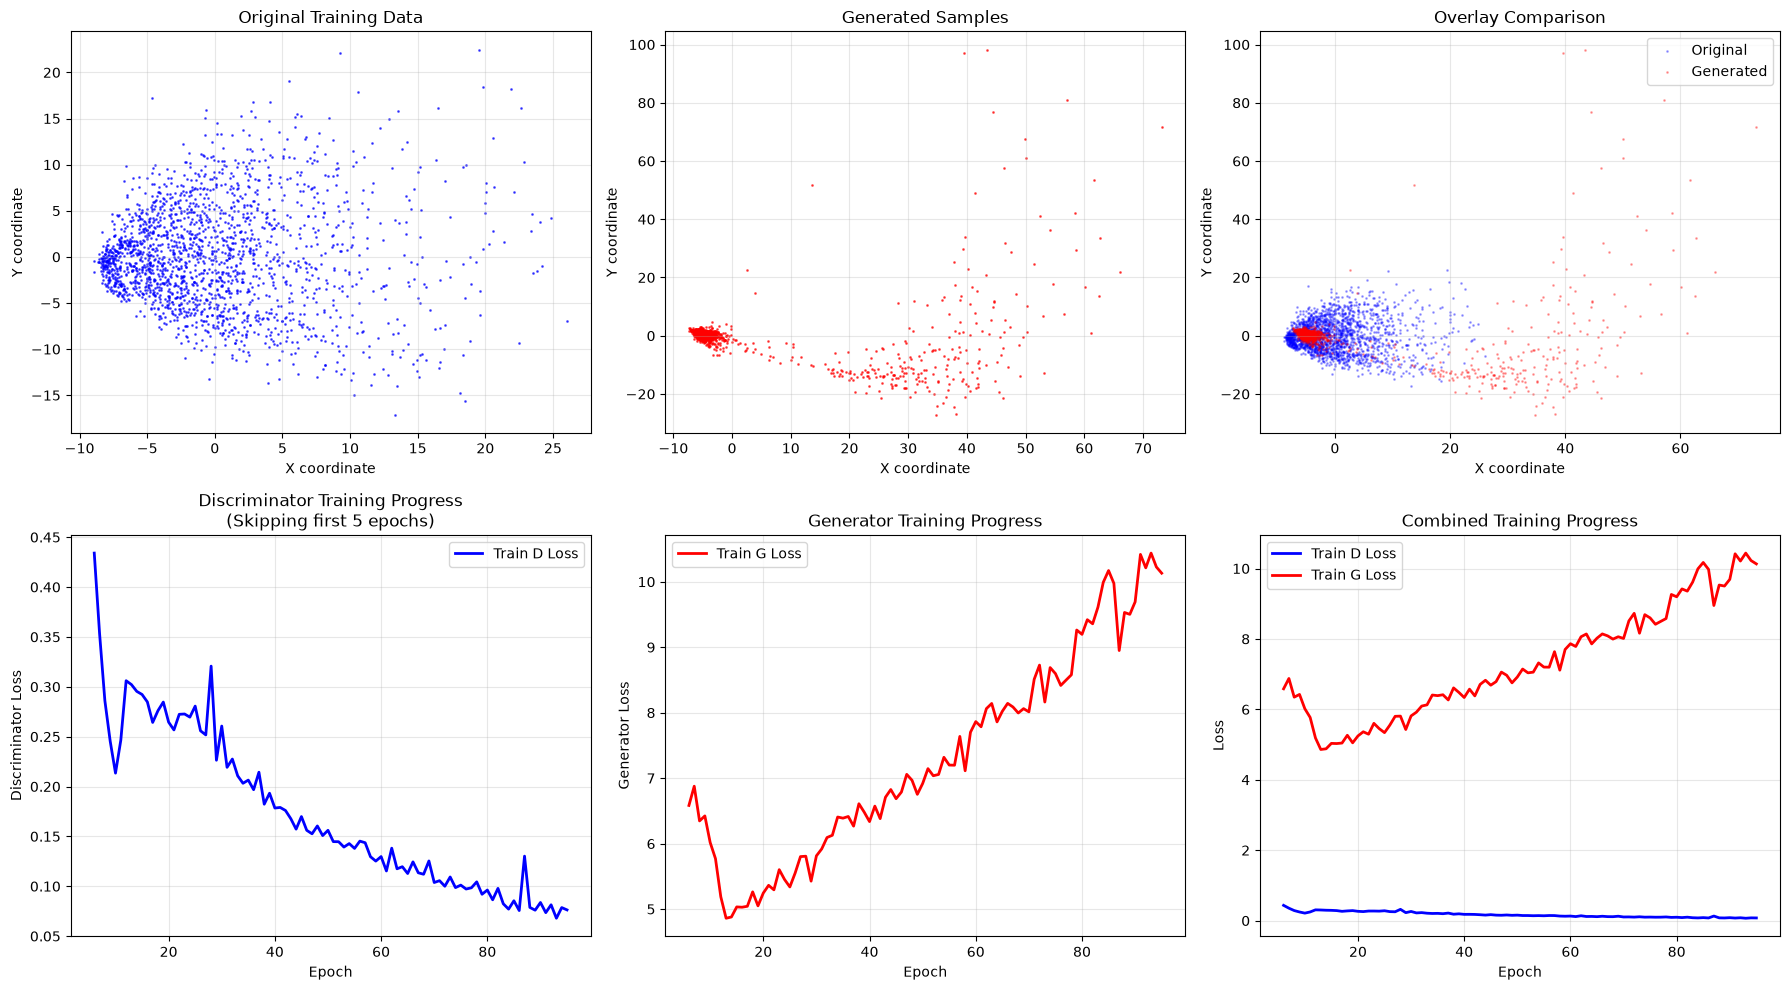

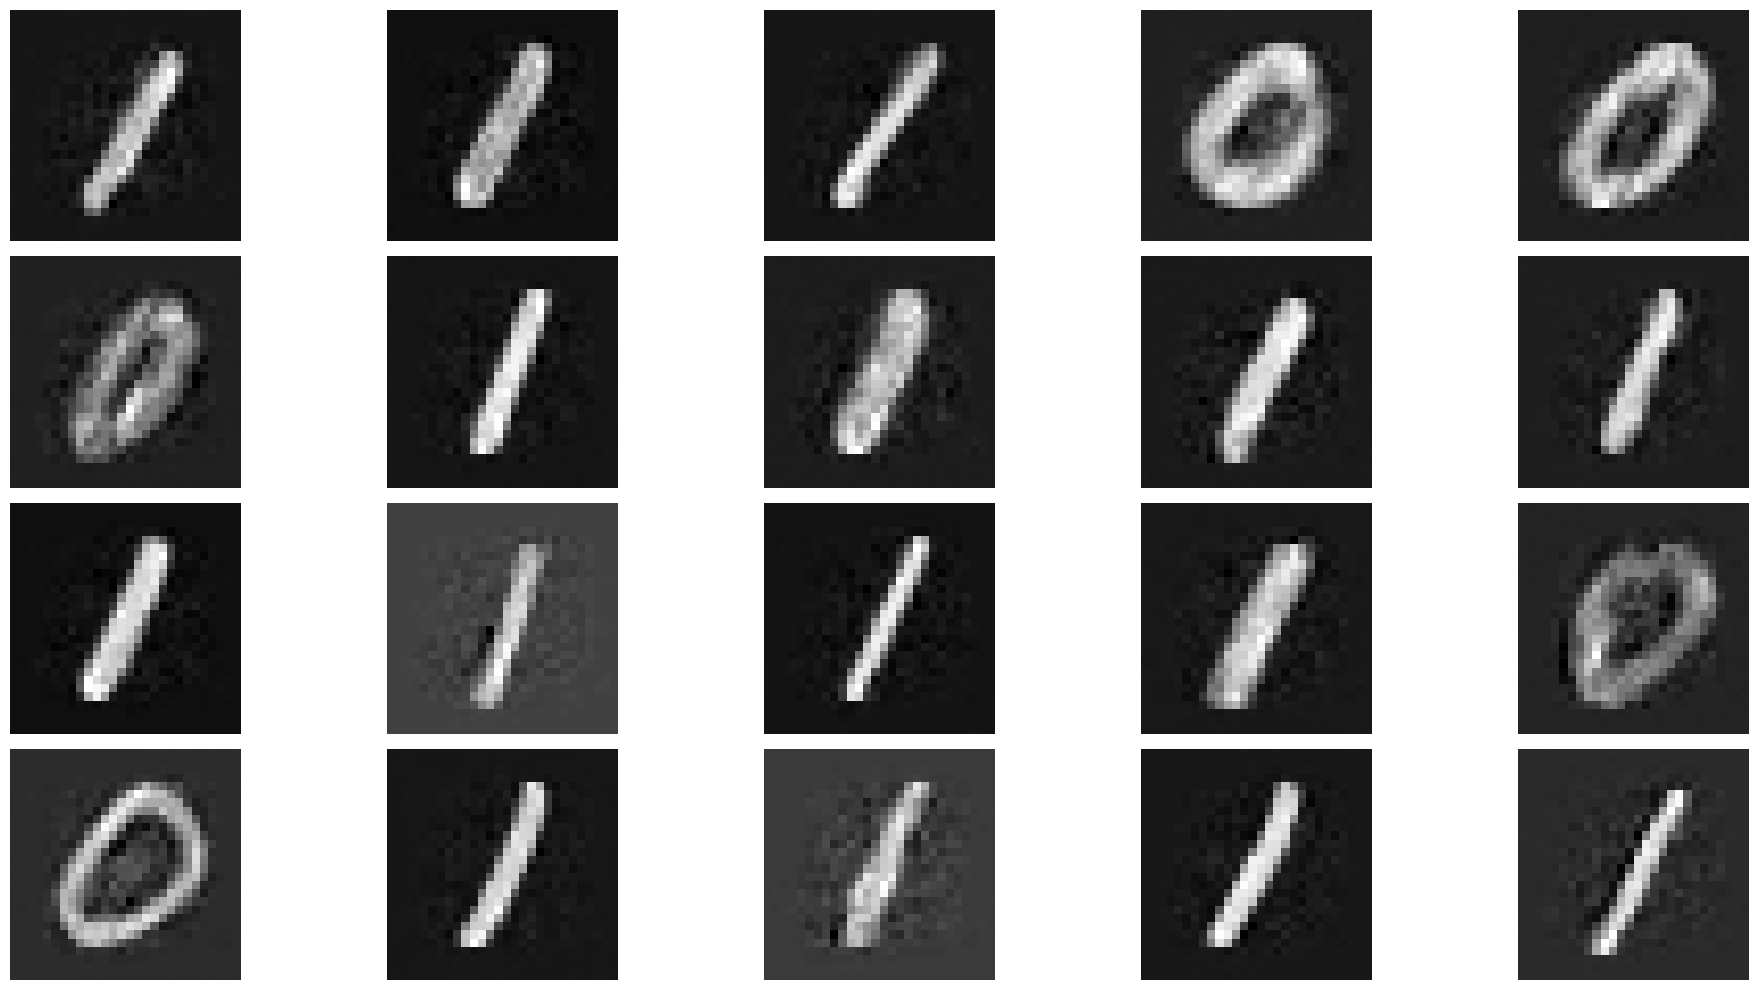

📈 Epoch 95 Summary:
   Train D Loss: 0.0763, Val D Loss: 0.1552
   Train G Loss: 10.1309, Val G Loss: 7.6223

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.056581	G_loss: 9.384540
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.023455	G_loss: 15.347777
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.050267	G_loss: 7.450573
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.033650	G_loss: 16.876259
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.010113	G_loss: 12.587149
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.023919	G_loss: 12.482095
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.076541	G_loss: 12.875469
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.018027	G_loss: 11.328712
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.340144	G_loss: 12.983316
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.088897	G_loss: 8.155344
====> Epoch: 96 Train D_loss: 0.0753, Train G_loss: 10.6902
====> Epoch: 96 Val D_loss: 0.1068, Val G_loss: 7.3778
📈 Epoch 96 Summary:
   Train D Loss: 0.0753, Val D Loss: 0.1068
   Train G Los

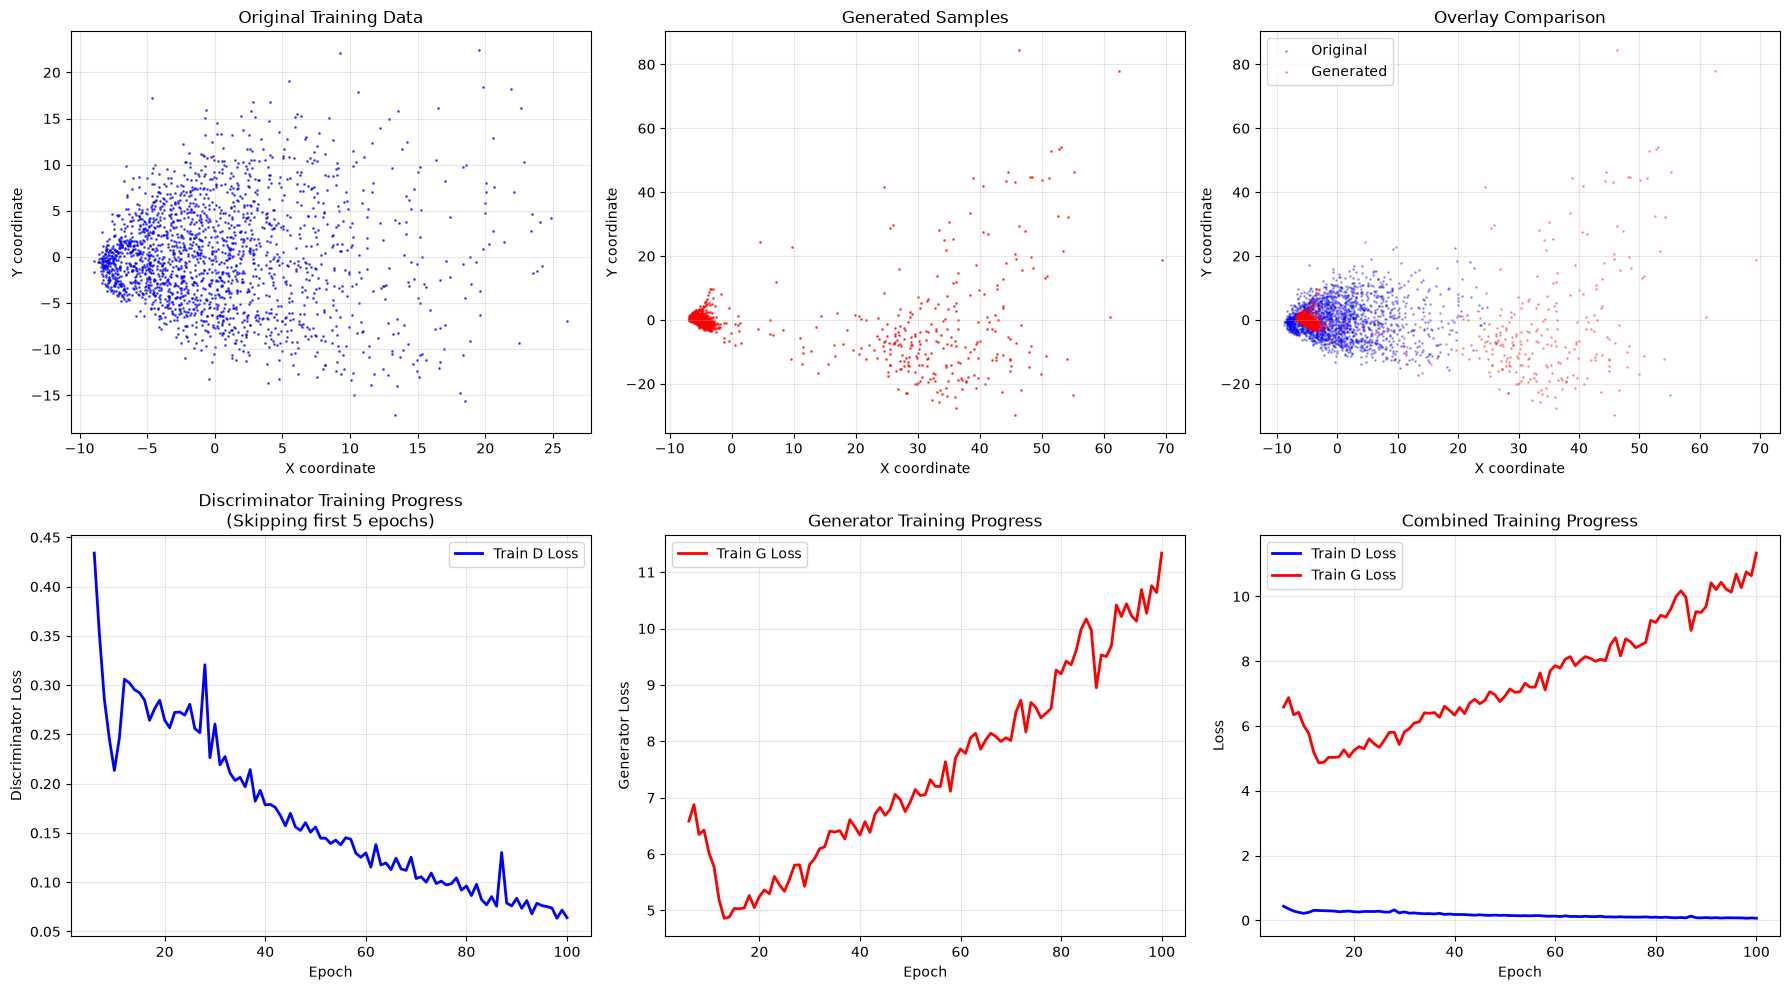

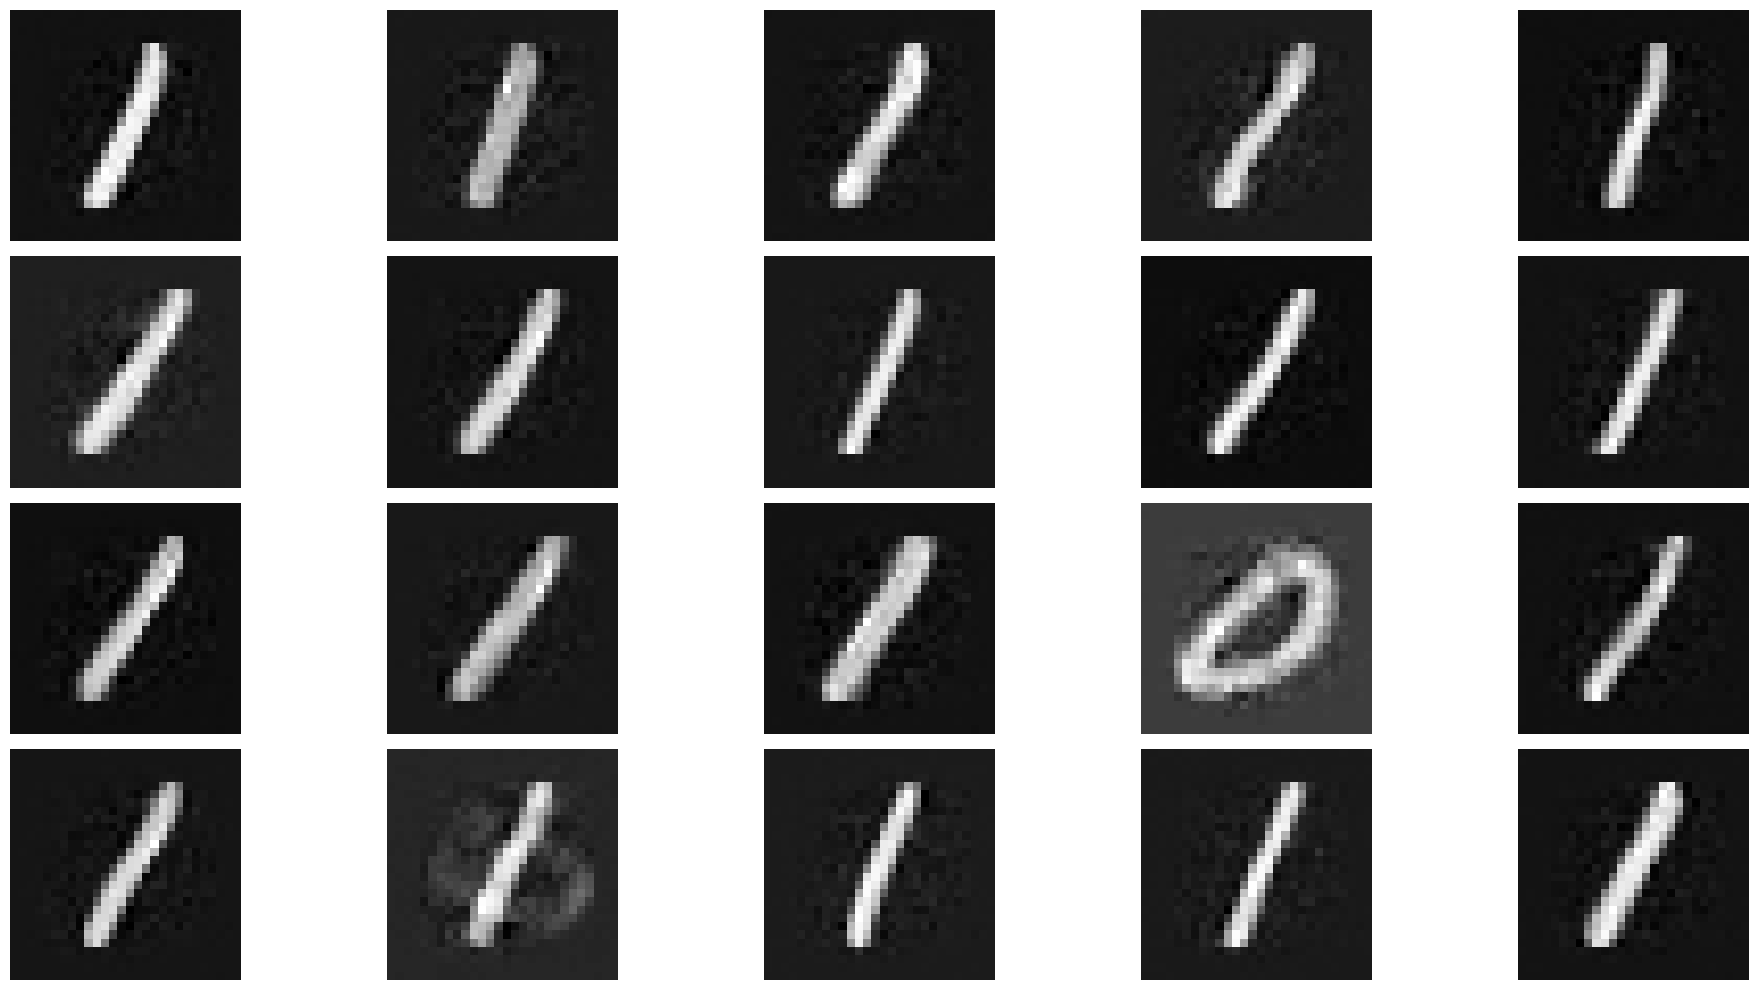

📈 Epoch 100 Summary:
   Train D Loss: 0.0640, Val D Loss: 0.0537
   Train G Loss: 11.3378, Val G Loss: 15.8308

🎉 Training completed!

🎨 Final comprehensive visualization:


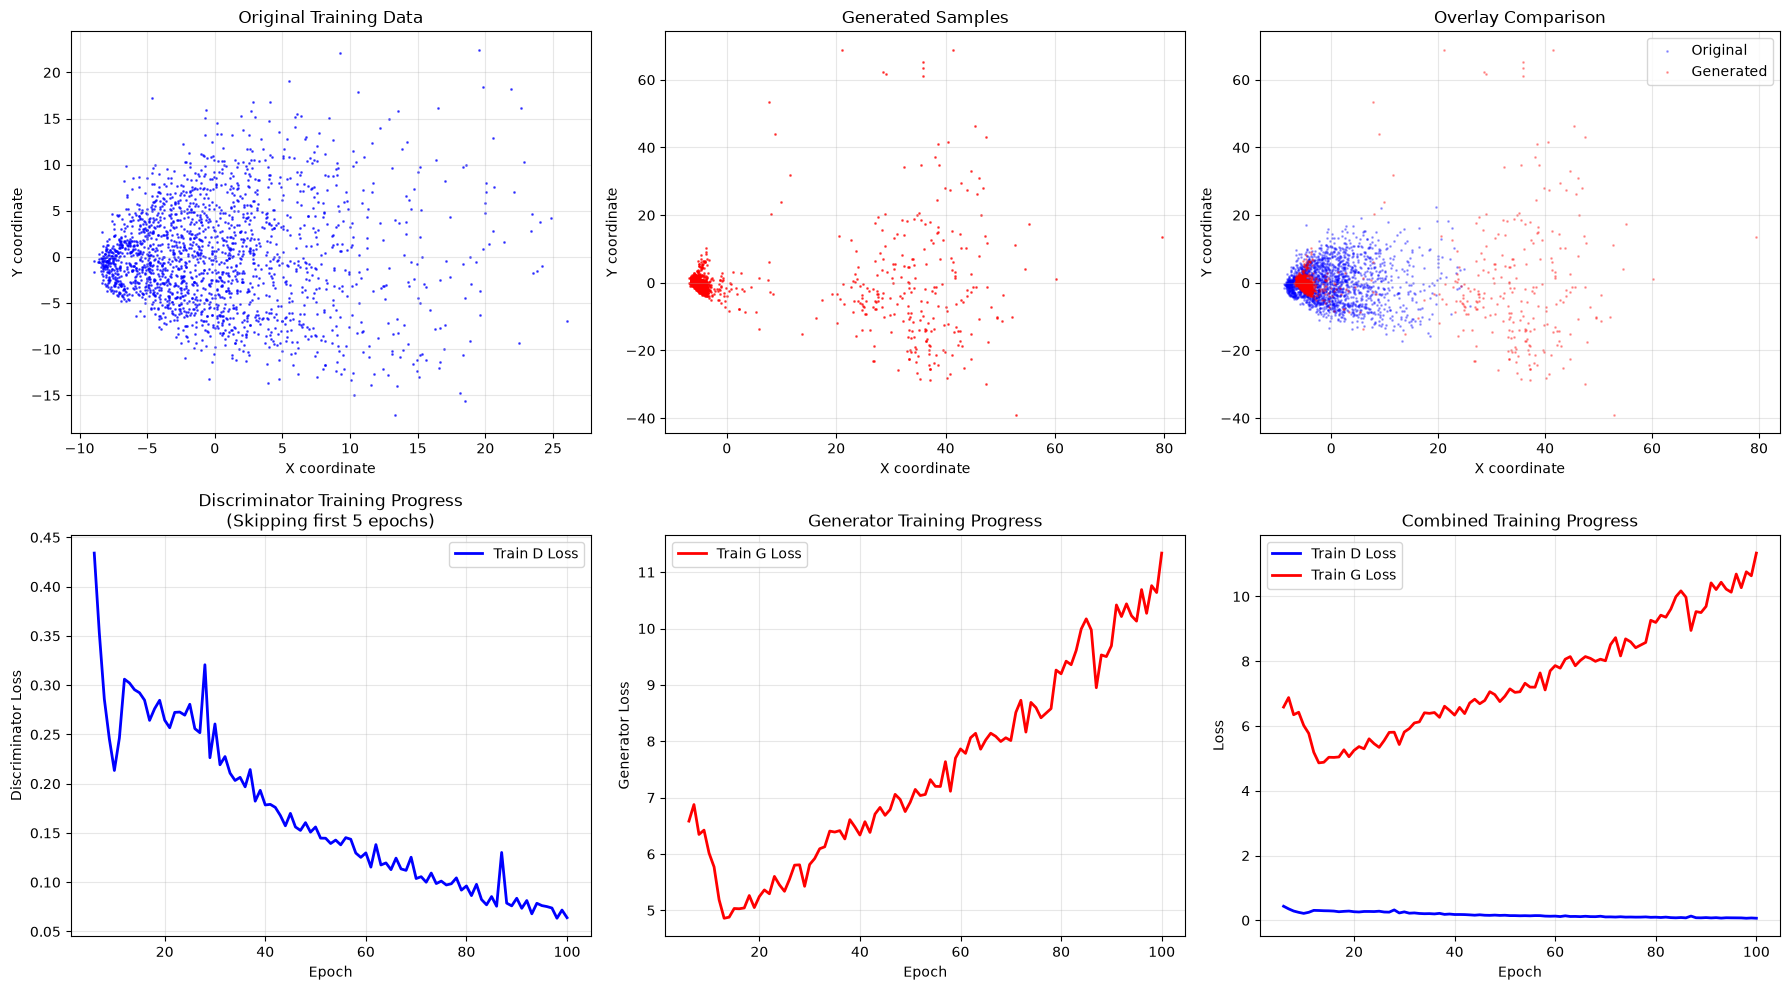

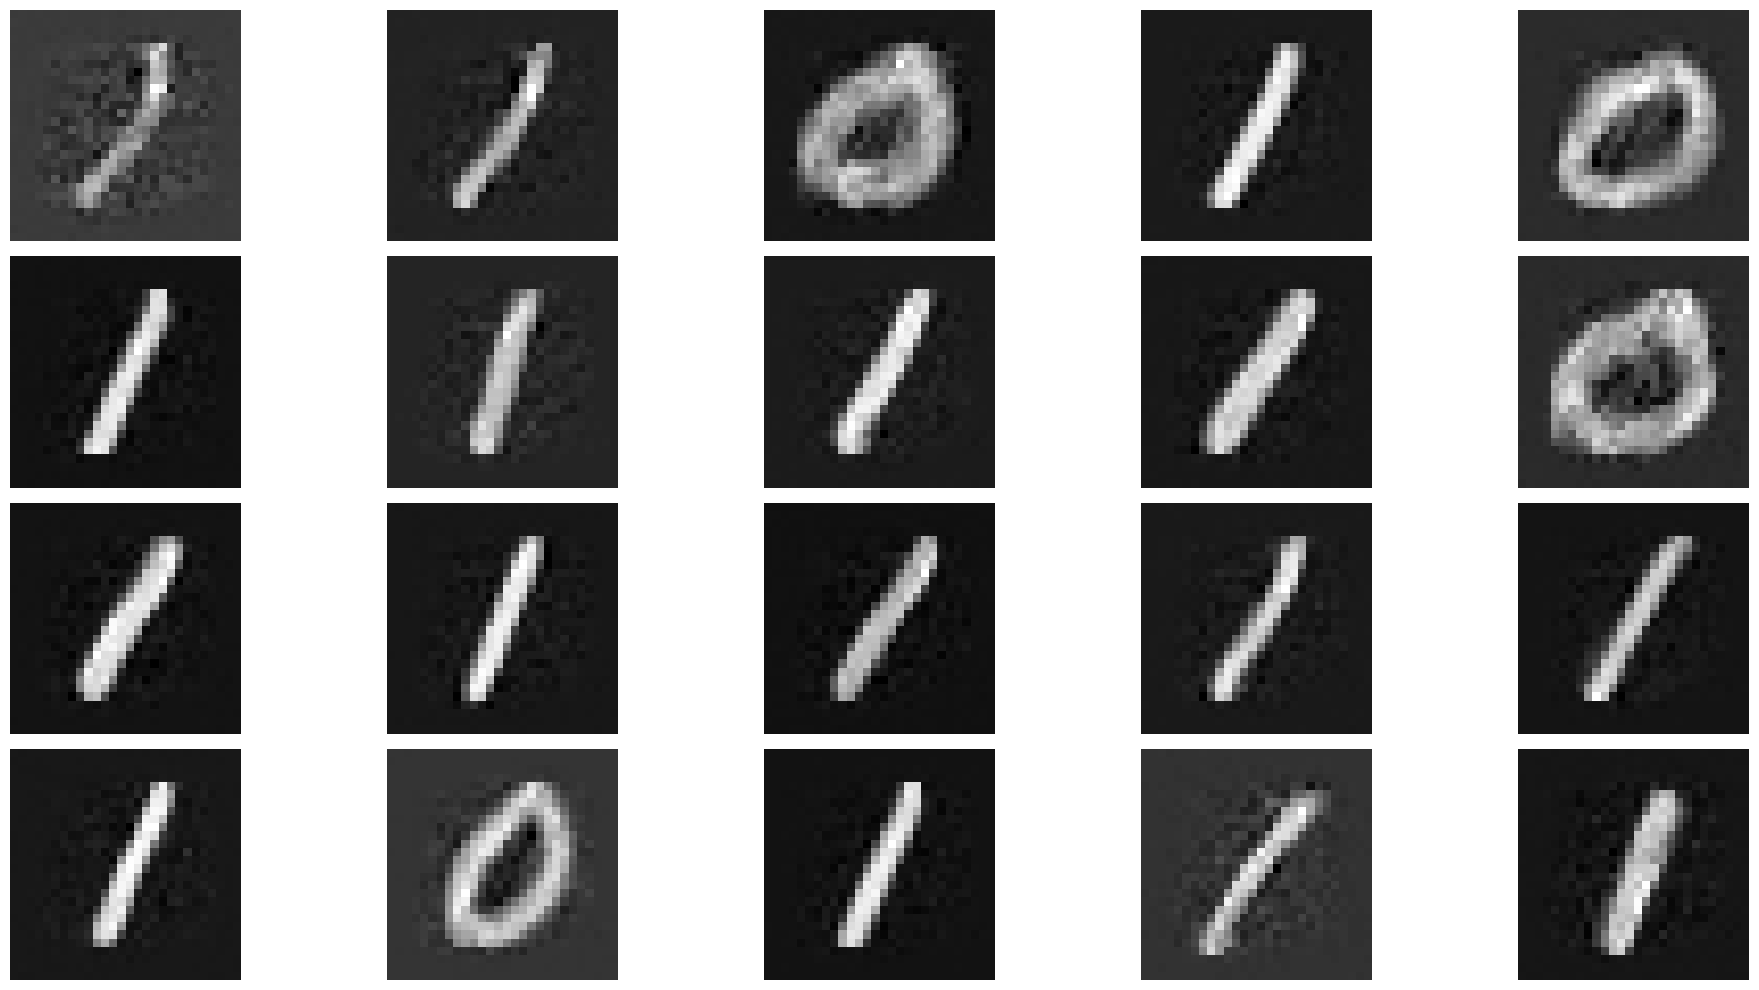

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


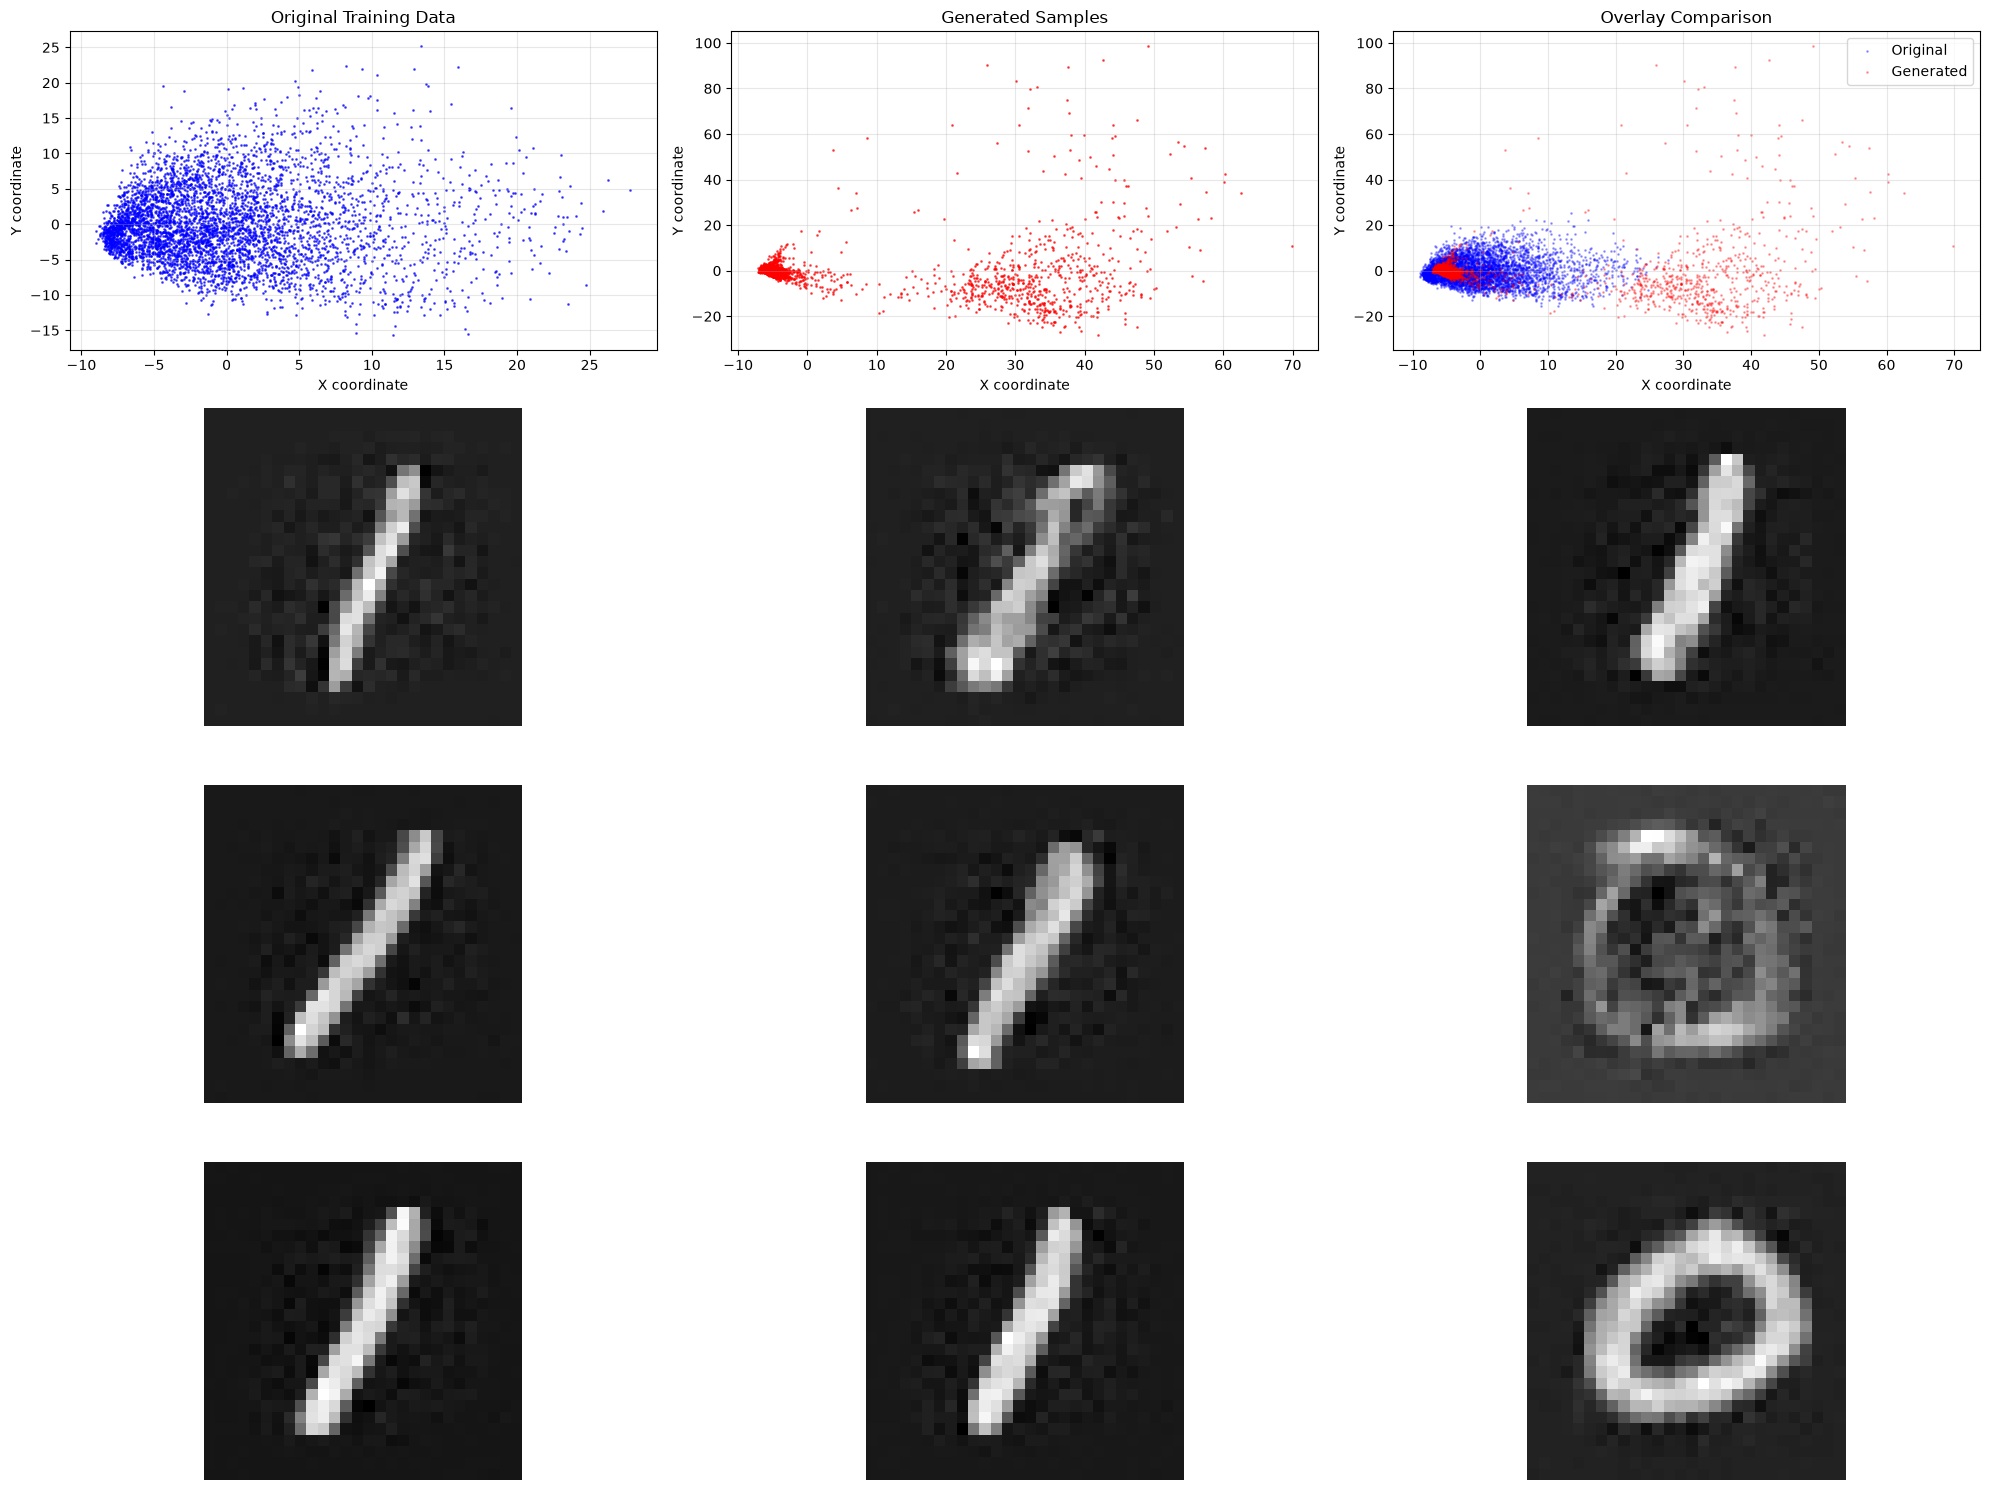

Real data confidence: 0.270
Fake data confidence: 0.001


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].to(device).float()
    real_batch = real_batch.reshape([100, INPUT_DIM])
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
